# Are YES shares on Polymarket systematically overpriced?

## S0 · Summary

**Research question.** Does Polymarket charge too much for YES shares, and would selling them have made money after costs?

**The idea.** A YES share pays $1 if the event happens and $0 if it does not, so its price is the market's guess at the chance: 30 cents means "30% likely". If YES shares priced near 30 cents only pay about 25% of the time, buyers are overpaying for YES. Selling YES (the same as buying NO) would collect that overpayment.

**How the test works.**

1. Take about 30,000 settled Polymarket markets and their price every 12 hours.
2. In each market, find the first time YES trades between 20 and 40 cents. That is one entry.
3. Pretend to sell YES there, paying a small spread (0.5 to 1.5 cents) as the cost.
4. Wait for the market to settle. If YES pays we lose the stake; if it does not we keep the price we sold at.
5. Run all the entries as one book: 0.25% of capital per entry, one per event, no leverage.

**What we check.**

| Question | It passes if |
|---|---|
| Is YES overpriced? (S3) | the average price is above how often YES paid, and the gap is clearly above zero |
| Does selling it earn money? (S3) | the book beats a T-bill after costs |
| Is it just luck? (S4) | a coin-flip version of the data almost never shows a gap this big |
| Does it hold up? (S4) | the second half of the data, higher costs, and losses that arrive together do not change the answer |
| Where does it work? (S4) | in big, busy markets (USD 50,000 or more of volume), where we could trade real size |
| Does selling NO pay too? (S4) | it does not: the gap is about YES, not about selling anything |

**What the test cannot see.** The prices are one sampled price every 12 hours, not an order book, so we do not know what size could really be sold at that price. A backtest only: orders are restricted from the UK, and no rule is chosen or sized.

In [1]:
from IPython.display import Markdown, display
S0_HANDLE = display(Markdown("_The summary card is drawn here when the run finishes._"), display_id=True)

**Are YES shares on Polymarket systematically overpriced?** · **THIN MARKETS ONLY**

**Research question** Does Polymarket charge too much for YES shares, and would selling them have made money after costs?

THIN MARKETS ONLY. The YES side was priced +5.5 points above how often it paid and selling it earned +6.4% an entry, but markets of USD 50,000 and more return -2.0%. Closed by the owner: not taken to a strategy.

**Implementation**

| | |
|:--|:--|
| Study | Exploratory: an effect and a reference book, no chosen rule |
| Sold | YES at its first 12 h print in 20% to 40%; hold to payout |
| Venue | Polymarket settled binary markets; paper only, UK orders restricted |
| Capital | 0.25% of capital a position, posted in full, no leverage |
| Costs | Half-spread 0.5 to 1.5 cents by volume [U], no fee [1] |
| Window | 2024-02-15 to 2026-10-02, 23,040 h; 56% close Nov 2025 to Mar 2026 |

**The numbers that matter**

| At | Metric | Value | Bar | |
|:--|:--|--:|:--|:--|
| 20-40% | Price minus how often it paid, points | +5.5 pt | above 0 | PASS |
| entries | Return an entry, after costs | +6.4% | T-bill +0.2% in 19 days | PASS |
| 1x | Return a year on capital | +29.9% | T-bill 4.11% | PASS |
| USD 50k+ | Return an entry, final volume USD 50k+ | -2.0% | 90% CI -4.2% to +0.1% | FAIL |

**The premium**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Entries in the band | 9,499 |  |  |
| Price minus how often it paid, points | +5.5 pt | above 0 | PASS |
| t statistic, by whole events | 12.2 |  |  |
| p, premium by whole events | 0.00025 | below 0.10 | PASS |
| Later half, price minus how often it paid | +5.3 pt | above 0 | PASS |
| Quarters with a positive premium | 100% | 8 quarters |  |
| Tokens that expired worthless | 75.2% | priced 30.3% |  |

**Reference book, after costs**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Positions taken | 6,511 | of 9,499 entries | INFO |
| Return a position taken | +4.8% | T-bill +0.2% in 18 days | PASS |
| Capital posted, average | 30.0% | cap 100% | INFO |
| Return a year on capital | +29.9% | T-bill 4.11% | PASS |
| Return before costs, a year | +39.8% |  |  |
| Sharpe over the T-bill | 2.56 |  |  |
| Stress costs, a year on capital | +16.5% | T-bill 4.11% | PASS |
| Break-even half-spread, entry | 5.4 | cents each way |  |
| Break-even half-spread, book | 4.0 | cents each way | INFO |

**Is it real**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Sharpe over the T-bill, 90% interval | 1.59 to 3.57 | above 0 | PASS |
| Lower end, cluster interval | +5.0% | above 0 | PASS |
| Independent bets, by event | 9,107 | of 9,499 entries | INFO |
| Worst case, dropped markets lose | +0.5% | above 0 | PASS |
| Entries a leak check changes | 0% | 4 of 4 planted caught | PASS |
| Empty histories dropped | 1,739 | 5.4% of draw | INFO |

**Where it lives**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Return an entry, USD 50k+ | -2.0% | 90% CI -4.2% to +0.1% | FAIL |
| Return an entry, under USD 50k | +9.7% |  | INFO |
| Live candidates under USD 10k | 92% | of 4,685 in the band | INFO |
| Return an entry, sports | +4.6% | 90% CI +3.1% to +6.1% | INFO |
| Return an entry, politics | +4.6% | 90% CI +1.7% to +7.5% | INFO |
| Return an entry, crypto | +8.3% | 90% CI +5.4% to +11.0% | INFO |
| Return an entry, other | +11.8% | 90% CI +9.5% to +13.9% | INFO |

**Does the rule matter**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Books in the grid | 256 | every one kept | INFO |
| Books above the T-bill, both halves | 100% | at least 75% | PASS |
| Rank correlation, early vs later | 0.00 |  | INFO |
| Category cap 20%, later-half return | +58% | T-bill 4.11% | INFO |
| Category cap none, later-half return | +87% | T-bill 4.11% | INFO |

**Risk, reference book**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Maximum drawdown | 5.5% | line 5% | FAIL |
| Worst resolution day, losses only | -8.09% | line 5% | FAIL |
| Open in one category, peak | 66.2% | no cap set | PASS |
| Ten worst events, share of loss | 1% |  | INFO |

**Size**

| Final volume, USD | Entries | Return an entry | 90% interval | Verdict |
|:--|--:|--:|--:|:--|
| 1,000 to 10,000 | 3,882 | +12.6% | +11.0% to +14.2% | PASS |
| 10,000 to 50,000 | 2,889 | +6.0% | +3.8% to +7.7% | PASS |
| **50,000 to 200,000** | **1,640** | **-3.0%** | **-5.6% to -0.1%** | **FAIL** |
| 200,000 and up | 1,088 | -0.5% | -3.9% to +2.8% | FLAG |

Closed by the owner on 2026-10-06: not taken to a strategy study or to production.  
Not shown: a tradable edge. In USD 50k+ markets an entry returns -2.0% (90% CI -4.2% to +0.1%); final volume is known only afterwards.  
Exploratory, nothing pre-registered, 344 looks at this history, none deflated. 269/269 book checks. 23,040 h, 1 regime, one result. Inputs frozen and hashed.


## S1 · Setup - the settings, the data and the trades

### S1.1 · Parameters - every setting we chose

In [2]:
# ---- parameters: ours, never a venue number (those are S1.2) ----
STUDY_ID = "2026-10-04-predmkts-yes-systematically-overpriced"
INPUT_NAME = "inputs-20261004"            # custom: the frozen inputs (the venue's public reads of 2026-10-04), hashed
BAND = (0.20, 0.40)                       # the owner's question (2026-10-04): tails around 30%; the reference band, not a fitted rule
TOKENS = (0,)                             # custom [U]: the first outcome token, the YES side of a Yes/No market
CLIP = 0.0025                             # custom [U]: stake per position, share of capital (capital 1.0, no leverage)
CAP = 1.0                                 # custom: total stake posted at once, share of capital (a short is posted in full)
PER_EVENT = 1                             # custom [U]: positions open at once in one event (events are the independent unit)
SKIP_LAST = 0                             # custom: no end-of-history rule; where a history ends is known only afterwards
MIN_OBS = 2                               # custom: prints a history needs by the entry (a first move off the launch print needs two)
OLD_RULE = (2, 4)                         # custom: the first build's rule (no entry in the last 2 prints, a history of 4 prints), kept as a planted leak
SLIP_PRIMARY = ((5e4, 0.005), (1e4, 0.010), (0.0, 0.015))   # custom [U]: half-spread by the market's final volume, the live medians of S1.2
SLIP_STRESS = ((5e4, 0.010), (1e4, 0.015), (0.0, 0.045))    # custom [U]: one liquidity tier worse
SLIP_SWEEP = (0.0, 0.005, 0.01, 0.02, 0.03, 0.04, 0.06)    # custom: one slippage for every market, for the cost sweep
VOL_TIERS = (1e3, 1e4, 5e4, 2e5)          # custom: final-volume tier edges, USD
DD_LIMIT = 0.05                           # custom [U]: a reference line for drawdown and the worst resolution day, share of capital; a limit only once a strategy sets one
P_GATE = 0.10                             # custom [U]: a p must be below this
EXPLORED_SLICES = 35                      # custom [U]: feature slices read on THIS data before the band was chosen (token, event type, horizon, age, move, size, volume, category, year, half); counted in the looks
CI_PCT = 90                               # custom: the interval EN.cluster_mean_ci returns (5th to 95th percentile of the cluster bootstrap)
TOP_K = 10                                # custom [U]: how many of the best and of the worst events the concentration reads
LEAK_PAD = 0                              # custom: prints kept after an entry when the look-ahead check cuts every history (0: the entry print is the last)
SF_REPS = 4000                            # custom: sign flips in the luck test; p is (hits + 1) / (flips + 1), so it is never 0
EDGES = [round(0.05 * i, 2) for i in range(21)]
WALK_CUT = "2026-04-01"                  # custom: the closed-event walk was stopped here (it is not in date order, so later markets are partly covered)
NBOOT, SEED = 2000, 7
# the rule grid of Test 4: a small, fixed set, every book kept and none chosen
LOS = (0.10, 0.20, 0.25, 0.30)            # custom [U]: entry band, low edge
HIS = (0.40, 0.60)                        # custom [U]: entry band, high edge
TPS = (None, 0.05)                        # custom [U]: take-profit: hold, or buy back when the token falls to this price
SLS = (None, 0.80)                        # custom [U]: stop: none, or buy back when the token rises to this price
TMAXS = (None, 30)                        # custom [U]: time stop in days
HORIZONS = (None, 30)                     # custom [U]: enter only if the scheduled end is within this many days
CATCAPS = (None, 0.20)                    # custom [U]: most of capital open in one category
MIN_POS = 200                             # custom: a book needs this many positions to be kept
SHARE_GATE = 0.75                         # custom [U]: share of grid books that must beat the T-bill in both halves
WORKERS = 12

In [3]:
import datetime as dt, math, time
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import numpy as np, pandas as pd
from IPython import get_ipython
from IPython.display import HTML, Markdown, display
from fundplat.quant.core import refdata
from fundplat.quant.core import stats as ST
from fundplat.quant.core import report as REPORT
from fundplat.quant.core import figstyle
from fundplat.data import handle as HANDLE
from fundplat.quant.predmkts import tail_sell as EN
from fundplat.quant.core import leakcheck as LC
import tailsell_data as TD
import tailsell_grid as TG
get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")

globals().update(figstyle.NAMES)
LEG = dict(frameon=True, facecolor=SURF, edgecolor="none", framealpha=0.9)
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
                     "font.size": 9.5, "axes.axisbelow": True, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
                     "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "xtick.color": MUTED, "ytick.color": MUTED,
                     "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.8})
HURDLE = refdata.HURDLE_ANN
DAYSEC = 86400
pct = lambda v, d=1: f"{v * 100:.{d}f}%"
pts = lambda v, d=1: f"{v * 100:+.{d}f} pt"
iso_ = lambda s: dt.datetime.fromtimestamp(s, dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ")
RUN_AT = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ")
SLIP_P = lambda m: next(s for v, s in SLIP_PRIMARY if m["vol"] >= v)
SLIP_S = lambda m: next(s for v, s in SLIP_STRESS if m["vol"] >= v)


def ask(ax, q, sub):
    ax.set_title(q, pad=24)
    ax.text(0.0, 1.012, sub, transform=ax.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")


def fig_ask(fig, q, sub, top):
    fig.suptitle(q, x=0.06, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
    fig.text(0.06, top + (0.985 - top) * 0.42, sub, color=MUTED, fontsize=8.5, ha="left", va="center")


def mkfig(h, bul, nrows=1, ncols=1, ratios=None, wspace=0.25, hspace=0.35, axis_pad=0.55):
    """A figure of height h inches of chart plus room for its axis labels and its point-form findings; returns the figure, its grid and the top margin."""
    H = h + figstyle.nlines(bul) * 0.205 + 0.45 + axis_pad
    fig = plt.figure(figsize=(13, H))
    bm = figstyle.bullet_margin(fig, figstyle.nlines(bul)) + 0.02 + axis_pad / H
    top = 1 - 0.95 / H
    gs = fig.add_gridspec(nrows, ncols, left=0.07, right=0.97, top=top, bottom=bm, wspace=wspace, hspace=hspace, **({"height_ratios": ratios} if ratios else {}))
    return fig, gs, top


FIGURES = []
VER = {"passed": 0, "total": 0, "books": 0}

print("EXPLORATORY. NOTHING HERE IS PRE-REGISTERED [U]")
print(f"  The reference book is the owner's question (token {TOKENS[0]}, band {BAND[0]:.0%} to {BAND[1]:.0%}, clip {CLIP:.2%}, hold): a measuring stick, not a rule chosen on this data. {EXPLORED_SLICES} slices of this same data were read before the band was named.")
print(f"  Fixed before the rule grid ran: {len(LOS)} x {len(HIS)} x {len(TPS)} x {len(SLS)} x {len(TMAXS)} x {len(HORIZONS)} x {len(CATCAPS)} choices (band edges, take-profit, stop, time stop, horizon cap, category cap). Every book is kept; none is chosen.")
print("  No Sharpe is deflated and no size is set: a strategy study will do both, with its own pre-registration.")

EXPLORATORY. NOTHING HERE IS PRE-REGISTERED [U]
  The reference book is the owner's question (token 0, band 20% to 40%, clip 0.25%, hold): a measuring stick, not a rule chosen on this data. 35 slices of this same data were read before the band was named.
  Fixed before the rule grid ran: 4 x 2 x 2 x 2 x 2 x 2 x 2 choices (band edges, take-profit, stop, time stop, horizon cap, category cap). Every book is kept; none is chosen.
  No Sharpe is deflated and no size is set: a strategy study will do both, with its own pre-registration.


### S1.2 · Assumptions - our settings and the venue's numbers, with sources

In [4]:
LIVE_SPREAD = {"1,000-10,000": 0.03, "10,000-50,000": 0.02, "50,000 and up": 0.01, "under 1,000": 0.09}      # median live quoted spread by volume so far, [API] 2026-10-04 20:27Z (6,023 open markets with a mid in 20-40% or 60-80%), read for this study
_rows = [
    ("**Reference book**", f"sell token {TOKENS[0]} the first time it trades in {BAND[0]:.0%} to {BAND[1]:.0%}, hold to resolution; one position per market, {PER_EVENT} per event; stake {CLIP:.2%} of capital each", "the owner's question, 2026-10-04; a measuring stick, not a chosen rule"),
    ("**Stake and leverage**", f"a short is posted in full (the complement's price); at most {CAP:.0%} of capital posted at once, no borrowing", "Polymarket [1]: a winning share redeems for 1 pUSD, a losing one for 0"),
    ("**Entry price**", "the venue's sampled price at a 12-hour print, not a trade; entry is at that print less half a spread", "custom; history.timestamp_semantics [1]"),
    ("**Price-quality rule**", "no entry before the price first moves off its launch print; the entry reads no print after itself", "custom [U]"),
    ("**Sharpe**", "daily P&L over the T-bill, calendar days with zeros included, annualised by the square root of 365", "custom"),
    ("**Half-spread**", f"{SLIP_PRIMARY[0][1] * 100:.1f} cents at final volume of USD {SLIP_PRIMARY[0][0]:,.0f} and up, {SLIP_PRIMARY[1][1] * 100:.1f} cents from USD {SLIP_PRIMARY[1][0]:,.0f}, {SLIP_PRIMARY[2][1] * 100:.1f} cents below; the stress case is a tier worse", "custom [U], half the live median spread by volume tier"),
    ("**Fee**", "taker fee is zero in the base; the schedule is fee = shares x rate x p x (1 - p), taker only, and most markets charge nothing", "Polymarket [1] fee.formula; zero-fee markets 5,326 of 6,422 [API] 2026-09-26"),
    ("**Rule grid (Test 4)**", f"{len(LOS)} band lows x {len(HIS)} highs x {len(TPS)} take-profits x {len(SLS)} stops x {len(TMAXS)} time stops x {len(HORIZONS)} horizon caps x {len(CATCAPS)} category caps, every book kept; read by choice, none chosen", "custom [U], fixed before the grid ran"),
    ("**Reference lines**", f"drawdown and worst resolution day {DD_LIMIT:.0%} of capital; p below {P_GATE:.2f}", "custom [U]; lines to read against, not limits of a strategy"),
    ("T-bill hurdle", f"{HURDLE * 100:.2f}% a year on capital", "US Treasury [V] (refdata.HURDLE_ANN)"),
    ("Orders", "restricted by jurisdiction (the UK is close-only): no order is placed or modelled", "Polymarket [1] geo.read_scope"),
]
display(Markdown("| Setting | Value | From |\n|---|---|---|\n" + "\n".join(f"| {a} | {b} | {c} |" for a, b, c in _rows)))
display(Markdown("**Not modelled:** the order book at the time (history keeps no bid or ask), partial fills, the withdrawal of liquidity near resolution, a dispute or slow redemption that locks the stake, collateral yield on the stake, and any fee on the winning side."))
PROSE = {f"hurdle 4.11%": (HURDLE, 0.0411)}
BAD = {k_: v_ for k_, (v_, w_) in PROSE.items() if v_ != w_}
assert not BAD, f"the S1 tables no longer describe this run: {BAD}"

| Setting | Value | From |
|---|---|---|
| **Reference book** | sell token 0 the first time it trades in 20% to 40%, hold to resolution; one position per market, 1 per event; stake 0.25% of capital each | the owner's question, 2026-10-04; a measuring stick, not a chosen rule |
| **Stake and leverage** | a short is posted in full (the complement's price); at most 100% of capital posted at once, no borrowing | Polymarket [1]: a winning share redeems for 1 pUSD, a losing one for 0 |
| **Entry price** | the venue's sampled price at a 12-hour print, not a trade; entry is at that print less half a spread | custom; history.timestamp_semantics [1] |
| **Price-quality rule** | no entry before the price first moves off its launch print; the entry reads no print after itself | custom [U] |
| **Sharpe** | daily P&L over the T-bill, calendar days with zeros included, annualised by the square root of 365 | custom |
| **Half-spread** | 0.5 cents at final volume of USD 50,000 and up, 1.0 cents from USD 10,000, 1.5 cents below; the stress case is a tier worse | custom [U], half the live median spread by volume tier |
| **Fee** | taker fee is zero in the base; the schedule is fee = shares x rate x p x (1 - p), taker only, and most markets charge nothing | Polymarket [1] fee.formula; zero-fee markets 5,326 of 6,422 [API] 2026-09-26 |
| **Rule grid (Test 4)** | 4 band lows x 2 highs x 2 take-profits x 2 stops x 2 time stops x 2 horizon caps x 2 category caps, every book kept; read by choice, none chosen | custom [U], fixed before the grid ran |
| **Reference lines** | drawdown and worst resolution day 5% of capital; p below 0.10 | custom [U]; lines to read against, not limits of a strategy |
| T-bill hurdle | 4.11% a year on capital | US Treasury [V] (refdata.HURDLE_ANN) |
| Orders | restricted by jurisdiction (the UK is close-only): no order is placed or modelled | Polymarket [1] geo.read_scope |

**Not modelled:** the order book at the time (history keeps no bid or ask), partial fills, the withdrawal of liquidity near resolution, a dispute or slow redemption that locks the stake, collateral yield on the stake, and any fee on the winning side.

### S1.3 · Data - where the prices come from

The inputs are the venue's own public reads, frozen into one hashed file: the closed-event walk (`/events/keyset`, closed) for the markets and how each settled, and `/prices-history` at `interval=max`, 12-hour prints, for a random draw of the markets
plus the most-traded ones. The platform store does not keep prediction-market history yet (B-0325), so the file is recorded as an unpinned input with its hash.

In [5]:
print("loading the frozen Polymarket inputs (closed-event walk and /prices-history, 12-hour prints) from the research input folder")
MK, HIST, CENSUS, DIGEST = TD.load_inputs(INPUT_NAME)
MK_R = {k: v for k, v in MK.items() if not v["head"]}
MK_H = {k: v for k, v in MK.items() if v["head"]}
assert len(MK_R) + len(MK_H) == len(MK) == CENSUS["history_markets"]
assert all(set(v["y"]) <= {0.0, 0.5, 1.0} and abs(sum(v["y"]) - 1) < 1e-9 for v in MK.values()), "a market settled to something other than 1/0 or 0.5/0.5"
assert all((np.diff(h[:, 0]) > 0).all() for h in HIST.values()), "a history out of order"
OOR = {k_: h[(h[:, 1] < 0) | (h[:, 1] > 1), 1] for k_, h in HIST.items() if ((h[:, 1] < 0) | (h[:, 1] > 1)).any()}
assert all(((v_ > 1) & (v_ <= 1.01)).all() for v_ in OOR.values()), "a print outside 0..1 by more than a settlement overshoot"
ORPHAN = [k_ for k_ in HIST if k_ not in MK]
T_FIRST, T_LAST = CENSUS["hist_first"], CENSUS["hist_last"]
FRAME_R = CENSUS["vol_ge_1k"] - CENSUS["head_markets"]          # derived: the settled binary markets of USD 1,000 and up, less the most-traded set kept apart
DRAWN_R = CENSUS["random_markets"] + CENSUS["history_empty"]    # derived: every empty draw is counted as random (the most-traded markets all have prices)
assert CENSUS["random_markets"] == len(MK_R) and CENSUS["head_markets"] == len(MK_H)
SHARE = DRAWN_R / FRAME_R
print(f"{sum(len(v_) for v_ in OOR.values())} prints in {len(OOR)} histories sit above 1 by at most {max(float(v_.max()) for v_ in OOR.values()) - 1:.4f} (settlement overshoot); none is in the band, none is traded. {len(ORPHAN)} history has no market row and is ignored.")
display(Markdown(f"Input file hash `{DIGEST[:16]}`. Histories run {iso_(T_FIRST)[:10]} to {iso_(T_LAST)[:10]}. "
                 f"Sample: **{len(MK_R):,}** markets with a history ({DRAWN_R:,} drawn, {SHARE:.1%} of the {FRAME_R:,} other settled binary markets with at least USD 1,000 of volume, in random order), "
                 f"plus the **{len(MK_H):,}** most-traded ones kept apart as a separate set."))

loading the frozen Polymarket inputs (closed-event walk and /prices-history, 12-hour prints) from the research input folder


4 prints in 3 histories sit above 1 by at most 0.0045 (settlement overshoot); none is in the band, none is traded. 1 history has no market row and is ignored.


Input file hash `74d69bd59aa3c57f`. Histories run 2022-11-18 to 2026-10-02. Sample: **30,747** markets with a history (32,486 drawn, 10.4% of the 310,951 other settled binary markets with at least USD 1,000 of volume, in random order), plus the **4,435** most-traded ones kept apart as a separate set.

### S1.4 · Runs - build the trades and the book

In [6]:
def run(mk, band, tp=None, sl=None, slip=SLIP_P, tokens=TOKENS, fee=0.0):
    return EN.simulate(mk, HIST, band[0], band[1], tp=tp, sl=sl, slip=slip, fee=fee, tokens=tokens, skip_last=SKIP_LAST, min_obs=MIN_OBS)


def book(trs, clip=CLIP, per_event=PER_EVENT):
    daily, d0, acc = EN.book(trs, HIST, clip=clip, cap=CAP, per_event=per_event)
    VER["total"] += 1
    EN.verify_book(daily, acc, clip)
    VER["passed"] += 1
    VER["books"] += 1
    return daily, d0, acc


t0_ = time.time()
BASE = run(MK_R, BAND)                                   # the base: hold to resolution
B_DAILY, B_D0, B_ACC = book(BASE)
B_ST = EN.stats(B_DAILY, rf=HURDLE)
SUM = EN.summ(BASE)                                      # every entry
BOOK_S = EN.summ(B_ACC)                                  # the positions the book took under its caps
_taken = {(x["id"], x["i"]) for x in B_ACC}
SKIP_S = EN.summ([x for x in BASE if (x["id"], x["i"]) not in _taken])
assert SUM["n"] > 400, "too few entries to say anything"
T_ENTRY0, T_EXIT1 = min(x["t_in"] for x in BASE), max(x["t_out"] for x in BASE)
DAYS = (T_EXIT1 - T_ENTRY0) / DAYSEC
HOURS = DAYS * 24
print(f"base: {SUM['n']:,} entries in {SUM['events']:,} events, {len(B_ACC):,} taken under the caps, window {iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} ({HOURS:,.0f}h), {time.time() - t0_:.0f}s")

base: 9,499 entries in 7,792 events, 6,511 taken under the caps, window 2024-02-15 to 2026-10-02 (23,040h), 1s


## S2 · Data checks - is the sample clean and fair?

| We ask | It passes if |
|---|---|
| What did we keep and what did we throw away, and does the sample change the answer? | the counts add up at every step, every market settled 1/0 or 0.5/0.5, and the sample is random rather than picked by volume |

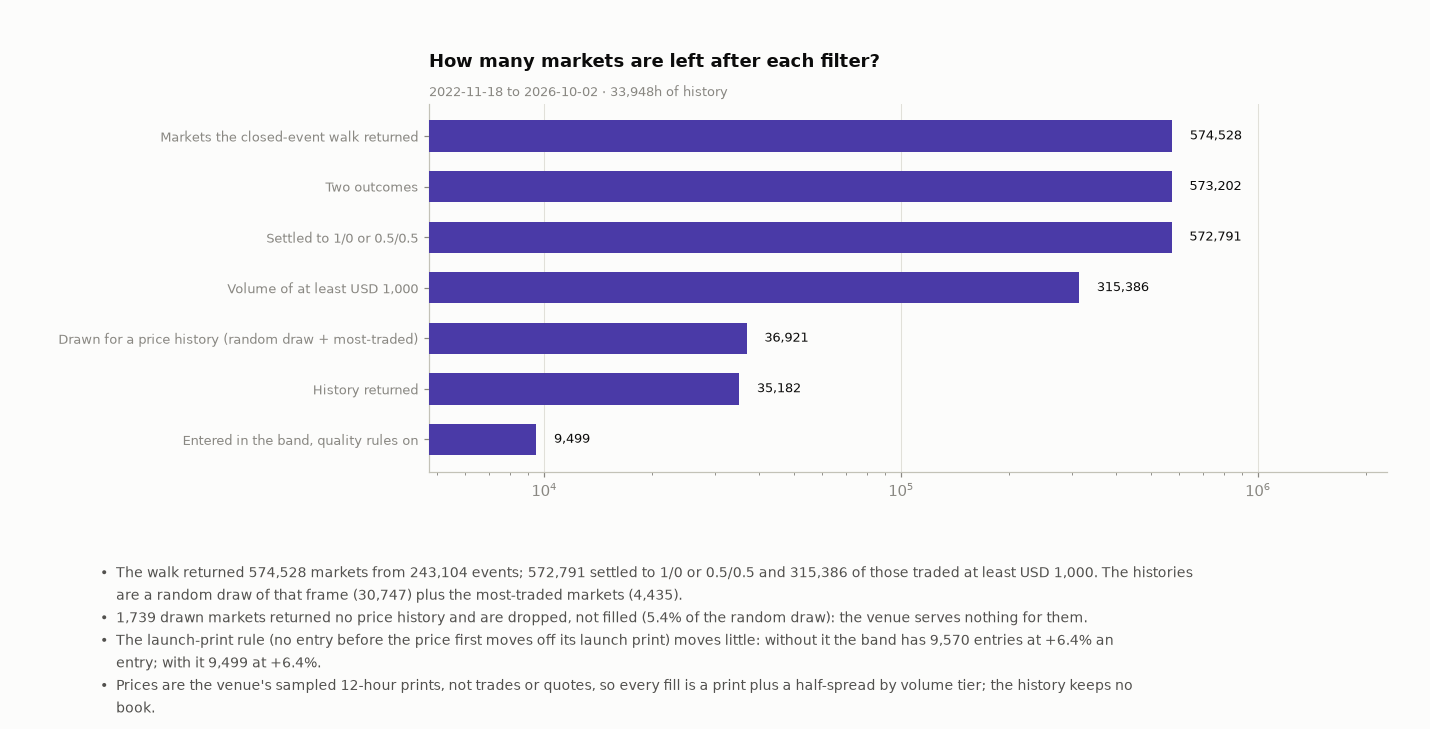

In [7]:
# ---- the funnel, and what the price-quality rules removed ----
n_walk, n_two, n_set, n_1k = CENSUS["markets_walked"], CENSUS["two_outcomes"], CENSUS["binary_settled"], CENSUS["vol_ge_1k"]
n_hist, n_empty = CENSUS["history_markets"], CENSUS["history_empty"]
raw = EN.simulate(MK_R, HIST, BAND[0], BAND[1], slip=SLIP_P, tokens=TOKENS, skip_last=0, after_first_change=False, min_obs=MIN_OBS)
kept = EN.summ(BASE); rawsum = EN.summ(raw)
steps = [("Markets the closed-event walk returned", n_walk), ("Two outcomes", n_two), ("Settled to 1/0 or 0.5/0.5", n_set), ("Volume of at least USD 1,000", n_1k),
         ("Drawn for a price history (random draw + most-traded)", n_hist + n_empty), ("History returned", n_hist), ("Entered in the band, quality rules on", kept["n"])]
assert n_walk >= n_two >= n_set >= n_1k >= n_hist + n_empty >= n_hist >= kept["n"] > 0
BUL = [f"The walk returned {n_walk:,} markets from {CENSUS['events_walked']:,} events; {n_set:,} settled to 1/0 or 0.5/0.5 and {n_1k:,} of those traded at least USD 1,000. The histories are a random draw of that frame ({len(MK_R):,}) plus the most-traded markets ({len(MK_H):,}).",
       f"{n_empty:,} drawn markets returned no price history and are dropped, not filled ({n_empty / DRAWN_R * 100:.1f}% of the random draw): the venue serves nothing for them.",
       f"The launch-print rule (no entry before the price first moves off its launch print) moves little: without it the band has {rawsum['n']:,} entries at {rawsum['ret'] * 100:+.1f}% an entry; with it {kept['n']:,} at {kept['ret'] * 100:+.1f}%.",
       f"Prices are the venue's sampled 12-hour prints, not trades or quotes, so every fill is a print plus a half-spread by volume tier; the history keeps no book."]
fig, gs, top = mkfig(4.2, BUL)
gs.update(left=0.30)
ax = fig.add_subplot(gs[0])
labels = [s[0] for s in steps][::-1]; vals = [s[1] for s in steps][::-1]
ax.barh(range(len(vals)), vals, color=C_NET, zorder=3, height=0.62)
ax.set_xscale("log"); ax.set_yticks(range(len(vals))); ax.set_yticklabels(labels, fontsize=8.5)
for i_, v_ in enumerate(vals):
    ax.text(v_ * 1.12, i_, f"{v_:,}", va="center", fontsize=8.5, color=INK)
ax.set_xlim(left=max(1, min(vals) * 0.5), right=max(vals) * 4); ax.grid(axis="y", visible=False)
ask(ax, "How many markets are left after each filter?", f"{iso_(T_FIRST)[:10]} to {iso_(T_LAST)[:10]} · {(T_LAST - T_FIRST) / 3600:,.0f}h of history")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s2-funnel", FIGURES)

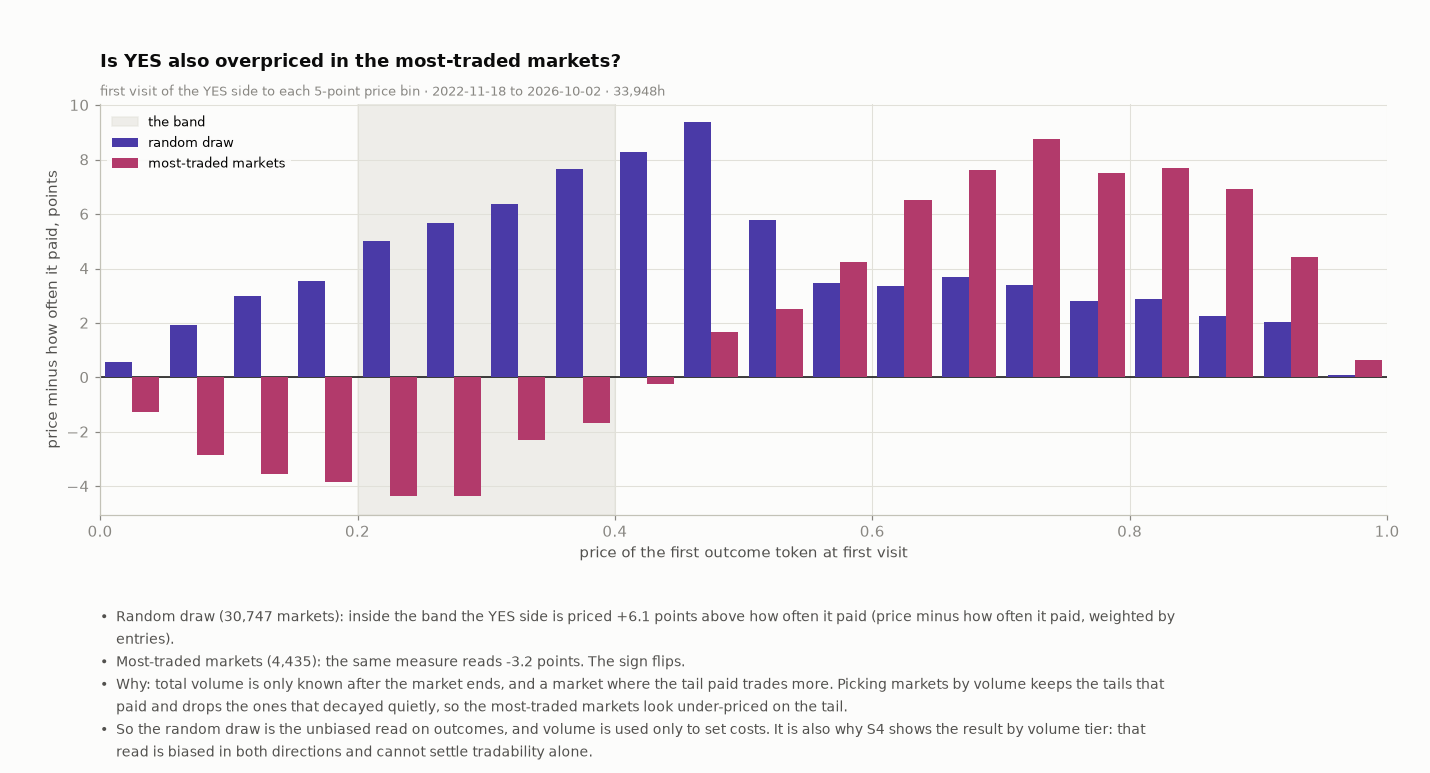

In [8]:
# ---- does the sample change the answer? the random draw against the most-traded markets, same rules ----
ROWS_R = EN.calibration(MK_R, HIST, EDGES, token=0, skip_last=SKIP_LAST)
ROWS_H = EN.calibration(MK_H, HIST, EDGES, token=0, skip_last=SKIP_LAST)
def gaps(rows, mn=30):
    return {round((lo + hi) / 2, 3): (px - hit, n, ev) for lo, hi, n, ev, px, hit in rows if n >= mn}
GR, GH = gaps(ROWS_R), gaps(ROWS_H)
in_band = lambda g: [v for k, v in g.items() if BAND[0] <= k <= BAND[1]]
def wavg(g):
    a = in_band(g); n = sum(x[1] for x in a)
    return sum(x[0] * x[1] for x in a) / n if n else float("nan")
GAP_R, GAP_H = wavg(GR), wavg(GH)
BUL = [f"Random draw ({len(MK_R):,} markets): inside the band the YES side is priced {GAP_R * 100:+.1f} points above how often it paid (price minus how often it paid, weighted by entries).",
       f"Most-traded markets ({len(MK_H):,}): the same measure reads {GAP_H * 100:+.1f} points. The sign flips.",
       "Why: total volume is only known after the market ends, and a market where the tail paid trades more. Picking markets by volume keeps the tails that paid and drops the ones that decayed quietly, so the most-traded markets look under-priced on the tail.",
       "So the random draw is the unbiased read on outcomes, and volume is used only to set costs. It is also why S4 shows the result by volume tier: that read is biased in both directions and cannot settle tradability alone."]
fig, gs, top = mkfig(4.6, BUL)
ax = fig.add_subplot(gs[0])
ks = sorted(set(GR) | set(GH)); w = 0.021
ax.bar([k - w / 2 for k in ks], [GR.get(k, (np.nan,))[0] * 100 for k in ks], width=w, color=C_NET, label="random draw", zorder=3)
ax.bar([k + w / 2 for k in ks], [GH.get(k, (np.nan,))[0] * 100 for k in ks], width=w, color=C_PREM_DK, label="most-traded markets", zorder=3)
ax.axhline(0, color=INK, linewidth=1.0); ax.axvspan(BAND[0], BAND[1], color=GRID, alpha=0.5, zorder=1, label="the band")
ax.set_xlabel("price of the first outcome token at first visit"); ax.set_ylabel("price minus how often it paid, points")
ax.set_xlim(0, 1); ax.legend(loc="upper left", fontsize=8.5, **LEG)
ask(ax, "Is YES also overpriced in the most-traded markets?", f"first visit of the YES side to each 5-point price bin · {iso_(T_FIRST)[:10]} to {iso_(T_LAST)[:10]} · {(T_LAST - T_FIRST) / 3600:,.0f}h")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s2-sampling", FIGURES)

### S2.1 · Survivorship - what we threw away, and could it flip the answer?

In [9]:
# ---- survivorship: what is dropped, what is known about it, and the worst it could do to the headline ----
import tailsell_risk as RK
N_EMPTY, N_UNSET, N_THIN = CENSUS["history_empty"], CENSUS["not_settled_1_0_or_half"], CENSUS["binary_settled"] - CENSUS["vol_ge_1k"]
ENT_IDS = {x["id"] for x in BASE}
SHORT_IDS = {k_ for k_ in MK_R if len(HIST[k_]) < MIN_OBS}
NEVER_IDS = set(MK_R) - ENT_IDS - SHORT_IDS
GROUPS = ("sports", "politics", "crypto", "other")
def first_quality_price(mid):
    h_ = HIST[mid]; mv_ = np.nonzero(h_[:, 1] != h_[0, 1])[0]
    return float(h_[max(1, int(mv_[0])), 1]) if len(mv_) and len(h_) > 1 else float("nan")
def mix_(ids):
    c_ = {g_: sum(1 for k_ in ids if MK_R[k_]["grp"] == g_) for g_ in GROUPS}; n_ = max(1, sum(c_.values()))
    return " / ".join(f"{c_[g_] / n_ * 100:.0f}%" for g_ in GROUPS)
def med_vol(ids):
    return f"{float(np.median([MK_R[k_]['vol'] for k_ in ids])):,.0f}" if ids else "n/a"
def med_px(ids):
    v_ = [first_quality_price(k_) for k_ in ids]; v_ = [u_ for u_ in v_ if u_ == u_]
    return f"{float(np.median(v_)) * 100:.0f}%" if v_ else "n/a"
NOT_KEPT = "not in the frozen file"
SURV_ROWS = [
    ("Entered in the band (the sample)", f"{len(ENT_IDS):,}", f"{len(ENT_IDS) / len(MK_R) * 100:.1f}% of the draw with a history", mix_(ENT_IDS), med_vol(ENT_IDS), f"{SUM['px'] * 100:.0f}% (mean entry price)"),
    ("History present, price never in the band after the quality rules", f"{len(NEVER_IDS):,}", f"{len(NEVER_IDS) / len(MK_R) * 100:.1f}% of the draw with a history", mix_(NEVER_IDS), med_vol(NEVER_IDS), f"{med_px(NEVER_IDS)} (median first quality print)"),
    (f"History present, fewer than {MIN_OBS} prints", f"{len(SHORT_IDS):,}", f"{len(SHORT_IDS) / len(MK_R) * 100:.1f}% of the draw with a history", mix_(SHORT_IDS), med_vol(SHORT_IDS), f"{med_px(SHORT_IDS)} (median first quality print)"),
    ("Empty history, dropped", f"{N_EMPTY:,}", f"{N_EMPTY / DRAWN_R * 100:.1f}% of all drawn", NOT_KEPT, NOT_KEPT, NOT_KEPT),
    ("Settled to something other than 1/0 or 0.5/0.5, excluded", f"{N_UNSET:,}", f"{N_UNSET / CENSUS['two_outcomes'] * 100:.2f}% of two-outcome markets", NOT_KEPT, NOT_KEPT, NOT_KEPT),
    ("Volume under USD 1,000, outside the frame by design", f"{N_THIN:,}", f"{N_THIN / CENSUS['binary_settled'] * 100:.0f}% of settled binary markets", NOT_KEPT, NOT_KEPT, NOT_KEPT),
]
display(Markdown(f"Window {iso_(T_FIRST)[:10]} to {iso_(T_LAST)[:10]} ({(T_LAST - T_FIRST) / 3600:,.0f}h of history), one regime, {VER['passed']}/{VER['total']} book checks so far. Category mix reads sports / politics / crypto / other.\n\n"
                 "| Set | Markets | Share | Category mix | Median final volume, USD | Price at entry, where known |\n|---|---|---|---|---|---|\n" + "\n".join("| " + " | ".join(r_) + " |" for r_ in SURV_ROWS)))
# ---- the bound: each dropped market that would have entered is put in the book at the worst return, losing its whole stake ----
N_B, M_B = SUM["n"], SUM["ret"]
E_RATE = N_B / len(MK_R)                                           # entries per market of the draw that has a history
W_BAR = float(np.mean([x["ret"] for x in BASE if x["ret"] > 0]))   # mean return of a winning position
P0 = SUM["hit"]                                                    # share of positions that lost the stake
X_EMPTY = E_RATE * N_EMPTY                                         # every empty draw counted as a market of the draw
X_UNSET = E_RATE * N_UNSET * SHARE                                 # the unsettled markets, scaled to the sampled share of the frame, all taken as inside the frame
with_extra = lambda x_: (N_B * M_B - x_) / (N_B + x_)              # headline mean return if x_ extra positions each lose the stake
q_break = lambda x_: (N_B * M_B + x_ * W_BAR) / (x_ * (1 + W_BAR))  # share of the extra positions that must lose the stake to bring the headline to zero (the rest earn W_BAR)
BOUND = [("As run", 0.0), ("Empty histories all lose the stake", X_EMPTY), ("Unsettled markets all lose the stake", X_UNSET), ("Both", X_EMPTY + X_UNSET)]
SURV_HEAD = with_extra(X_EMPTY + X_UNSET); SURV_Q = q_break(X_EMPTY + X_UNSET); SURV_Q_E = q_break(X_EMPTY)
SURV_OK = SURV_HEAD > 0
display(Markdown("| Case | Extra entries | Mean return per entry |\n|---|---|---|\n" + "\n".join(f"| {a} | {x_:,.0f} | {with_extra(x_) * 100:+.1f}% |" for a, x_ in BOUND)))
display(Markdown(f"- Each case adds positions at the sample's own entry rate ({E_RATE:.2f} entries per market with a history) and gives every one the worst return, losing the whole stake. A short cannot lose more than its stake plus the exit slippage (the book check), so this is the floor for an entered market.\n"
                 f"- The headline {'survives' if SURV_OK else 'does not survive'} the worst case for both sets together: {with_extra(X_EMPTY + X_UNSET) * 100:+.1f}% an entry. The dropped entrants would have to lose the stake {SURV_Q * 100:.0f}% of the time (empty histories alone: {SURV_Q_E * 100:.0f}%) to erase it, against {P0 * 100:.0f}% in the sample, the rest earning the sample's mean winner of {W_BAR * 100:+.0f}%.\n"
                 f"- What this cannot say: whether a market with no price history is a thin new market, a withdrawn one or a data gap (not kept in the frozen file; a board item asks for the rows to be kept), and nothing about the {N_THIN:,} markets under USD 1,000, which the study does not claim."))

Window 2022-11-18 to 2026-10-02 (33,948h of history), one regime, 1/1 book checks so far. Category mix reads sports / politics / crypto / other.

| Set | Markets | Share | Category mix | Median final volume, USD | Price at entry, where known |
|---|---|---|---|---|---|
| Entered in the band (the sample) | 9,499 | 30.9% of the draw with a history | 57% / 12% / 13% / 18% | 15,375 | 30% (mean entry price) |
| History present, price never in the band after the quality rules | 19,435 | 63.2% of the draw with a history | 41% / 8% / 39% / 12% | 16,236 | 50% (median first quality print) |
| History present, fewer than 2 prints | 1,813 | 5.9% of the draw with a history | 48% / 7% / 43% / 3% | 5,025 | n/a (median first quality print) |
| Empty history, dropped | 1,739 | 5.4% of all drawn | not in the frozen file | not in the frozen file | not in the frozen file |
| Settled to something other than 1/0 or 0.5/0.5, excluded | 411 | 0.07% of two-outcome markets | not in the frozen file | not in the frozen file | not in the frozen file |
| Volume under USD 1,000, outside the frame by design | 257,405 | 45% of settled binary markets | not in the frozen file | not in the frozen file | not in the frozen file |

| Case | Extra entries | Mean return per entry |
|---|---|---|
| As run | 0 | +6.4% |
| Empty histories all lose the stake | 537 | +0.7% |
| Unsettled markets all lose the stake | 13 | +6.2% |
| Both | 551 | +0.5% |

- Each case adds positions at the sample's own entry rate (0.31 entries per market with a history) and gives every one the worst return, losing the whole stake. A short cannot lose more than its stake plus the exit slippage (the book check), so this is the floor for an entered market.
- The headline survives the worst case for both sets together: +0.5% an entry. The dropped entrants would have to lose the stake 107% of the time (empty histories alone: 109%) to erase it, against 25% in the sample, the rest earning the sample's mean winner of +42%.
- What this cannot say: whether a market with no price history is a thin new market, a withdrawn one or a data gap (not kept in the frozen file; a board item asks for the rows to be kept), and nothing about the 257,405 markets under USD 1,000, which the study does not claim.

### S2.2 · Look-ahead - does each entry use only what was known at the time?

The rule must not change its entries when outcomes or final volumes are permuted, or when every history is cut at its entry print. Four planted faults must each be caught; the last is the first build's own rule.

In [10]:
# ---- the planted-fault check: the property is "an entry decision uses no outcome, no final volume and no print after the entry" ----
RUNFN = lambda mk_, hist_: EN.simulate(mk_, hist_, BAND[0], BAND[1], slip=SLIP_P, tokens=TOKENS, skip_last=SKIP_LAST, min_obs=MIN_OBS)
OLDFN = lambda mk_, hist_: EN.simulate(mk_, hist_, BAND[0], BAND[1], slip=SLIP_P, tokens=TOKENS, skip_last=OLD_RULE[0], min_obs=OLD_RULE[1])
ENTRIES = lambda trs_: {x["id"]: (x["i"], x["pe"]) for x in trs_}
VOL_MED = float(np.median([m_["vol"] for m_ in MK_R.values()]))
VARIANTS = {
    "the rule as run": lambda m_, h_: ENTRIES(RUNFN(m_, h_)),
    "planted: keeps only entries whose token did not pay": lambda m_, h_: ENTRIES(x for x in RUNFN(m_, h_) if m_[x["id"]]["y"][x["k"]] < 1.0),
    "planted: keeps only markets above the median final volume": lambda m_, h_: ENTRIES(x for x in RUNFN(m_, h_) if m_[x["id"]]["vol"] >= VOL_MED),
    "planted: keeps only entries whose price is lower 3 prints later": lambda m_, h_: ENTRIES(x for x in RUNFN(m_, h_) if h_[x["id"]][min(x["i"] + 3, len(h_[x["id"]]) - 1), 1] < x["pe"]),
    f"planted: the first build's rule (none in the last {OLD_RULE[0]} prints, {OLD_RULE[1]} prints a history)": lambda m_, h_: ENTRIES(OLDFN(m_, h_)),
}
LEAK = LC.leak_table(VARIANTS, MK_R, HIST, outcome=("y",), cost=("vol",), pad=LEAK_PAD, seed=SEED)
LEAK_NAMES = list(VARIANTS)
LEAK_FLAG = 0.05
REAL_CLEAN = LEAK[LEAK_NAMES[0]]["clean"]
CAUGHT = [LEAK[LEAK_NAMES[1]]["share_outcome"] > LEAK_FLAG, LEAK[LEAK_NAMES[2]]["share_cost"] > LEAK_FLAG,
          LEAK[LEAK_NAMES[3]]["share_cut"] > LEAK_FLAG, LEAK[LEAK_NAMES[4]]["share_cut"] > LEAK_FLAG]
assert all(CAUGHT), f"the check missed a planted leak: {LEAK}"
assert REAL_CLEAN, f"the rule as run changes its entries when a forbidden input changes: {LEAK[LEAK_NAMES[0]]}"
G_LEAK = REAL_CLEAN and all(CAUGHT)
LEAK_MAX = max(LEAK[LEAK_NAMES[0]][k_] for k_ in ("share_outcome", "share_cost", "share_cut"))
display(Markdown(f"Window {iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} ({HOURS:,.0f}h), {VER['passed']}/{VER['total']} book checks. Share of entries that change (`fundplat.quant.core.leakcheck`, the worst of 3 permutations); a column flags above {LEAK_FLAG:.0%}.\n\n"
                 "| Variant | Entries | Outcomes permuted | Final volumes permuted | History cut at the entry |\n|---|---|---|---|---|\n" + "\n".join(
                     f"| {n_} | {LEAK[n_]['n_entries']:,} | {LEAK[n_]['share_outcome'] * 100:.1f}% | {LEAK[n_]['share_cost'] * 100:.1f}% | {LEAK[n_]['share_cut'] * 100:.1f}% |" for n_ in LEAK_NAMES)))
# ---- what the check does not cover, measured: the costs use the final volume; and what the first build's rule did to the headline ----
VOL_PLC = [EN.summ(RUNFN(RK.permuted_fields(MK_R, ("vol",), 100 + s_), HIST))["ret"] for s_ in range(5)]
OLD_TR = OLDFN(MK_R, HIST)
_old_keys = {(x["id"], x["i"]) for x in OLD_TR}
NEW_S = EN.summ([x for x in BASE if (x["id"], x["i"]) not in _old_keys])
OLD_S = EN.summ(OLD_TR)
display(Markdown(f"- **Cost leak, measured.** The half-spread is set by the market's final volume, which is known only afterwards and is higher where a tail paid (S2). With the volumes permuted across markets (five draws) the mean return per entry is {min(VOL_PLC) * 100:+.1f}% to {max(VOL_PLC) * 100:+.1f}% against {SUM['ret'] * 100:+.1f}% as run: the leak is worth {(SUM['ret'] - float(np.mean(VOL_PLC))) * 100:+.2f} points.\n"
                 f"- **The first build's rule, measured.** It skipped entries in the last {OLD_RULE[0]} prints of a history and histories under {OLD_RULE[1]} prints, both known only once the market ends; the cut column catches it. "
                 f"The {NEW_S.get('n', 0):,} entries it dropped return {NEW_S.get('ret', float('nan')) * 100:+.1f}% each, so it lifted the mean from {SUM['ret'] * 100:+.1f}% to {OLD_S['ret'] * 100:+.1f}% an entry. Every number here is without it."))

Window 2024-02-15 to 2026-10-02 (23,040h), 1/1 book checks. Share of entries that change (`fundplat.quant.core.leakcheck`, the worst of 3 permutations); a column flags above 5%.

| Variant | Entries | Outcomes permuted | Final volumes permuted | History cut at the entry |
|---|---|---|---|---|
| the rule as run | 9,499 | 0.0% | 0.0% | 0.0% |
| planted: keeps only entries whose token did not pay | 7,157 | 57.6% | 0.0% | 0.0% |
| planted: keeps only markets above the median final volume | 4,796 | 0.0% | 100.2% | 0.0% |
| planted: keeps only entries whose price is lower 3 prints later | 4,653 | 0.0% | 0.0% | 100.0% |
| planted: the first build's rule (none in the last 2 prints, 4 prints a history) | 8,326 | 0.0% | 0.0% | 100.0% |

- **Cost leak, measured.** The half-spread is set by the market's final volume, which is known only afterwards and is higher where a tail paid (S2). With the volumes permuted across markets (five draws) the mean return per entry is +6.4% to +6.4% against +6.4% as run: the leak is worth -0.02 points.
- **The first build's rule, measured.** It skipped entries in the last 2 prints of a history and histories under 4 prints, both known only once the market ends; the cut column catches it. The 1,173 entries it dropped return -0.9% each, so it lifted the mean from +6.4% to +7.4% an entry. Every number here is without it.

## S3 · Core result - is YES overpriced, and does selling it pay?

| We ask | It passes if |
|---|---|
| Is YES priced above how often it pays, and does selling it beat a T-bill after costs, with no leverage? | the gap is above zero with its interval above zero, and the book ends above the T-bill |

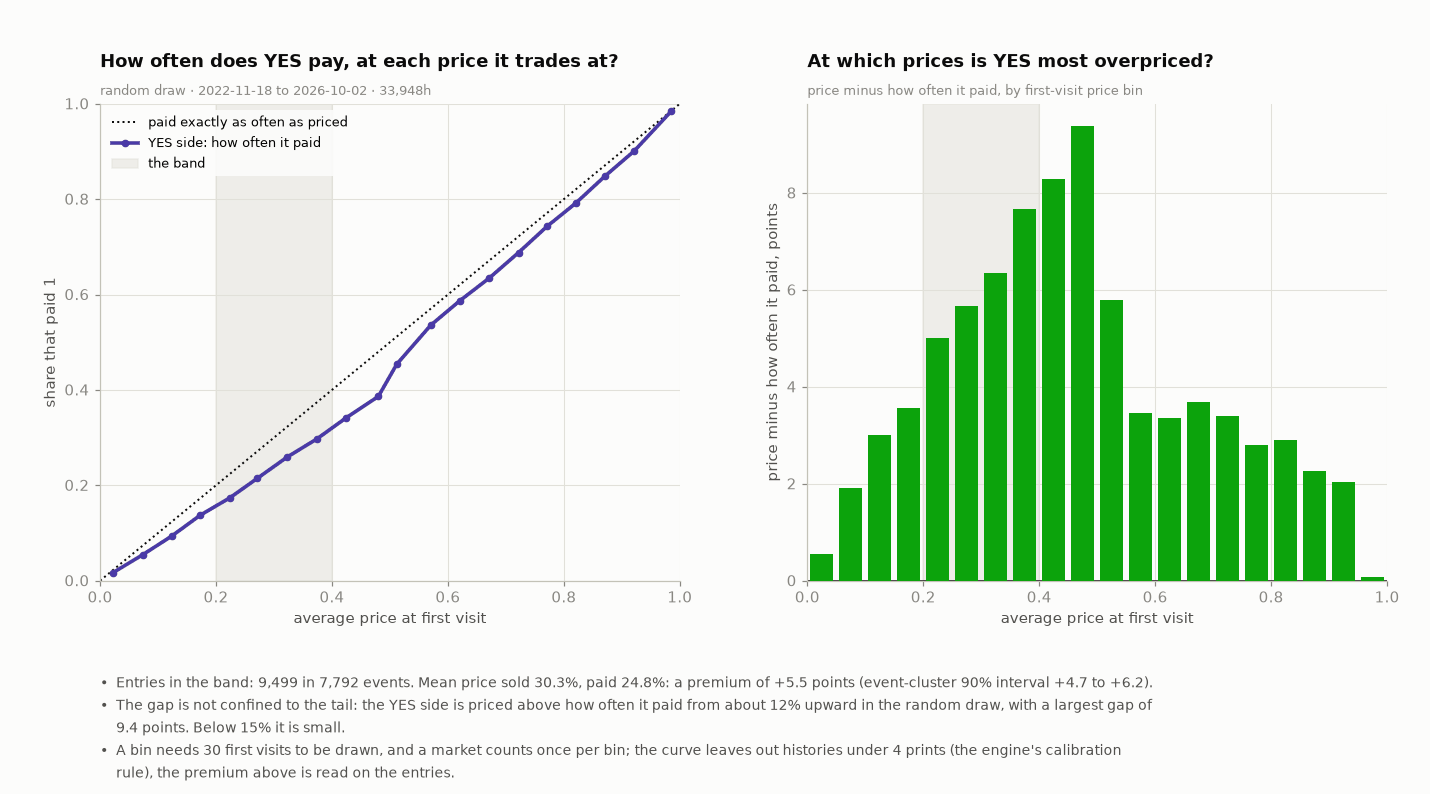

In [11]:
# ---- the calibration curve of the YES side, random draw ----
rows = [r_ for r_ in ROWS_R if r_[2] >= 30]
xs = [(r_[0] + r_[1]) / 2 for r_ in rows]
PRICE = np.array([r_[4] for r_ in rows]); HIT = np.array([r_[5] for r_ in rows]); NB = np.array([r_[2] for r_ in rows])
CAL_BAND = [r_ for r_ in rows if BAND[0] <= (r_[0] + r_[1]) / 2 <= BAND[1]]
prem = [x["pe"] - x["y"] for x in BASE]
PREM_MEAN, PREM_P = EN.signflip_p(prem, [x["event"] for x in BASE], reps=4000, seed=SEED)
_, PREM_LO, PREM_HI, _ = EN.cluster_mean_ci(prem, [x["event"] for x in BASE], reps=NBOOT, seed=SEED)
G_CAL = PREM_LO > 0
BUL = [f"Entries in the band: {SUM['n']:,} in {SUM['events']:,} events. Mean price sold {pct(SUM['px'])}, paid {pct(SUM['hit'])}: a premium of {PREM_MEAN * 100:+.1f} points (event-cluster 90% interval {PREM_LO * 100:+.1f} to {PREM_HI * 100:+.1f}).",
       f"The gap is not confined to the tail: the YES side is priced above how often it paid from about {min((x for x, p_, h_ in zip(xs, PRICE, HIT) if p_ > h_ + 0.02), default=float('nan')) * 100:.0f}% upward in the random draw, with a largest gap of {max(PRICE - HIT) * 100:.1f} points. Below 15% it is small.",
       "A bin needs 30 first visits to be drawn, and a market counts once per bin; the curve leaves out histories under 4 prints (the engine's calibration rule), the premium above is read on the entries."]
fig, gs, top = mkfig(5.2, BUL, ncols=2, wspace=0.22)
ax = fig.add_subplot(gs[0, 0])
ax.plot([0, 1], [0, 1], color=INK, linewidth=1.3, linestyle=":", zorder=2, label="paid exactly as often as priced")
ax.plot(PRICE, HIT, color=C_NET, linewidth=2.4, marker="o", markersize=4, zorder=4, label="YES side: how often it paid")
ax.axvspan(BAND[0], BAND[1], color=GRID, alpha=0.5, zorder=1, label="the band")
ax.set_xlabel("average price at first visit"); ax.set_ylabel("share that paid 1"); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc="upper left", fontsize=8.5, **LEG)
ask(ax, "How often does YES pay, at each price it trades at?", f"random draw · {iso_(T_FIRST)[:10]} to {iso_(T_LAST)[:10]} · {(T_LAST - T_FIRST) / 3600:,.0f}h")
ax2 = fig.add_subplot(gs[0, 1])
gapv = (PRICE - HIT) * 100
ax2.bar(xs, gapv, width=0.04, color=[GOOD if g_ > 0 else CRIT for g_ in gapv], zorder=3)
ax2.axhline(0, color=INK, linewidth=1.0); ax2.axvspan(BAND[0], BAND[1], color=GRID, alpha=0.5, zorder=1)
ax2.set_xlabel("average price at first visit"); ax2.set_ylabel("price minus how often it paid, points"); ax2.set_xlim(0, 1)
ax2.set_title("At which prices is YES most overpriced?", loc="left", pad=24, fontsize=11.5, fontweight="bold")
ax2.text(0.0, 1.012, "price minus how often it paid, by first-visit price bin", transform=ax2.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s3-calibration", FIGURES)

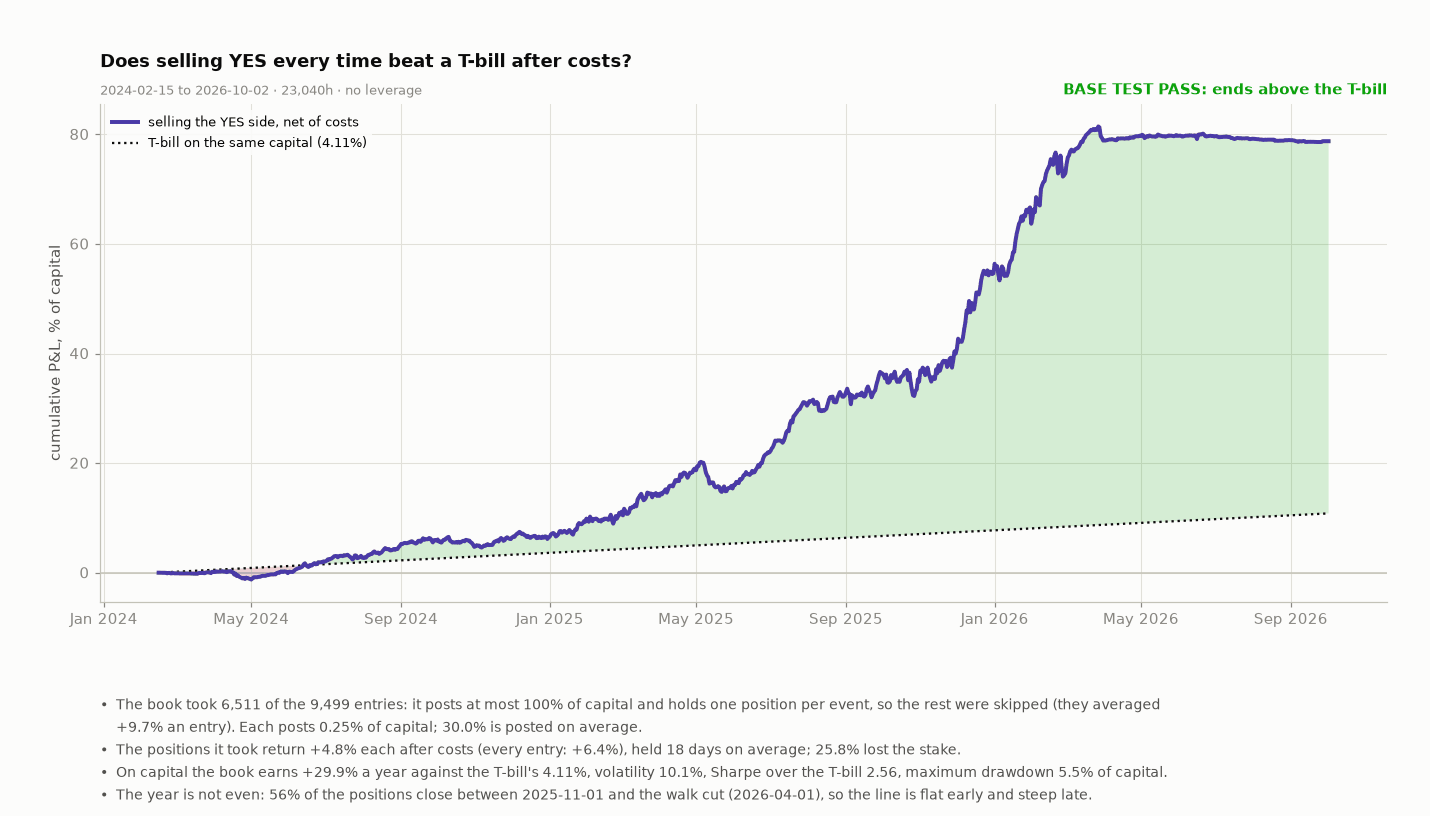

In [12]:
# ---- the base book: stake CLIP per position, held to resolution, against the T-bill ----
idx_days = pd.to_datetime((np.arange(len(B_DAILY)) + B_D0) * DAYSEC, unit="s", utc=True)
cum = np.cumsum(B_DAILY) * 100
tb = HURDLE * np.arange(1, len(B_DAILY) + 1) / 365.0 * 100
DEPLOYED = sum(CLIP * x["days"] for x in B_ACC) / max(1, len(B_DAILY))
ANN = B_ST["ann_ret"]; G_BASE = ANN > HURDLE
EXIT_SHARE = sum(1 for x_ in B_ACC if "2025-11-01" <= iso_(x_["t_out"])[:10] < WALK_CUT) / len(B_ACC)
BUL = [f"The book took {len(B_ACC):,} of the {SUM['n']:,} entries: it posts at most {CAP:.0%} of capital and holds one position per event, so the rest were skipped (they averaged {SKIP_S['ret'] * 100:+.1f}% an entry). Each posts {pct(CLIP, 2)} of capital; {DEPLOYED * 100:.1f}% is posted on average.",
       f"The positions it took return {BOOK_S['ret'] * 100:+.1f}% each after costs (every entry: {SUM['ret'] * 100:+.1f}%), held {BOOK_S['days']:.0f} days on average; {pct(BOOK_S['hit'])} lost the stake.",
       f"On capital the book earns {ANN * 100:+.1f}% a year against the T-bill's {HURDLE * 100:.2f}%, volatility {B_ST['ann_vol'] * 100:.1f}%, Sharpe over the T-bill {B_ST['sharpe_ex']:.2f}, maximum drawdown {B_ST['max_dd'] * 100:.1f}% of capital.",
       f"The year is not even: {EXIT_SHARE * 100:.0f}% of the positions close between 2025-11-01 and the walk cut ({WALK_CUT}), so the line is flat early and steep late."]
fig, gs, top = mkfig(5.4, BUL)
ax = fig.add_subplot(gs[0])
ax.plot(idx_days, cum, color=C_NET, linewidth=2.6, zorder=5, label="selling the YES side, net of costs")
ax.plot(idx_days, tb, color=INK, linewidth=1.5, linestyle=":", zorder=3, label=f"T-bill on the same capital ({HURDLE * 100:.2f}%)")
ax.fill_between(idx_days, cum, tb, where=(cum >= tb), interpolate=True, color=GOOD, alpha=0.16, linewidth=0, zorder=2)
ax.fill_between(idx_days, cum, tb, where=(cum < tb), interpolate=True, color=CRIT, alpha=0.22, linewidth=0, zorder=2)
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
ax.text(1.0, 1.012, "BASE TEST " + ("PASS: ends above the T-bill" if G_BASE else "FAIL: ends below the T-bill"), transform=ax.transAxes, ha="right", va="bottom", color=(GOOD if G_BASE else CRIT), fontsize=9.5, fontweight="bold")
ax.set_ylabel("cumulative P&L, % of capital"); ax.legend(loc="upper left", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ask(ax, "Does selling YES every time beat a T-bill after costs?", f"{iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h · no leverage")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s3-equity", FIGURES)

## S4 · Robustness - is it real, and where does it work?

| We ask | It passes if |
|---|---|
| Is the gap real? Does it hold in the second half, beyond luck, with more cost, with losses counted together? Where does it work, and does the rule matter? | the second half beats the T-bill; the luck test is below 0.10; no cost level flips it; the interval stays above zero; busy markets are read and named; most rule variants beat the T-bill in both halves |

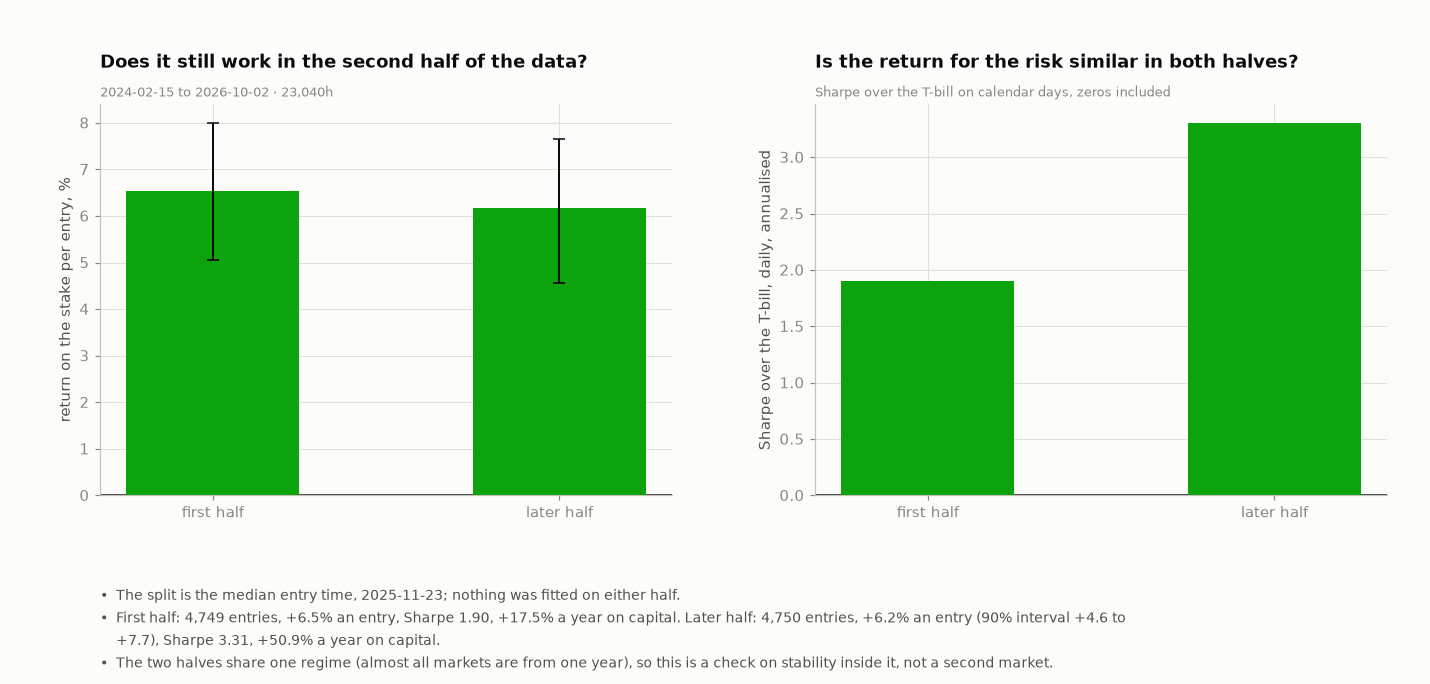

In [13]:
# ---- Test 1a: the later half of the entries, which the first half never saw ----
TMED = float(np.median([x["t_in"] for x in BASE]))
H1 = [x for x in BASE if x["t_in"] < TMED]; H2 = [x for x in BASE if x["t_in"] >= TMED]
def half_stats(trs):
    d, d0, acc = book(trs)
    return EN.stats(d, rf=HURDLE), EN.summ(trs), d, d0
S_H1, M_H1, _, _ = half_stats(H1); S_H2, M_H2, D_H2, D0_H2 = half_stats(H2)
CI_H1 = EN.cluster_mean_ci([x["ret"] for x in H1], [x["event"] for x in H1], reps=NBOOT, seed=SEED)
CI_H2 = EN.cluster_mean_ci([x["ret"] for x in H2], [x["event"] for x in H2], reps=NBOOT, seed=SEED)
G_OOS = S_H2["ann_ret"] > HURDLE and CI_H2[1] > 0
BUL = [f"The split is the median entry time, {iso_(TMED)[:10]}; nothing was fitted on either half.",
       f"First half: {M_H1['n']:,} entries, {M_H1['ret'] * 100:+.1f}% an entry, Sharpe {S_H1['sharpe_ex']:.2f}, {S_H1['ann_ret'] * 100:+.1f}% a year on capital. Later half: {M_H2['n']:,} entries, {M_H2['ret'] * 100:+.1f}% an entry (90% interval {CI_H2[1] * 100:+.1f} to {CI_H2[2] * 100:+.1f}), Sharpe {S_H2['sharpe_ex']:.2f}, {S_H2['ann_ret'] * 100:+.1f}% a year on capital.",
       "The two halves share one regime (almost all markets are from one year), so this is a check on stability inside it, not a second market."]
fig, gs, top = mkfig(4.4, BUL, ncols=2, wspace=0.25)
ax = fig.add_subplot(gs[0, 0])
vals = [M_H1["ret"] * 100, M_H2["ret"] * 100]; lo = [vals[0] - CI_H1[1] * 100, vals[1] - CI_H2[1] * 100]; hi = [CI_H1[2] * 100 - vals[0], CI_H2[2] * 100 - vals[1]]
ax.bar([0, 1], vals, color=[GOOD if v_ > 0 else CRIT for v_ in vals], width=0.5, zorder=3); ax.errorbar([0, 1], vals, yerr=[lo, hi], color=INK, capsize=4, linewidth=1.3, linestyle="none", zorder=4)
ax.axhline(0, color=INK, linewidth=1.0); ax.set_xticks([0, 1]); ax.set_xticklabels(["first half", "later half"]); ax.set_ylabel("return on the stake per entry, %")
ask(ax, "Does it still work in the second half of the data?", f"{iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h")
ax = fig.add_subplot(gs[0, 1])
vals = [S_H1["sharpe_ex"], S_H2["sharpe_ex"]]
ax.bar([0, 1], vals, color=[GOOD if v_ > 0 else CRIT for v_ in vals], width=0.5, zorder=3); ax.axhline(0, color=INK, linewidth=1.0)
ax.set_xticks([0, 1]); ax.set_xticklabels(["first half", "later half"]); ax.set_ylabel("Sharpe over the T-bill, daily, annualised")
ax.set_title("Is the return for the risk similar in both halves?", loc="left", pad=24, fontsize=11.5, fontweight="bold")
ax.text(0.0, 1.012, "Sharpe over the T-bill on calendar days, zeros included", transform=ax.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-halves", FIGURES)

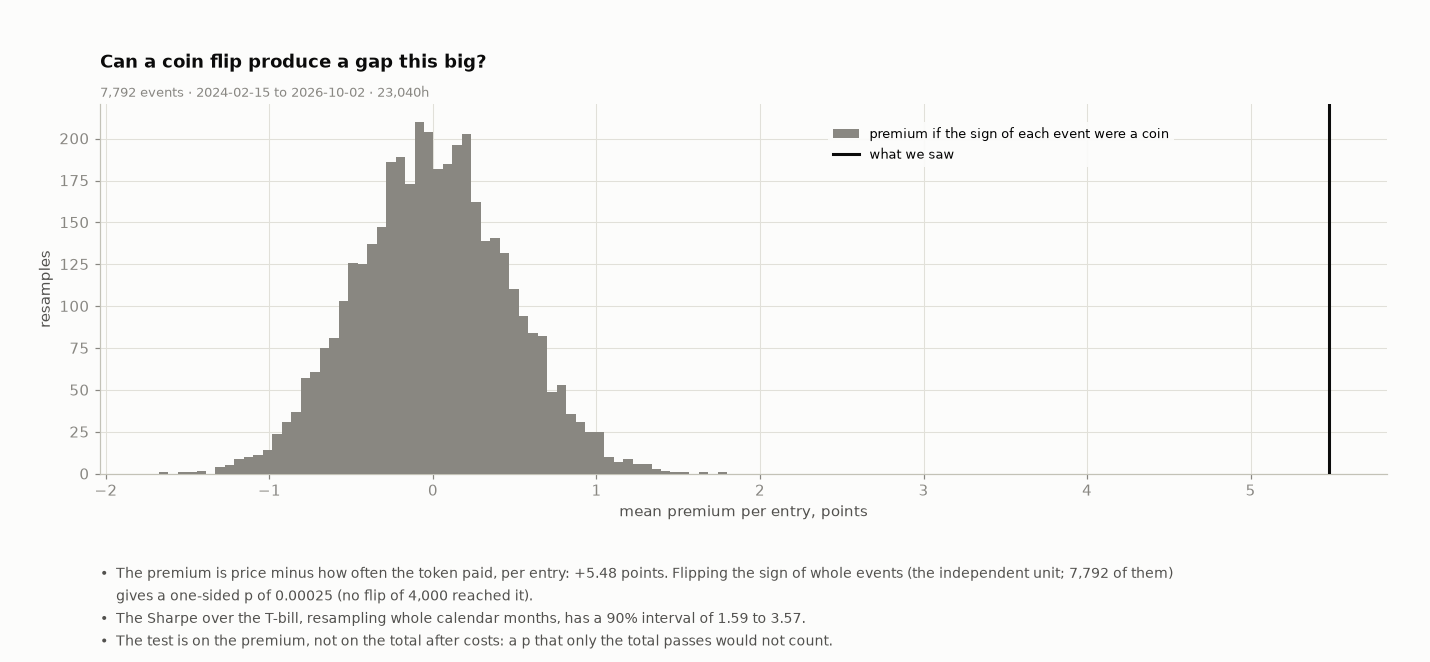

In [14]:
# ---- Test 1b: could luck produce it? the premium (price minus hit) flipped by whole events; the Sharpe by whole months ----
rng_ = np.random.default_rng(SEED)
cl_ = {}
for x_ in BASE:
    cl_[x_["event"]] = cl_.get(x_["event"], 0.0) + (x_["pe"] - x_["y"])
sums_ = np.array(list(cl_.values())); obs_ = sums_.sum() / len(BASE)
null_ = (rng_.choice([-1.0, 1.0], size=(SF_REPS, len(sums_))) * sums_).sum(axis=1) / len(BASE)
SF_HITS = int((null_ * len(BASE) >= sums_.sum()).sum())
SF_P = (SF_HITS + 1) / (SF_REPS + 1)                     # the permutation p counts the observed sample as one draw, so it is never 0
P_TXT = f"{SF_P:.5f}" + (f" (no flip of {SF_REPS:,} reached it)" if SF_HITS == 0 else "")
SH_LO, SH_HI = EN.block_sharpe_ci(B_DAILY - HURDLE / 365.0, B_D0, reps=NBOOT, seed=SEED)
G_LUCK = SF_P < P_GATE and SH_LO > 0
BUL = [f"The premium is price minus how often the token paid, per entry: {obs_ * 100:+.2f} points. Flipping the sign of whole events (the independent unit; {len(sums_):,} of them) gives a one-sided p of {P_TXT}.",
       f"The Sharpe over the T-bill, resampling whole calendar months, has a 90% interval of {SH_LO:.2f} to {SH_HI:.2f}.",
       "The test is on the premium, not on the total after costs: a p that only the total passes would not count."]
fig, gs, top = mkfig(4.2, BUL)
ax = fig.add_subplot(gs[0])
ax.hist(null_ * 100, bins=60, color=C_COST, zorder=3, label="premium if the sign of each event were a coin")
ax.axvline(obs_ * 100, color=INK, linewidth=2.0, zorder=4, label="what we saw")
ax.set_xlabel("mean premium per entry, points"); ax.set_ylabel("resamples"); ax.legend(loc="upper center", bbox_to_anchor=(0.7, 0.97), fontsize=8.5, **LEG)
ask(ax, "Can a coin flip produce a gap this big?", f"{len(sums_):,} events · {iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-luck", FIGURES)

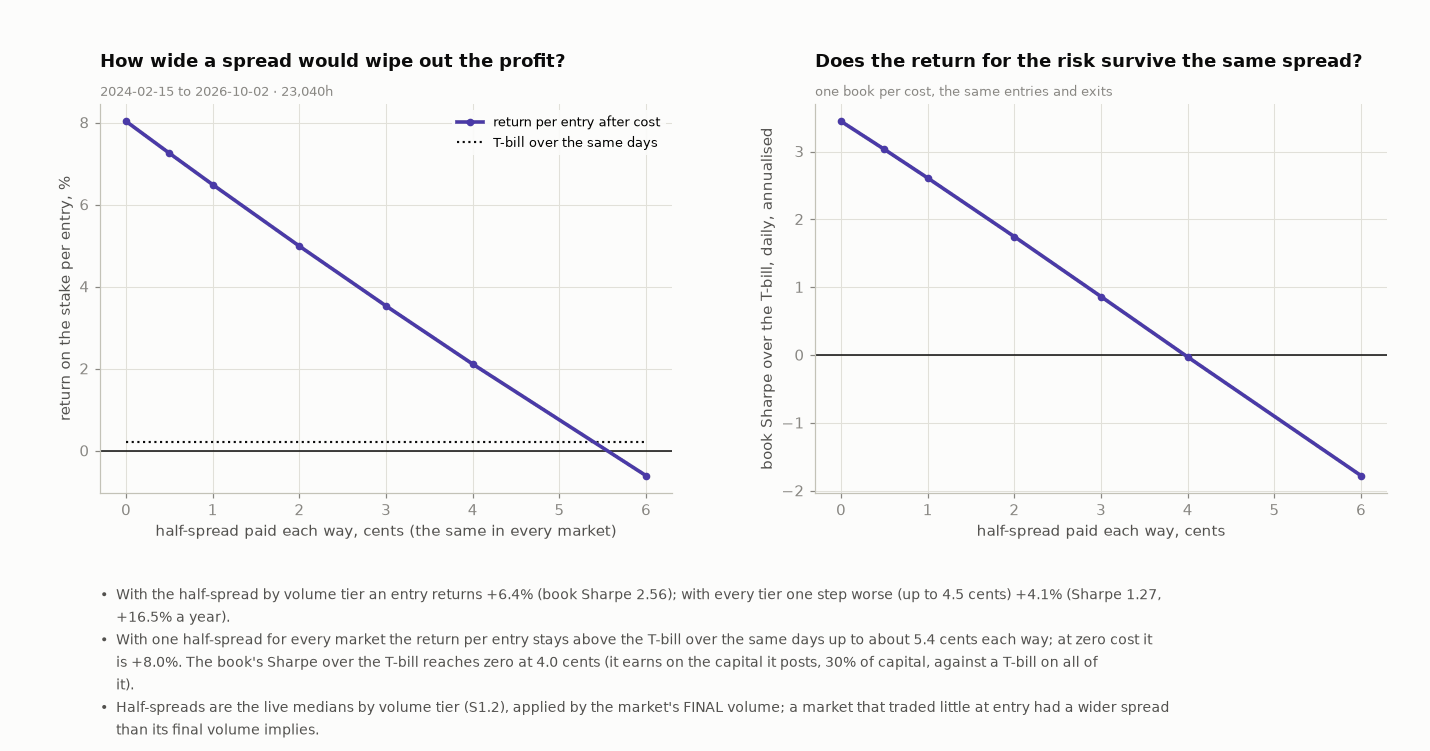

In [15]:
# ---- Test 1c: how much cost does it take to kill it? one slippage for every market, plus the two schedules ----
SW = []
for s_ in SLIP_SWEEP:
    tr_ = run(MK_R, BAND, slip=s_); d_, d0_, a_ = book(tr_)
    SW.append((s_, EN.summ(tr_), EN.stats(d_, rf=HURDLE)))
TR_S = run(MK_R, BAND, slip=SLIP_S); D_S, D0_S, A_S = book(TR_S); ST_S = EN.stats(D_S, rf=HURDLE); SUM_S = EN.summ(TR_S)
xs_ = [s[0] * 100 for s in SW]; ys_ = [s[1]["ret"] * 100 for s in SW]; shs_ = [s[2]["sharpe_ex"] for s in SW]; tbs_ = [HURDLE * s[1]["days"] / 365 * 100 for s in SW]
BE = next((xs_[i - 1] + (xs_[i] - xs_[i - 1]) * (ys_[i - 1] - tbs_[i - 1]) / ((ys_[i - 1] - tbs_[i - 1]) - (ys_[i] - tbs_[i])) for i in range(1, len(xs_)) if ys_[i] <= tbs_[i] < ys_[i - 1] or ys_[i] <= tbs_[i]), float("nan"))
BE_SH = next((xs_[i - 1] + (xs_[i] - xs_[i - 1]) * shs_[i - 1] / (shs_[i - 1] - shs_[i]) for i in range(1, len(xs_)) if shs_[i] <= 0 < shs_[i - 1]), float("nan"))
G_COST = ST_S["ann_ret"] > HURDLE and SUM_S["ret"] > 0 and min(s[1]["ret"] for s in SW if s[0] <= 0.02) > 0
BE_TXT = f"up to about {BE:.1f} cents each way" if BE == BE else f"across the whole sweep, up to {SLIP_SWEEP[-1] * 100:.0f} cents each way"
BE_GATE = f"break-even {BE:.1f} cents" if BE == BE else f"no break-even up to {SLIP_SWEEP[-1] * 100:.0f} cents"
BUL = [f"With the half-spread by volume tier an entry returns {SUM['ret'] * 100:+.1f}% (book Sharpe {B_ST['sharpe_ex']:.2f}); with every tier one step worse (up to {SLIP_STRESS[-1][1] * 100:.1f} cents) {SUM_S['ret'] * 100:+.1f}% (Sharpe {ST_S['sharpe_ex']:.2f}, {ST_S['ann_ret'] * 100:+.1f}% a year).",
       f"With one half-spread for every market the return per entry stays above the T-bill over the same days {BE_TXT}; at zero cost it is {SW[0][1]['ret'] * 100:+.1f}%. The book's Sharpe over the T-bill reaches zero at {BE_SH:.1f} cents (it earns on the capital it posts, 30% of capital, against a T-bill on all of it).",
       "Half-spreads are the live medians by volume tier (S1.2), applied by the market's FINAL volume; a market that traded little at entry had a wider spread than its final volume implies."]
fig, gs, top = mkfig(4.4, BUL, ncols=2, wspace=0.25)
ax = fig.add_subplot(gs[0, 0])
ax.plot(xs_, ys_, color=C_NET, linewidth=2.4, marker="o", markersize=4, zorder=4, label="return per entry after cost")
ax.plot(xs_, tbs_, color=INK, linewidth=1.4, linestyle=":", zorder=3, label="T-bill over the same days")
ax.axhline(0, color=INK, linewidth=1.0); ax.set_xlabel("half-spread paid each way, cents (the same in every market)"); ax.set_ylabel("return on the stake per entry, %"); ax.legend(loc="upper right", fontsize=8.5, **LEG)
ask(ax, "How wide a spread would wipe out the profit?", f"{iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h")
ax = fig.add_subplot(gs[0, 1])
ax.plot(xs_, shs_, color=C_NET, linewidth=2.4, marker="o", markersize=4, zorder=4); ax.axhline(0, color=INK, linewidth=1.0)
ax.set_xlabel("half-spread paid each way, cents"); ax.set_ylabel("book Sharpe over the T-bill, daily, annualised")
ax.set_title("Does the return for the risk survive the same spread?", loc="left", pad=24, fontsize=11.5, fontweight="bold")
ax.text(0.0, 1.012, "one book per cost, the same entries and exits", transform=ax.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-costs", FIGURES)

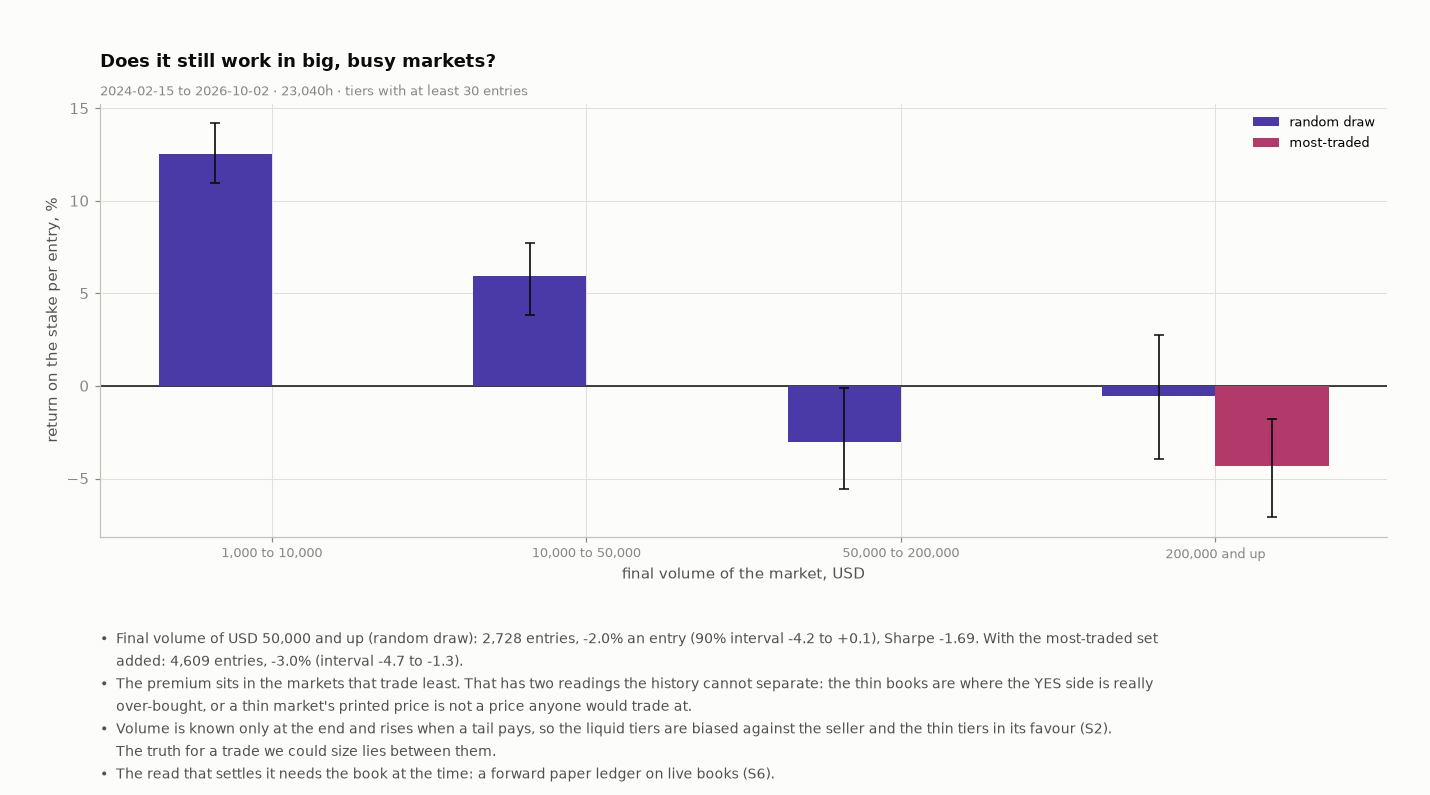

In [16]:
# ---- Test 1d: the crux. By the market's FINAL volume, in the random draw and in the most-traded set ----
HEAD_TR = run(MK_H, BAND)
def tier_of(v):
    for lo_, hi_ in zip((0.0,) + VOL_TIERS, VOL_TIERS + (1e18,)):
        if lo_ <= v < hi_:
            return (lo_, hi_)
def tier_lab(t):
    return f"under {t[1]:,.0f}" if t[0] == 0 else (f"{t[0]:,.0f} and up" if t[1] > 1e17 else f"{t[0]:,.0f} to {t[1]:,.0f}")
TIERS = list(zip((0.0,) + VOL_TIERS, VOL_TIERS + (1e18,)))
TIERS = [t_ for t_ in TIERS if sum(1 for x in BASE if t_[0] <= x["vol"] < t_[1]) >= 30]   # the frame holds nothing under USD 1,000
TIER_ROWS = []
for t_ in TIERS:
    for nm_, trs_ in (("random draw", BASE), ("most-traded", HEAD_TR)):
        s_ = [x for x in trs_ if t_[0] <= x["vol"] < t_[1]]
        if len(s_) >= 30:
            ci_ = EN.cluster_mean_ci([x["ret"] for x in s_], [x["event"] for x in s_], reps=500, seed=SEED)
            TIER_ROWS.append((t_, nm_, EN.summ(s_), ci_))
LIQ = [x for x in BASE if x["vol"] >= 5e4]
LIQ_D, LIQ_D0, LIQ_A = book(LIQ); LIQ_ST = EN.stats(LIQ_D, rf=HURDLE); LIQ_S = EN.summ(LIQ)
LIQ_CI = EN.cluster_mean_ci([x["ret"] for x in LIQ], [x["event"] for x in LIQ], reps=NBOOT, seed=SEED)
LIQ_ALL = LIQ + [x for x in HEAD_TR if x["vol"] >= 5e4]
LIQ_ALL_S = EN.summ(LIQ_ALL); LIQ_ALL_CI = EN.cluster_mean_ci([x["ret"] for x in LIQ_ALL], [x["event"] for x in LIQ_ALL], reps=NBOOT, seed=SEED)
G_LIQ = LIQ_ST["ann_ret"] > HURDLE and LIQ_CI[1] > 0
BUL = [f"Final volume of USD 50,000 and up (random draw): {LIQ_S['n']:,} entries, {LIQ_S['ret'] * 100:+.1f}% an entry (90% interval {LIQ_CI[1] * 100:+.1f} to {LIQ_CI[2] * 100:+.1f}), Sharpe {LIQ_ST['sharpe_ex']:.2f}. With the most-traded set added: {LIQ_ALL_S['n']:,} entries, {LIQ_ALL_S['ret'] * 100:+.1f}% (interval {LIQ_ALL_CI[1] * 100:+.1f} to {LIQ_ALL_CI[2] * 100:+.1f}).",
       "The premium sits in the markets that trade least. That has two readings the history cannot separate: the thin books are where the YES side is really over-bought, or a thin market's printed price is not a price anyone would trade at.",
       "Volume is known only at the end and rises when a tail pays, so the liquid tiers are biased against the seller and the thin tiers in its favour (S2). The truth for a trade we could size lies between them.",
       "The read that settles it needs the book at the time: a forward paper ledger on live books (S6)."]
fig, gs, top = mkfig(4.8, BUL)
ax = fig.add_subplot(gs[0])
labs = [tier_lab(t) for t in TIERS]; w = 0.36
for j_, (nm_, col_) in enumerate((("random draw", C_NET), ("most-traded", C_PREM_DK))):
    xv, yv, ev_, el_ = [], [], [], []
    for i_, t_ in enumerate(TIERS):
        r_ = next((r for r in TIER_ROWS if r[0] == t_ and r[1] == nm_), None)
        if r_:
            xv.append(i_ + (j_ - 0.5) * w); yv.append(r_[2]["ret"] * 100); el_.append(r_[2]["ret"] * 100 - r_[3][1] * 100); ev_.append(r_[3][2] * 100 - r_[2]["ret"] * 100)
    ax.bar(xv, yv, width=w, color=col_, zorder=3, label=nm_); ax.errorbar(xv, yv, yerr=[el_, ev_], color=INK, capsize=3, linewidth=1.1, linestyle="none", zorder=4)
ax.axhline(0, color=INK, linewidth=1.0); ax.set_xticks(range(len(TIERS))); ax.set_xticklabels(labs, fontsize=8.5); ax.set_xlabel("final volume of the market, USD"); ax.set_ylabel("return on the stake per entry, %"); ax.legend(loc="upper right", fontsize=8.5, **LEG)
ask(ax, "Does it still work in big, busy markets?", f"{iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h · tiers with at least 30 entries")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-liquidity", FIGURES)

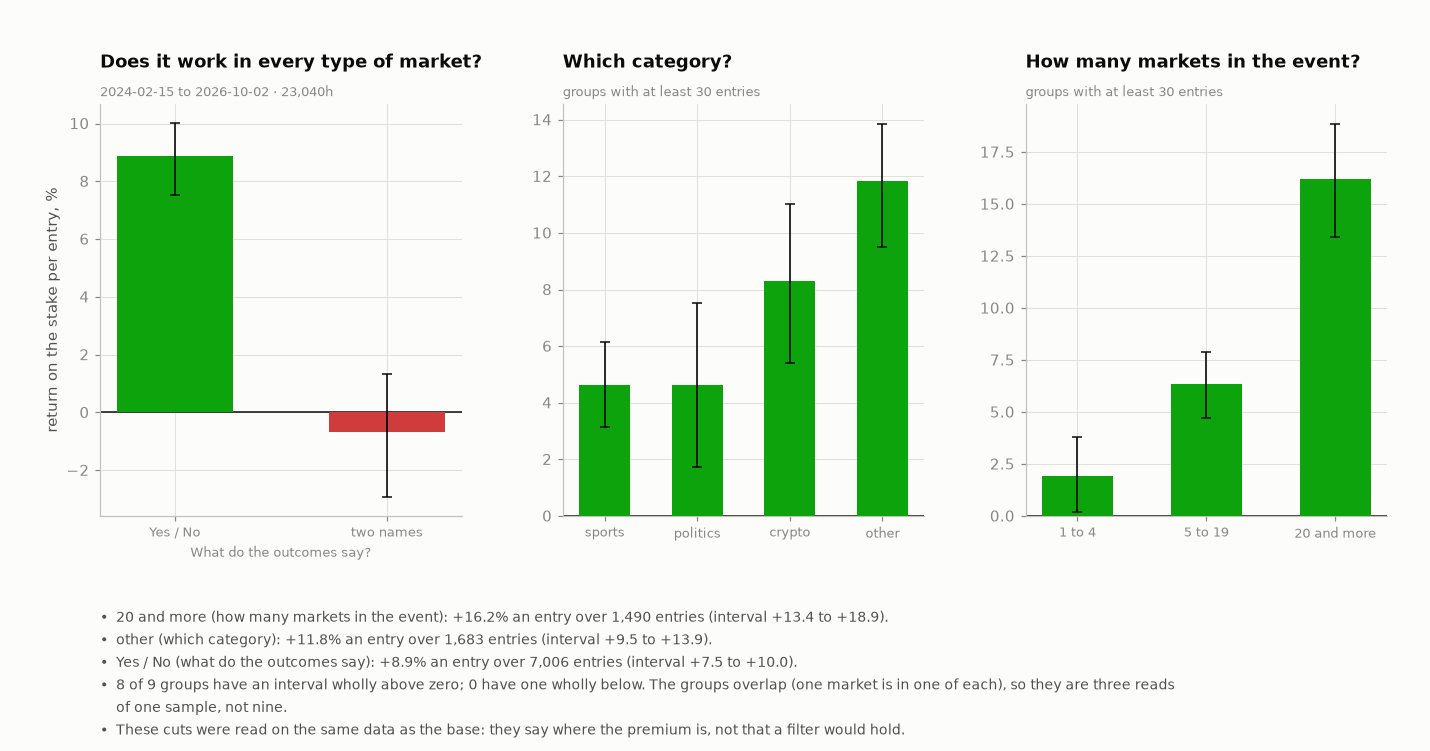

In [17]:
# ---- Test 1e: does it hold across kinds of market? the first outcome token is a "YES" only in a Yes/No market ----
def kind_rows(groups):
    out = []
    for lab_, sel_ in groups:
        s_ = [x for x in BASE if sel_(x)]
        if len(s_) >= 30:
            out.append((lab_, EN.summ(s_), EN.cluster_mean_ci([x["ret"] for x in s_], [x["event"] for x in s_], reps=500, seed=SEED)))
    return out
HAS_YN = all("yesno" in v for v in MK_R.values())          # the outcome names ride in the frozen inputs only from their second build
YN = lambda x: bool(MK_R[x["id"]]["yesno"])
KINDS = ([("What do the outcomes say?", kind_rows([("Yes / No", YN), ("two names", lambda x: not YN(x))]))] if HAS_YN else []) + [
         ("Which category?", kind_rows([(g_, lambda x, g_=g_: x["grp"] == g_) for g_ in ("sports", "politics", "crypto", "other")])),
         ("How many markets in the event?", kind_rows([("1 to 4", lambda x: x["ev_n"] < 5), ("5 to 19", lambda x: 5 <= x["ev_n"] < 20), ("20 and more", lambda x: x["ev_n"] >= 20)]))]
POS = [(t_, l_, m_, c_) for t_, rows_ in KINDS for l_, m_, c_ in rows_ if c_[1] > 0]
NEGK = [(t_, l_, m_, c_) for t_, rows_ in KINDS for l_, m_, c_ in rows_ if c_[2] < 0]
BUL = [f"{l_} ({t_.rstrip('?').lower()}): {m_['ret'] * 100:+.1f}% an entry over {m_['n']:,} entries (interval {c_[1] * 100:+.1f} to {c_[2] * 100:+.1f})." for t_, l_, m_, c_ in sorted([(t_, l_, m_, c_) for t_, rows_ in KINDS for l_, m_, c_ in rows_], key=lambda r_: -r_[2]["ret"])[:3]] + [
       f"{len(POS)} of {sum(len(r_) for _, r_ in KINDS)} groups have an interval wholly above zero; {len(NEGK)} have one wholly below. The groups overlap (one market is in one of each), so they are three reads of one sample, not nine.",
       "These cuts were read on the same data as the base: they say where the premium is, not that a filter would hold."]
fig, gs, top = mkfig(4.6, BUL, ncols=len(KINDS), wspace=0.28)
for j_, (ttl_, rows_) in enumerate(KINDS):
    ax = fig.add_subplot(gs[0, j_])
    yv = [m_["ret"] * 100 for _, m_, _ in rows_]; el_ = [m_["ret"] * 100 - c_[1] * 100 for _, m_, c_ in rows_]; eh_ = [c_[2] * 100 - m_["ret"] * 100 for _, m_, c_ in rows_]
    ax.bar(range(len(yv)), yv, color=[GOOD if v_ > 0 else CRIT for v_ in yv], width=0.55, zorder=3); ax.errorbar(range(len(yv)), yv, yerr=[el_, eh_], color=INK, capsize=3, linewidth=1.1, linestyle="none", zorder=4)
    ax.axhline(0, color=INK, linewidth=1.0); ax.set_xticks(range(len(yv))); ax.set_xticklabels([l_ for l_, _, _ in rows_], fontsize=8.5)
    if j_ == 0:
        ax.set_xlabel(ttl_, color=MUTED, fontsize=8.5); ax.set_ylabel("return on the stake per entry, %"); ask(ax, "Does it work in every type of market?", f"{iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h")
    else:
        ax.set_title(ttl_, loc="left", pad=24, fontsize=11.5, fontweight="bold"); ax.text(0.0, 1.012, "groups with at least 30 entries", transform=ax.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-kinds", FIGURES)

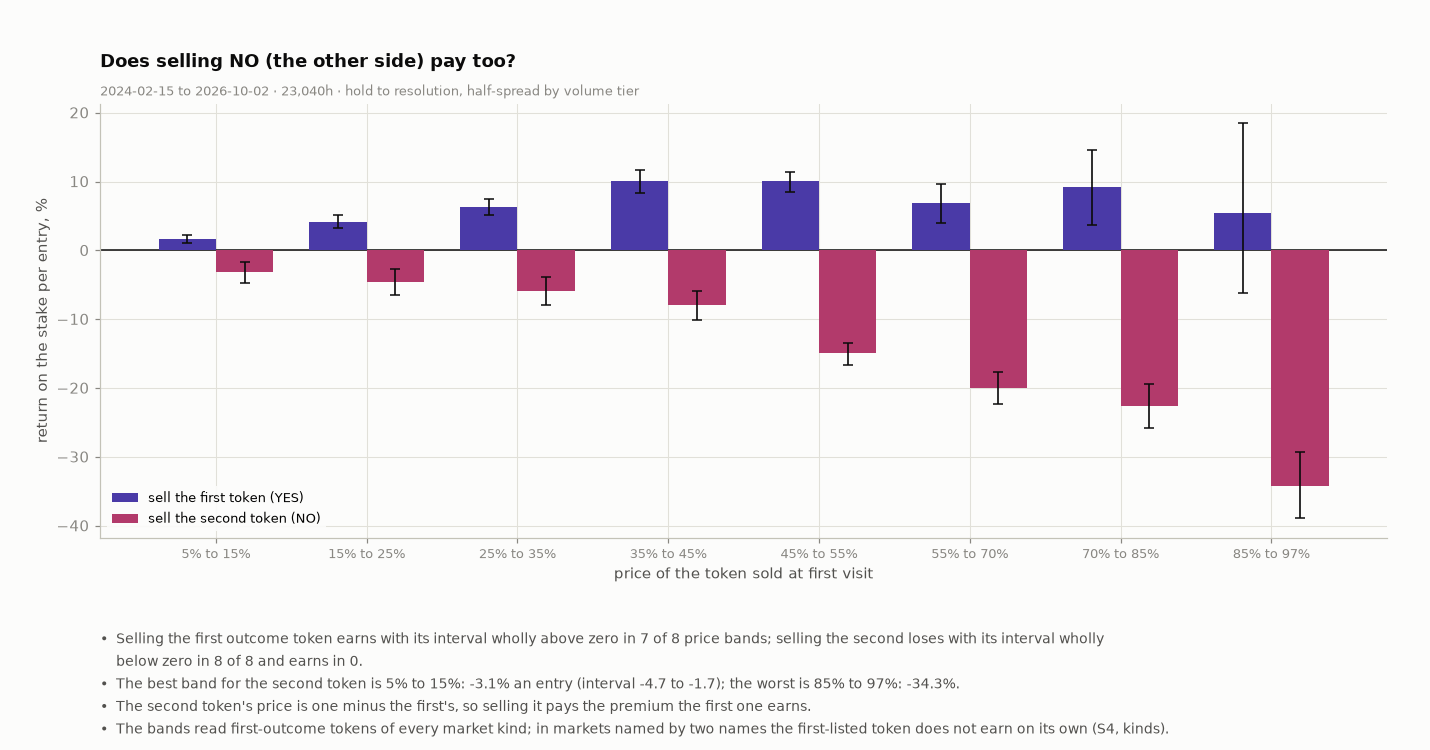

In [18]:
# ---- Test 1f: is the second outcome token ever worth selling? both tokens, every price band, the same costs ----
SIDE_BANDS = [(0.05, 0.15), (0.15, 0.25), (0.25, 0.35), (0.35, 0.45), (0.45, 0.55), (0.55, 0.70), (0.70, 0.85), (0.85, 0.97)]
SIDE_ROWS = []
for lo_, hi_ in SIDE_BANDS:
    trs_ = run(MK_R, (lo_, hi_), tokens=(0, 1))
    for k_ in (0, 1):
        s_ = [x for x in trs_ if x["k"] == k_]
        if len(s_) >= 60:
            SIDE_ROWS.append(((lo_, hi_), k_, EN.summ(s_), EN.cluster_mean_ci([x["ret"] for x in s_], [x["event"] for x in s_], reps=500, seed=SEED)))
S0_ = [r_ for r_ in SIDE_ROWS if r_[1] == 0]; S1_ = [r_ for r_ in SIDE_ROWS if r_[1] == 1]
N0_UP = sum(1 for r_ in S0_ if r_[3][1] > 0); N1_DN = sum(1 for r_ in S1_ if r_[3][2] < 0); N1_UP = sum(1 for r_ in S1_ if r_[3][1] > 0)
BEST1 = max(S1_, key=lambda r_: r_[2]["ret"]); WORST1 = min(S1_, key=lambda r_: r_[2]["ret"])
BUL = [f"Selling the first outcome token earns with its interval wholly above zero in {N0_UP} of {len(S0_)} price bands; selling the second loses with its interval wholly below zero in {N1_DN} of {len(S1_)} and earns in {N1_UP}.",
       f"The best band for the second token is {BEST1[0][0]:.0%} to {BEST1[0][1]:.0%}: {BEST1[2]['ret'] * 100:+.1f}% an entry (interval {BEST1[3][1] * 100:+.1f} to {BEST1[3][2] * 100:+.1f}); the worst is {WORST1[0][0]:.0%} to {WORST1[0][1]:.0%}: {WORST1[2]['ret'] * 100:+.1f}%.",
       "The second token's price is one minus the first's, so selling it pays the premium the first one earns.",
       "The bands read first-outcome tokens of every market kind; in markets named by two names the first-listed token does not earn on its own (S4, kinds)."]
fig, gs, top = mkfig(4.8, BUL)
ax = fig.add_subplot(gs[0])
w = 0.38
for j_, (rows_, col_, nm_) in enumerate(((S0_, C_NET, "sell the first token (YES)"), (S1_, C_PREM_DK, "sell the second token (NO)"))):
    xv = [SIDE_BANDS.index(r_[0]) + (j_ - 0.5) * w for r_ in rows_]; yv = [r_[2]["ret"] * 100 for r_ in rows_]
    ax.bar(xv, yv, width=w, color=col_, zorder=3, label=nm_)
    ax.errorbar(xv, yv, yerr=[[r_[2]["ret"] * 100 - r_[3][1] * 100 for r_ in rows_], [r_[3][2] * 100 - r_[2]["ret"] * 100 for r_ in rows_]], color=INK, capsize=3, linewidth=1.1, linestyle="none", zorder=4)
ax.axhline(0, color=INK, linewidth=1.0); ax.set_xticks(range(len(SIDE_BANDS))); ax.set_xticklabels([f"{a_:.0%} to {b_:.0%}" for a_, b_ in SIDE_BANDS], fontsize=8.5)
ax.set_xlabel("price of the token sold at first visit"); ax.set_ylabel("return on the stake per entry, %"); ax.legend(loc="lower left", fontsize=8.5, **LEG)
ask(ax, "Does selling NO (the other side) pay too?", f"{iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h · hold to resolution, half-spread by volume tier")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-sides", FIGURES)

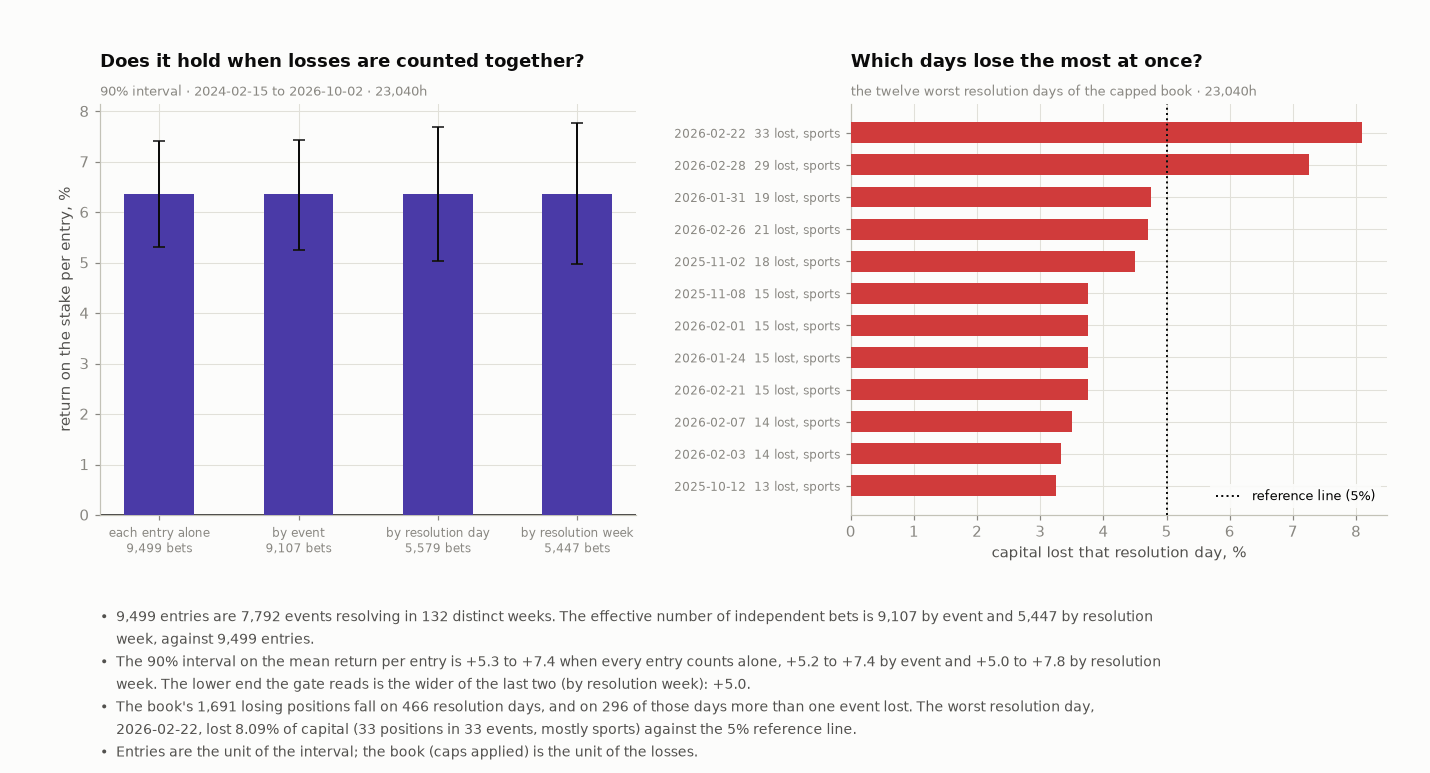

In [19]:
# ---- Test 1f: losses cluster. How many independent bets are there, what does a date-block interval say, what is the worst concurrent-loss day? ----
RET_E = [x["ret"] for x in BASE]; EVK = [x["event"] for x in BASE]
DYK = [RK.day_key(x["t_out"]) for x in BASE]; WKK = [RK.week_key(x["t_out"]) for x in BASE]
SCHEMES = [("each entry alone", list(range(len(BASE)))), ("by event", EVK), ("by resolution day", DYK), ("by resolution week", WKK)]
CLU = []
for nm_, ks_ in SCHEMES:
    CLU.append((nm_, len(set(ks_)), RK.effective_n(RET_E, ks_), EN.cluster_mean_ci(RET_E, ks_, reps=NBOOT, seed=SEED)))
CLU_D = {c_[0]: c_ for c_ in CLU}
CL_LO = min(CLU_D["by event"][3][1], CLU_D["by resolution week"][3][1])
CL_WIDER = "by event" if CLU_D["by event"][3][1] <= CLU_D["by resolution week"][3][1] else "by resolution week"
LD = RK.resolution_loss_days(B_ACC, CLIP)
LD_TOP = sorted(LD.items(), key=lambda kv: kv[1]["loss"])[:12]
WORST_D, WORST_O = LD_TOP[0]
WORST_LOSS = -WORST_O["loss"]
N_LOSS_DAYS = len(LD); N_LOSERS = sum(o_["n"] for o_ in LD.values()); N_MULTI = sum(1 for o_ in LD.values() if len(o_["events"]) > 1)
day_iso = lambda d_: dt.datetime.fromtimestamp(d_ * DAYSEC, dt.timezone.utc).strftime("%Y-%m-%d")
top_grp = lambda o_: max(o_["groups"], key=o_["groups"].get)
BUL = [f"{len(BASE):,} entries are {CLU_D['by event'][1]:,} events resolving in {CLU_D['by resolution week'][1]:,} distinct weeks. The effective number of independent bets is {CLU_D['by event'][2]:,.0f} by event and {CLU_D['by resolution week'][2]:,.0f} by resolution week, against {len(BASE):,} entries.",
       f"The {CI_PCT}% interval on the mean return per entry is {CLU_D['each entry alone'][3][1] * 100:+.1f} to {CLU_D['each entry alone'][3][2] * 100:+.1f} when every entry counts alone, {CLU_D['by event'][3][1] * 100:+.1f} to {CLU_D['by event'][3][2] * 100:+.1f} by event and {CLU_D['by resolution week'][3][1] * 100:+.1f} to {CLU_D['by resolution week'][3][2] * 100:+.1f} by resolution week. The lower end the gate reads is the wider of the last two ({CL_WIDER}): {CL_LO * 100:+.1f}.",
       f"The book's {N_LOSERS:,} losing positions fall on {N_LOSS_DAYS:,} resolution days, and on {N_MULTI:,} of those days more than one event lost. The worst resolution day, {day_iso(WORST_D)}, lost {WORST_LOSS * 100:.2f}% of capital ({WORST_O['n']} positions in {len(WORST_O['events'])} events, mostly {top_grp(WORST_O)}) against the {DD_LIMIT:.0%} reference line.",
       "Entries are the unit of the interval; the book (caps applied) is the unit of the losses."]
fig, gs, top = mkfig(4.6, BUL, ncols=2, wspace=0.40)
ax = fig.add_subplot(gs[0, 0])
yv = [c_[3][0] * 100 for c_ in CLU]; el_ = [c_[3][0] * 100 - c_[3][1] * 100 for c_ in CLU]; eh_ = [c_[3][2] * 100 - c_[3][0] * 100 for c_ in CLU]
ax.bar(range(len(CLU)), yv, color=C_NET, width=0.5, zorder=3); ax.errorbar(range(len(CLU)), yv, yerr=[el_, eh_], color=INK, capsize=4, linewidth=1.3, linestyle="none", zorder=4)
ax.axhline(0, color=INK, linewidth=1.0); ax.set_xticks(range(len(CLU))); ax.set_xticklabels([f"{c_[0]}\n{c_[2]:,.0f} bets" for c_ in CLU], fontsize=8); ax.set_ylabel("return on the stake per entry, %")
ask(ax, "Does it hold when losses are counted together?", f"{CI_PCT}% interval · {iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h")
ax = fig.add_subplot(gs[0, 1])
ax.barh(range(len(LD_TOP))[::-1], [-o_["loss"] * 100 for _, o_ in LD_TOP], color=CRIT, height=0.65, zorder=3)
ax.set_yticks(range(len(LD_TOP))[::-1]); ax.set_yticklabels([f"{day_iso(d_)}  {o_['n']} lost, {top_grp(o_)}" for d_, o_ in LD_TOP], fontsize=8)
ax.axvline(DD_LIMIT * 100, color=INK, linewidth=1.3, linestyle=":", zorder=4, label=f"reference line ({DD_LIMIT:.0%})"); ax.set_xlabel("capital lost that resolution day, %"); ax.legend(loc="lower right", fontsize=8.5, **LEG)
ax.set_title("Which days lose the most at once?", loc="left", pad=24, fontsize=11.5, fontweight="bold")
ax.text(0.0, 1.012, f"the twelve worst resolution days of the capped book · {HOURS:,.0f}h", transform=ax.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-clusters", FIGURES)

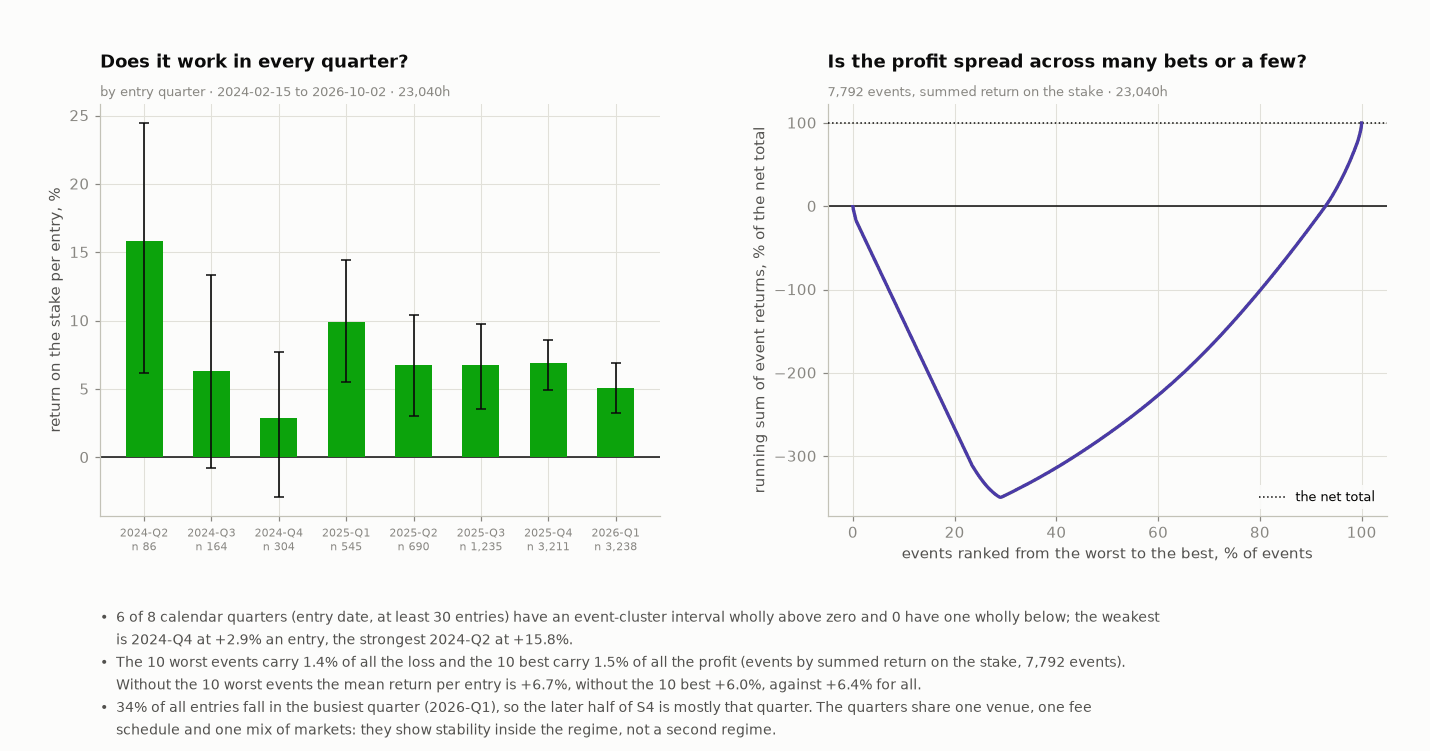

In [20]:
# ---- Test 1h: by calendar quarter, not only halves; and how much of the P&L sits in a few events ----
qkey = lambda t_: (lambda d_: f"{d_.year}-Q{(d_.month - 1) // 3 + 1}")(dt.datetime.fromtimestamp(t_, dt.timezone.utc))
QROWS = []
for q_ in sorted({qkey(x["t_in"]) for x in BASE}):
    s_ = [x for x in BASE if qkey(x["t_in"]) == q_]
    if len(s_) >= 30:
        QROWS.append((q_, EN.summ(s_), EN.cluster_mean_ci([x["ret"] for x in s_], [x["event"] for x in s_], reps=500, seed=SEED)))
EVP = RK.event_pnl(BASE, 1.0)
EV_SORT = sorted(EVP.items(), key=lambda kv: kv[1])
WORST_EV = {e_ for e_, _ in EV_SORT[:TOP_K]}; BEST_EV = {e_ for e_, _ in EV_SORT[-TOP_K:]}
GROSS_P = sum(v_ for v_ in EVP.values() if v_ > 0); GROSS_L = -sum(v_ for v_ in EVP.values() if v_ < 0)
SH_BEST = sum(EVP[e_] for e_ in BEST_EV if EVP[e_] > 0) / GROSS_P; SH_WORST = -sum(EVP[e_] for e_ in WORST_EV if EVP[e_] < 0) / GROSS_L
M_NO_WORST = RK.mean_without(BASE, WORST_EV); M_NO_BEST = RK.mean_without(BASE, BEST_EV)
Q_POS = sum(1 for _, m_, c_ in QROWS if c_[1] > 0); Q_NEG = sum(1 for _, m_, c_ in QROWS if c_[2] < 0)
BUL = [f"{Q_POS} of {len(QROWS)} calendar quarters (entry date, at least 30 entries) have an event-cluster interval wholly above zero and {Q_NEG} have one wholly below; the weakest is {min(QROWS, key=lambda r_: r_[1]['ret'])[0]} at {min(m_['ret'] for _, m_, _ in QROWS) * 100:+.1f}% an entry, the strongest {max(QROWS, key=lambda r_: r_[1]['ret'])[0]} at {max(m_['ret'] for _, m_, _ in QROWS) * 100:+.1f}%.",
       f"The {TOP_K} worst events carry {SH_WORST * 100:.1f}% of all the loss and the {TOP_K} best carry {SH_BEST * 100:.1f}% of all the profit (events by summed return on the stake, {len(EVP):,} events). Without the {TOP_K} worst events the mean return per entry is {M_NO_WORST * 100:+.1f}%, without the {TOP_K} best {M_NO_BEST * 100:+.1f}%, against {SUM['ret'] * 100:+.1f}% for all.",
       f"{max(m_['n'] for _, m_, _ in QROWS) / len(BASE) * 100:.0f}% of all entries fall in the busiest quarter ({max(QROWS, key=lambda r_: r_[1]['n'])[0]}), so the later half of S4 is mostly that quarter. The quarters share one venue, one fee schedule and one mix of markets: they show stability inside the regime, not a second regime."]
fig, gs, top = mkfig(4.6, BUL, ncols=2, wspace=0.30, ratios=None)
ax = fig.add_subplot(gs[0, 0])
yv = [m_["ret"] * 100 for _, m_, _ in QROWS]; el_ = [m_["ret"] * 100 - c_[1] * 100 for _, m_, c_ in QROWS]; eh_ = [c_[2] * 100 - m_["ret"] * 100 for _, m_, c_ in QROWS]
ax.bar(range(len(yv)), yv, color=[GOOD if v_ > 0 else CRIT for v_ in yv], width=0.55, zorder=3); ax.errorbar(range(len(yv)), yv, yerr=[el_, eh_], color=INK, capsize=3, linewidth=1.1, linestyle="none", zorder=4)
ax.axhline(0, color=INK, linewidth=1.0); ax.set_xticks(range(len(yv))); ax.set_xticklabels([f"{q_}\nn {m_['n']:,}" for q_, m_, _ in QROWS], fontsize=7.5); ax.set_ylabel("return on the stake per entry, %")
ask(ax, "Does it work in every quarter?", f"by entry quarter · {iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h")
ax = fig.add_subplot(gs[0, 1])
cum_ = np.cumsum([v_ for _, v_ in EV_SORT]); tot_ = cum_[-1]
ax.plot(np.arange(1, len(cum_) + 1) / len(cum_) * 100, cum_ / abs(tot_) * 100, color=C_NET, linewidth=2.2, zorder=4)
ax.axhline(0, color=INK, linewidth=1.0); ax.axhline(100, color=INK, linewidth=1.0, linestyle=":", zorder=3, label="the net total")
ax.set_xlabel("events ranked from the worst to the best, % of events"); ax.set_ylabel("running sum of event returns, % of the net total"); ax.legend(loc="lower right", fontsize=8.5, **LEG)
ax.set_title("Is the profit spread across many bets or a few?", loc="left", pad=24, fontsize=11.5, fontweight="bold")
ax.text(0.0, 1.012, f"{len(EVP):,} events, summed return on the stake · {HOURS:,.0f}h", transform=ax.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-periods", FIGURES)

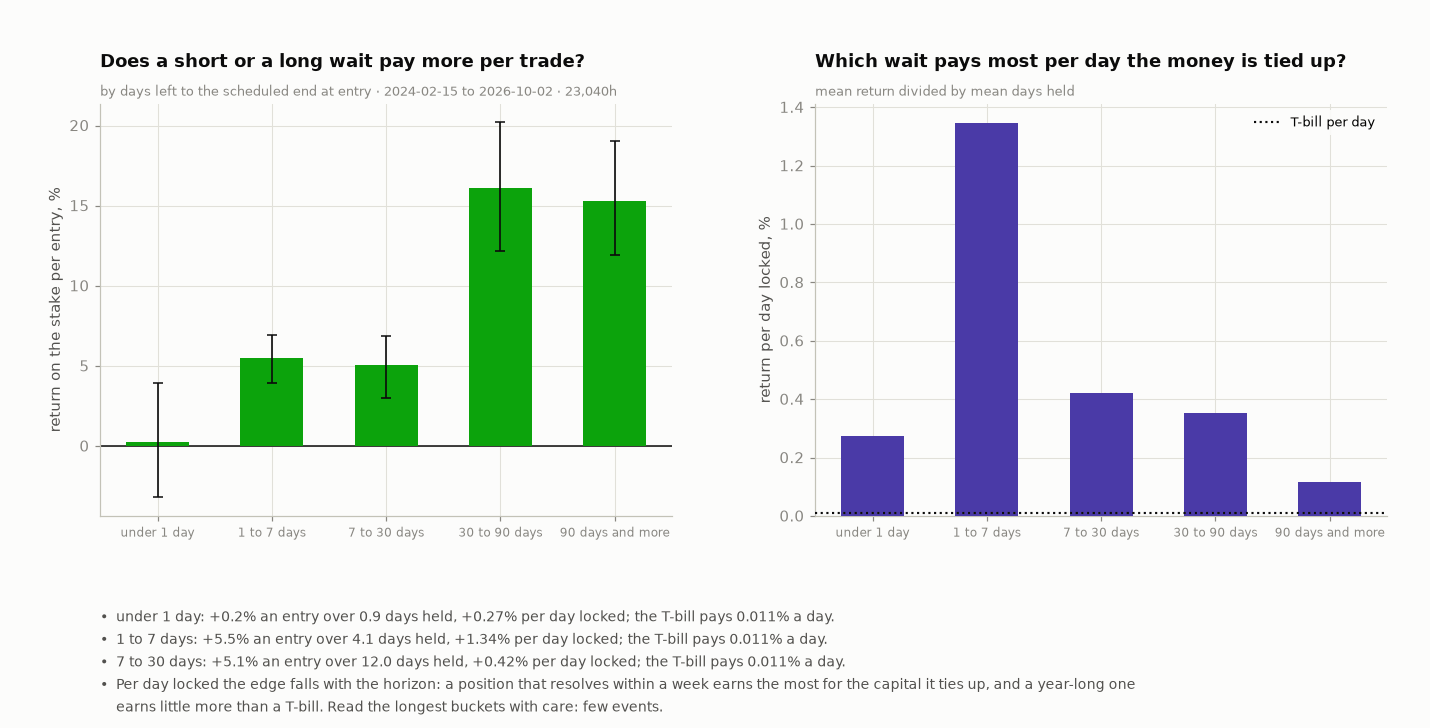

In [21]:
# ---- Test 2b: how long to hold? by days left to the scheduled end at entry ----
BKT = [(0, 1), (1, 7), (7, 30), (30, 90), (90, 1e9)]
HOLD_ROWS = []
for a_, b_ in BKT:
    s_ = [x for x in BASE if a_ <= x["sched_left"] < b_]
    if len(s_) >= 30:
        ci_ = EN.cluster_mean_ci([x["ret"] for x in s_], [x["event"] for x in s_], reps=500, seed=SEED)
        m_ = EN.summ(s_)
        HOLD_ROWS.append(((a_, b_), m_, ci_, ((1 + m_["ret"]) ** (365 / max(m_["days"], 0.5)) - 1) if m_["ret"] > -1 else float("nan")))
labs = [("under 1 day" if b_ == 1 else f"{a_:g} to {b_:g} days" if b_ < 1e8 else f"{a_:g} days and more") for (a_, b_), _, _, _ in HOLD_ROWS]
BUL = [f"{labs[i_]}: {m_['ret'] * 100:+.1f}% an entry over {m_['days']:.1f} days held, {m_['per_day'] * 100:+.2f}% per day locked; the T-bill pays {HURDLE / 365 * 100:.3f}% a day." for i_, ((a_, b_), m_, ci_, an_) in enumerate(HOLD_ROWS)][:3] + [
       "Per day locked the edge falls with the horizon: a position that resolves within a week earns the most for the capital it ties up, and a year-long one earns little more than a T-bill. Read the longest buckets with care: few events."]
fig, gs, top = mkfig(4.6, BUL, ncols=2, wspace=0.25)
ax = fig.add_subplot(gs[0, 0])
yv = [m_["ret"] * 100 for _, m_, _, _ in HOLD_ROWS]; el_ = [m_["ret"] * 100 - c_[1] * 100 for _, m_, c_, _ in HOLD_ROWS]; eh_ = [c_[2] * 100 - m_["ret"] * 100 for _, m_, c_, _ in HOLD_ROWS]
ax.bar(range(len(yv)), yv, color=[GOOD if v_ > 0 else CRIT for v_ in yv], width=0.55, zorder=3); ax.errorbar(range(len(yv)), yv, yerr=[el_, eh_], color=INK, capsize=3, linewidth=1.1, linestyle="none", zorder=4)
ax.axhline(0, color=INK, linewidth=1.0); ax.set_xticks(range(len(yv))); ax.set_xticklabels(labs, fontsize=8); ax.set_ylabel("return on the stake per entry, %")
ask(ax, "Does a short or a long wait pay more per trade?", f"by days left to the scheduled end at entry · {iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h")
ax = fig.add_subplot(gs[0, 1])
pd_ = [m_["per_day"] * 100 for _, m_, _, _ in HOLD_ROWS]
ax.bar(range(len(pd_)), pd_, color=C_NET, width=0.55, zorder=3); ax.axhline(HURDLE / 365 * 100, color=INK, linewidth=1.4, linestyle=":", zorder=4, label="T-bill per day")
ax.set_xticks(range(len(pd_))); ax.set_xticklabels(labs, fontsize=8); ax.set_ylabel("return per day locked, %"); ax.legend(loc="upper right", fontsize=8.5, **LEG)
ax.set_title("Which wait pays most per day the money is tied up?", loc="left", pad=24, fontsize=11.5, fontweight="bold")
ax.text(0.0, 1.012, "mean return divided by mean days held", transform=ax.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-hold", FIGURES)

**Test 4.** A fixed grid of rules (band edges, take-profit, stop, time stop, horizon cap, category cap), every book kept, none chosen.

In [22]:
# ---- the rule grid: every book built by the engine and verified, the first half beside the later half, nothing chosen ----
from scipy.stats import spearmanr
t0_ = time.time()
TASKS = TG.make_tasks(LOS, HIS, TPS, SLS, TMAXS)
PARAMS = dict(input=INPUT_NAME, slip=SLIP_PRIMARY, skip_last=SKIP_LAST, min_obs=MIN_OBS, split=TMED, clip=CLIP, rf=HURDLE, horizons=HORIZONS, catcaps=CATCAPS, min_pos=MIN_POS)
ROWS, N_VER = TG.sweep(TASKS, PARAMS, workers=WORKERS)
DF = pd.DataFrame(ROWS)
VER["total"] += N_VER; VER["passed"] += N_VER; VER["books"] += N_VER
assert N_VER >= len(DF) > 50, (N_VER, len(DF))
SH_TR, SH_TE = float((DF.tr_ann > HURDLE).mean()), float((DF.te_ann > HURDLE).mean())
SH_BOTH = float(((DF.tr_ann > HURDLE) & (DF.te_ann > HURDLE)).mean())
RANK_RHO = float(spearmanr(DF.tr_sharpe, DF.te_sharpe)[0])
G_GRID = SH_BOTH >= SHARE_GATE
DIMS = [("lo", "band low edge", lambda v: f"{v:.0%}"), ("hi", "band high edge", lambda v: f"{v:.0%}"), ("tp", "take-profit", lambda v: "hold" if pd.isna(v) else f"{v:.2f}"),
        ("sl", "stop", lambda v: "none" if pd.isna(v) else f"{v:.2f}"), ("tmax", "time stop, days", lambda v: "none" if pd.isna(v) else f"{int(v)}"),
        ("hz", "ends within, days", lambda v: "any" if pd.isna(v) else f"{int(v)}"), ("cc", "category cap", lambda v: "none" if pd.isna(v) else f"{v:.0%}")]
DIMTAB = {}
for col_, nm_, f_ in DIMS:
    g_ = DF.assign(k=DF[col_]).groupby("k", dropna=False).agg(n=("te_ann", "size"), med=("te_ann", "median"), sh=("te_sharpe", "median"), tr=("tr_ann", "median"))
    DIMTAB[col_] = [(f_(k_), int(r_["n"]), float(r_["med"]), float(r_["sh"]), float(r_["tr"])) for k_, r_ in g_.iterrows()]
SPREAD_ = {c_: max(r_[2] for r_ in v_) - min(r_[2] for r_ in v_) for c_, v_ in DIMTAB.items()}
BIGGEST = max(SPREAD_, key=SPREAD_.get); NAMES_ = {c_: n_ for c_, n_, _ in DIMS}
CC_TXT = ", ".join(f"cap {a_}: Sharpe {s_:.2f}, {m_ * 100:+.0f}% a year" for a_, _, m_, s_, _ in DIMTAB["cc"])
SL_TXT = ", ".join(f"stop {a_}: Sharpe {s_:.2f}, {m_ * 100:+.0f}% a year" for a_, _, m_, s_, _ in DIMTAB["sl"])
TM_TXT = ", ".join(f"time stop {a_}: Sharpe {s_:.2f}, {m_ * 100:+.0f}% a year" for a_, _, m_, s_, _ in DIMTAB["tmax"])
TP_TXT = ", ".join(f"take-profit {a_}: Sharpe {s_:.2f}, {m_ * 100:+.0f}% a year" for a_, _, m_, s_, _ in DIMTAB["tp"])
DF_BASE = DF[(DF.lo == BAND[0]) & (DF.hi == BAND[1]) & DF.tp.isna() & DF.sl.isna() & DF.tmax.isna() & DF.hz.isna() & DF.cc.isna()]
print(f"{len(TASKS):,} rules, {len(DF):,} books built and verified in {time.time() - t0_:.0f}s; split at {iso_(TMED)[:10]}; the reference rule is {'in' if len(DF_BASE) else 'not in'} the grid")

64 rules, 256 books built and verified in 20s; split at 2025-11-23; the reference rule is in the grid


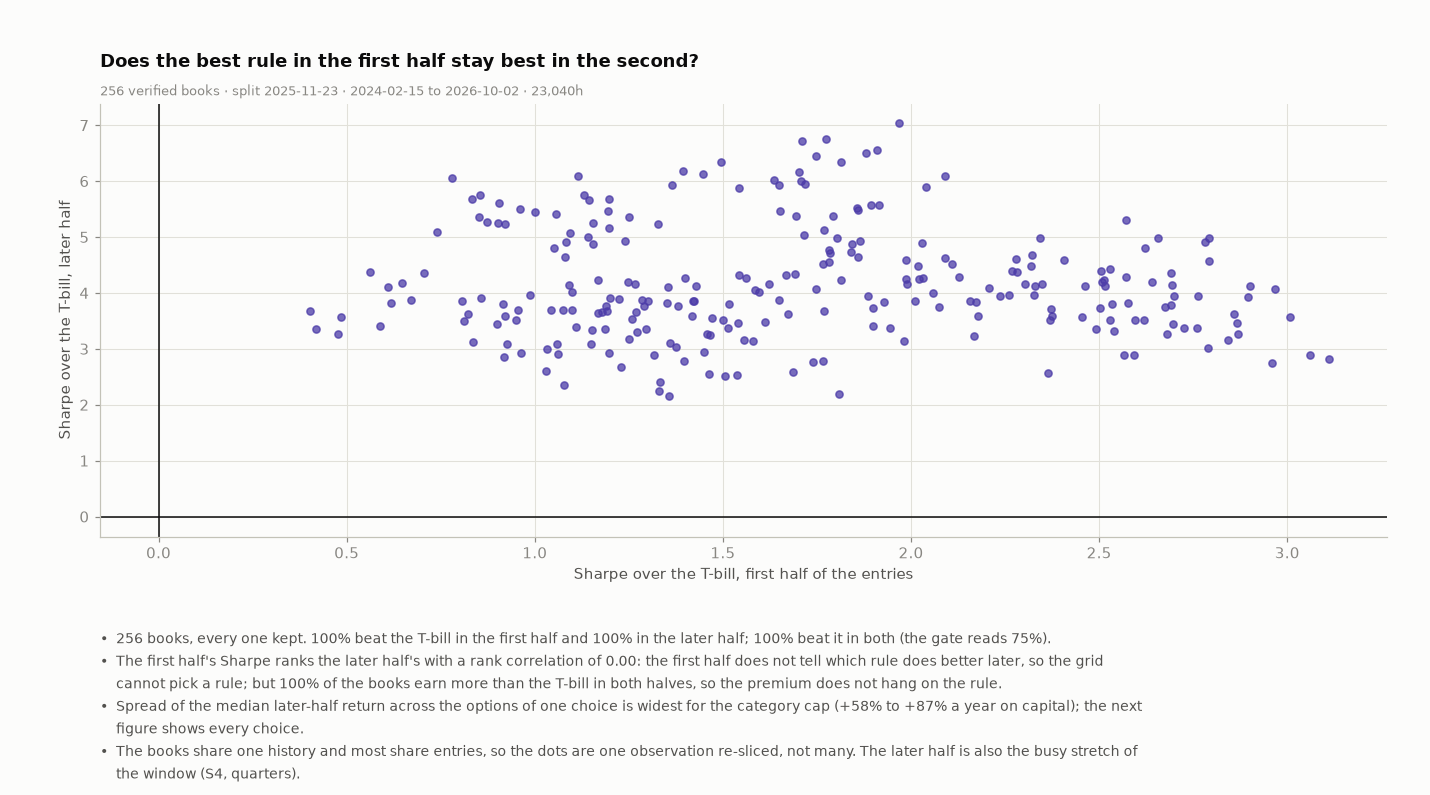

In [23]:
# ---- does a rule that does well in the first half do well in the later half? one dot a book, nothing chosen ----
BUL = [f"{len(DF):,} books, every one kept. {SH_TR * 100:.0f}% beat the T-bill in the first half and {SH_TE * 100:.0f}% in the later half; {SH_BOTH * 100:.0f}% beat it in both (the gate reads {SHARE_GATE:.0%}).",
       f"The first half's Sharpe ranks the later half's with a rank correlation of {RANK_RHO:.2f}: " + ("a rule that does well early mostly does well later." if RANK_RHO >= 0.3 else f"the first half does not tell which rule does better later, so the grid cannot pick a rule; but {SH_BOTH * 100:.0f}% of the books earn more than the T-bill in both halves, so the premium does not hang on the rule."),
       f"Spread of the median later-half return across the options of one choice is widest for the {NAMES_[BIGGEST]} ({min(r_[2] for r_ in DIMTAB[BIGGEST]) * 100:+.0f}% to {max(r_[2] for r_ in DIMTAB[BIGGEST]) * 100:+.0f}% a year on capital); the next figure shows every choice.",
       "The books share one history and most share entries, so the dots are one observation re-sliced, not many. The later half is also the busy stretch of the window (S4, quarters)."]
fig, gs, top = mkfig(4.8, BUL)
ax = fig.add_subplot(gs[0])
ax.scatter(DF.tr_sharpe, DF.te_sharpe, s=22, color=C_NET, alpha=0.75, zorder=3)
ax.axhline(0, color=INK, linewidth=1.0); ax.axvline(0, color=INK, linewidth=1.0)
ax.set_xlabel("Sharpe over the T-bill, first half of the entries"); ax.set_ylabel("Sharpe over the T-bill, later half")
ask(ax, "Does the best rule in the first half stay best in the second?", f"{len(DF):,} verified books · split {iso_(TMED)[:10]} · {iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-rules-carry", FIGURES)

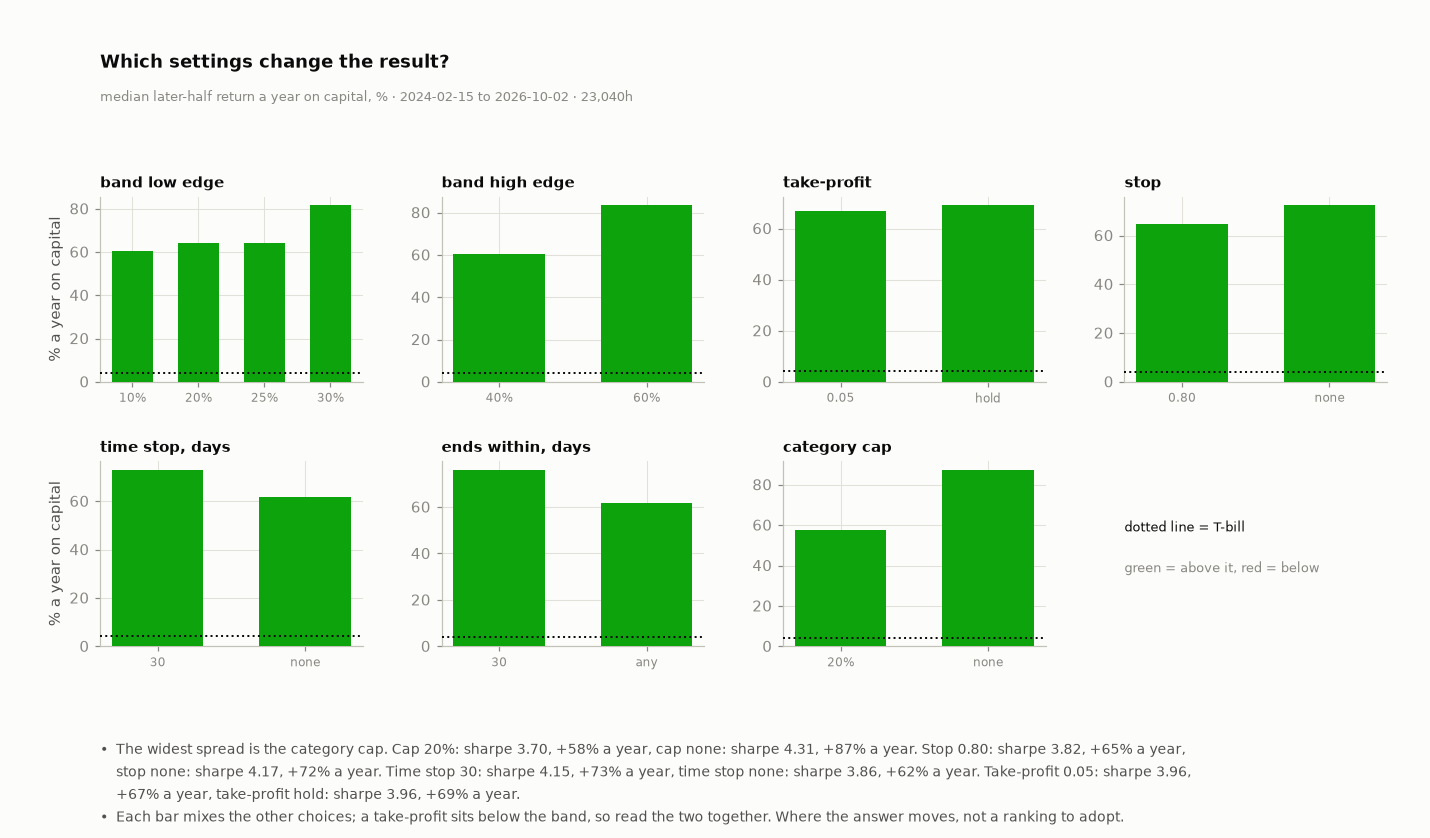

In [24]:
# ---- which choices move the answer? the median later-half return by option, no choice made ----
cc_ = {a_: (m_, s_) for a_, _, m_, s_, _ in DIMTAB["cc"]}
BUL = [f"The widest spread is the {NAMES_[BIGGEST]}. {CC_TXT.capitalize()}. {SL_TXT.capitalize()}. {TM_TXT.capitalize()}. {TP_TXT.capitalize()}.",
       "Each bar mixes the other choices; a take-profit sits below the band, so read the two together. Where the answer moves, not a ranking to adopt."]
fig, gs, top = mkfig(5.8, BUL, nrows=3, ncols=4, wspace=0.3, hspace=0.62, ratios=[0.07, 1, 1])
ax = fig.add_subplot(gs[0, :]); ax.axis("off")
ask(ax, "Which settings change the result?", f"median later-half return a year on capital, % · {iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h")
for j_, (col_, nm_, f_) in enumerate(DIMS):
    ax = fig.add_subplot(gs[1 + j_ // 4, j_ % 4])
    labs_ = [a_ for a_, _, _, _, _ in DIMTAB[col_]]; vals_ = [m_ * 100 for _, _, m_, _, _ in DIMTAB[col_]]
    ax.bar(range(len(vals_)), vals_, color=[GOOD if v_ > HURDLE * 100 else CRIT for v_ in vals_], width=0.62, zorder=3); ax.axhline(HURDLE * 100, color=INK, linewidth=1.3, linestyle=":", zorder=4)
    ax.set_xticks(range(len(vals_))); ax.set_xticklabels(labs_, fontsize=8)
    ax.set_title(nm_, loc="left", pad=6, fontsize=10, fontweight="bold")
    if j_ % 4 == 0:
        ax.set_ylabel("% a year on capital")
ax_ = fig.add_subplot(gs[2, 3]); ax_.axis("off")
ax_.text(0.0, 0.62, "dotted line = T-bill", color=INK, fontsize=8.5); ax_.text(0.0, 0.40, "green = above it, red = below", color=MUTED, fontsize=8.5)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-rule-dims", FIGURES)

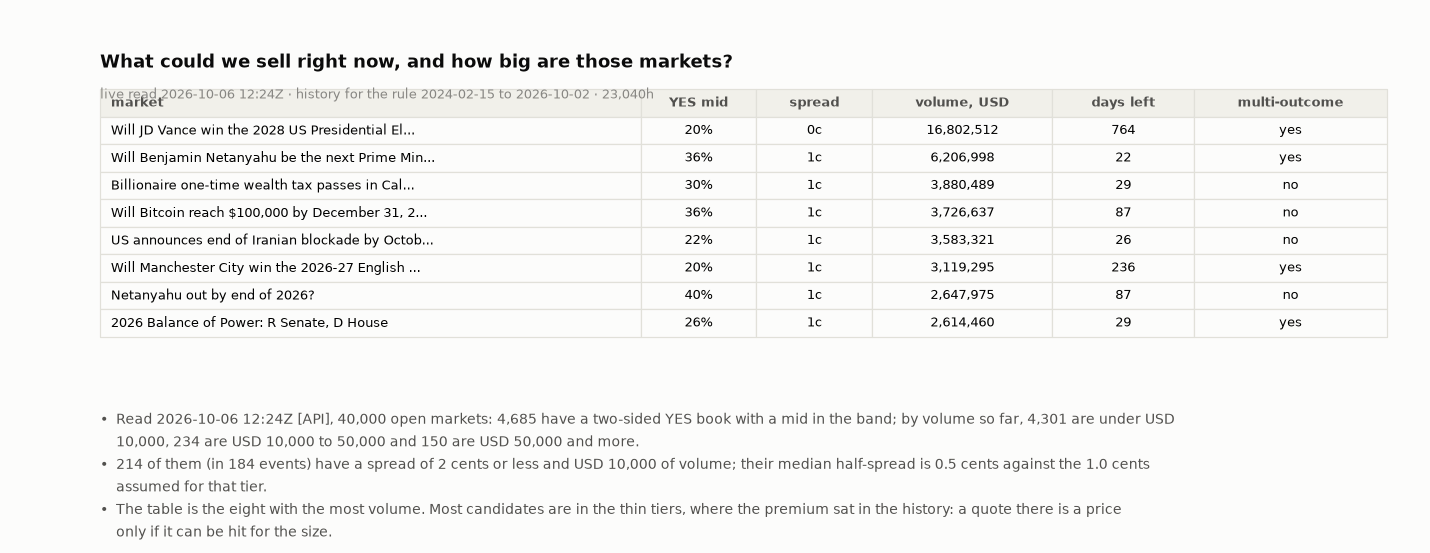

In [25]:
# ---- the live read: which tokens would the rule sell right now, and what do their books say? ----
from fundplat.data.predmkts import polymarket as PM
NOW = time.time()
for _try in range(5):                      # the venue closes a connection now and then; a read that fails five times in a row stops the build
    try:
        LIVE = PM.markets(n=40000, order="volume24hr")
        break
    except Exception as _e:
        print(f"live read failed ({type(_e).__name__}), try {_try + 1} of 5")
        time.sleep(20 * (_try + 1))
else:
    raise RuntimeError("the live Polymarket read failed five times")
def _cand(m):
    op, bb, ba = m.get("outcome_prices"), m.get("best_bid"), m.get("best_ask")
    if not op or len(op) != 2 or bb is None or ba is None or not (0 < bb < ba < 1) or m.get("closed"):
        return None
    yes_bid = bb
    if BAND[0] <= (bb + ba) / 2 <= BAND[1]:
        return dict(q=m["title"], p=(bb + ba) / 2, spread=ba - bb, vol=float(m.get("volume_usd") or 0), left=((m["close_ts"] / 1000 - NOW) / DAYSEC) if m.get("close_ts") else float("nan"), neg=bool(m.get("neg_risk")), ev=m.get("event_id"))
    return None
CAND = [c for c in (_cand(m) for m in LIVE) if c]
LIQ_C = [c for c in CAND if c["spread"] <= 0.02 and c["vol"] >= 1e4]
G_LIVE_SPREAD = float(np.median([c["spread"] for c in LIQ_C]) / 2) if LIQ_C else float("nan")
ASSUMED = SLIP_PRIMARY[1][1]
LIVE_THIN = [c for c in CAND if c['vol'] < 1e4]; LIVE_MID = [c for c in CAND if 1e4 <= c['vol'] < 5e4]; LIVE_BIG = [c for c in CAND if c['vol'] >= 5e4]
LIVE_AT = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%MZ")
top_ = sorted(LIQ_C, key=lambda c: -c["vol"])[:8]
rows_ = [[c["q"] if len(c["q"]) <= 46 else c["q"][:45] + "...", f"{c['p'] * 100:.0f}%", f"{c['spread'] * 100:.0f}c", f"{c['vol']:,.0f}", f"{c['left']:.0f}" if c["left"] == c["left"] else "n/a", "yes" if c["neg"] else "no"] for c in top_]
BUL = [f"Read {LIVE_AT} [API], {len(LIVE):,} open markets: {len(CAND):,} have a two-sided YES book with a mid in the band; by volume so far, {len(LIVE_THIN):,} are under USD 10,000, {len(LIVE_MID):,} are USD 10,000 to 50,000 and {len(LIVE_BIG):,} are USD 50,000 and more.",
       f"{len(LIQ_C):,} of them (in {len({c['ev'] for c in LIQ_C})} events) have a spread of 2 cents or less and USD 10,000 of volume; their median half-spread is {G_LIVE_SPREAD * 100:.1f} cents against the {ASSUMED * 100:.1f} cents assumed for that tier.",
       "The table is the eight with the most volume. Most candidates are in the thin tiers, where the premium sat in the history: a quote there is a price only if it can be hit for the size."]
fig, gs, top = mkfig(2.8, BUL)
ax = fig.add_subplot(gs[0]); ax.axis("off")
if rows_:
    tb_ = ax.table(cellText=rows_, colLabels=["market", "YES mid", "spread", "volume, USD", "days left", "multi-outcome"], colWidths=[0.42, 0.09, 0.09, 0.14, 0.11, 0.15], loc="center", cellLoc="center"); tb_.auto_set_font_size(False); tb_.set_fontsize(8.5); tb_.scale(1.0, 1.5)
    figstyle.style_table(tb_)
    for (r_, c_), cell_ in tb_.get_celld().items():
        if c_ == 0:
            cell_.set_text_props(ha="left"); cell_.PAD = 0.02
ask(ax, "What could we sell right now, and how big are those markets?", f"live read {LIVE_AT} · history for the rule {iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-candidates", FIGURES)

## S5 · Risk and diagnostics - how bad can the losses get?

| We ask | We show |
|---|---|
| How deep can a losing stretch go, and what is the worst that can happen at once? | the drawdown path, what a single trade looks like, and the most capital open in one category |

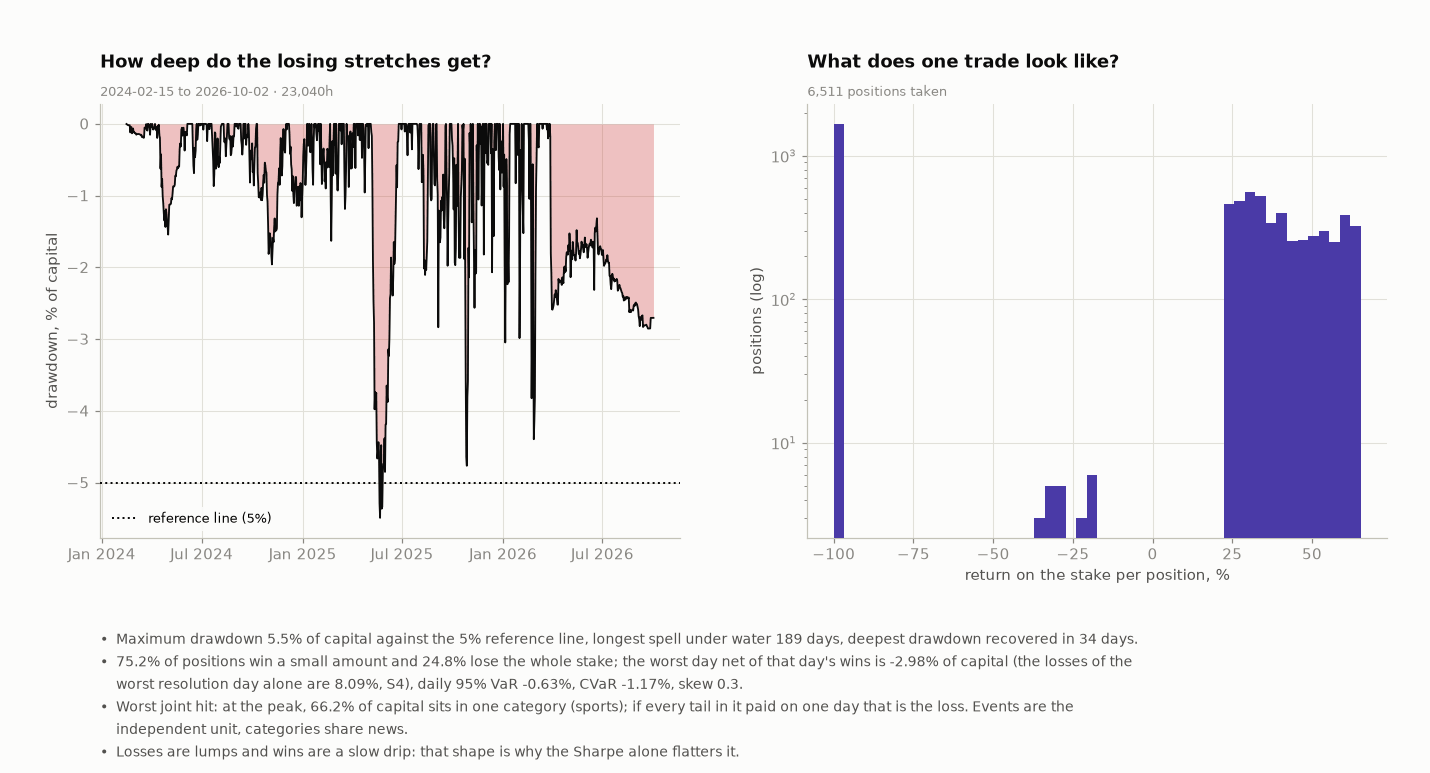

In [26]:
# ---- risk: drawdown path, the distribution of results, the worst joint hit ----
eq_ = 1.0 + np.cumsum(B_DAILY)
dd_ = (np.cumsum(B_DAILY) - np.maximum.accumulate(np.concatenate(([0.0], np.cumsum(B_DAILY))))[1:]) * 100     # points of capital, the engine's own max_dd
TS_ = ST.tail_stats(list(B_DAILY), 0.95)
SP = ST.drawdown_spells(list(eq_), list(idx_days.to_pydatetime()))
DDD = ST.max_dd_days(list(eq_), list(idx_days.to_pydatetime())); REC = ST.recovery_days(list(eq_), list(idx_days.to_pydatetime()))
EXPO, EXPO_G = EN.exposure_by_group(B_ACC, CLIP)
LOSSES = sorted([x for x in B_ACC if x["ret"] < 0], key=lambda x: x["pnl"] * CLIP / x["coll"])
WORST_USDPCT = LOSSES[0]["pnl"] * CLIP / LOSSES[0]["coll"] * 100 if LOSSES else 0.0
G_DD = B_ST["max_dd"] <= DD_LIMIT
BUL = [f"Maximum drawdown {B_ST['max_dd'] * 100:.1f}% of capital against the {DD_LIMIT:.0%} reference line, longest spell under water {DDD:.0f} days, deepest drawdown recovered in {REC:.0f} days." if REC == REC else f"Maximum drawdown {B_ST['max_dd'] * 100:.1f}% of capital against the {DD_LIMIT:.0%} reference line, longest spell under water {DDD:.0f} days; the deepest drawdown has not recovered.",
       f"{pct(1 - SUM['hit'])} of positions win a small amount and {pct(SUM['hit'])} lose the whole stake; the worst day net of that day's wins is {B_ST['worst_day'] * 100:+.2f}% of capital (the losses of the worst resolution day alone are {WORST_LOSS * 100:.2f}%, S4), daily 95% VaR {TS_['VaR 95%'] * 100:+.2f}%, CVaR {TS_['CVaR 95%'] * 100:+.2f}%, skew {TS_['skew']:.1f}.",
       f"Worst joint hit: at the peak, {EXPO * 100:.1f}% of capital sits in one category ({EXPO_G}); if every tail in it paid on one day that is the loss. Events are the independent unit, categories share news.",
       "Losses are lumps and wins are a slow drip: that shape is why the Sharpe alone flatters it."]
fig, gs, top = mkfig(4.8, BUL, ncols=2, wspace=0.22)
ax = fig.add_subplot(gs[0, 0])
ax.fill_between(idx_days, dd_, 0, color=CRIT, alpha=0.30, zorder=2, linewidth=0); ax.plot(idx_days, dd_, color=INK, linewidth=1.2, zorder=3)
ax.axhline(-DD_LIMIT * 100, color=INK, linewidth=1.3, linestyle=":", zorder=4, label=f"reference line ({DD_LIMIT:.0%})")
ax.set_ylabel("drawdown, % of capital"); ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7))); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.legend(loc="lower left", fontsize=8.5, **LEG)
ask(ax, "How deep do the losing stretches get?", f"{iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h")
ax = fig.add_subplot(gs[0, 1])
rets_ = np.array([x["ret"] for x in B_ACC]) * 100
ax.hist(rets_, bins=50, color=C_NET, zorder=3); ax.set_yscale("log"); ax.set_xlabel("return on the stake per position, %"); ax.set_ylabel("positions (log)")
ax.set_title("What does one trade look like?", loc="left", pad=24, fontsize=11.5, fontweight="bold")
ax.text(0.0, 1.012, f"{len(B_ACC):,} positions taken", transform=ax.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s5-risk", FIGURES)

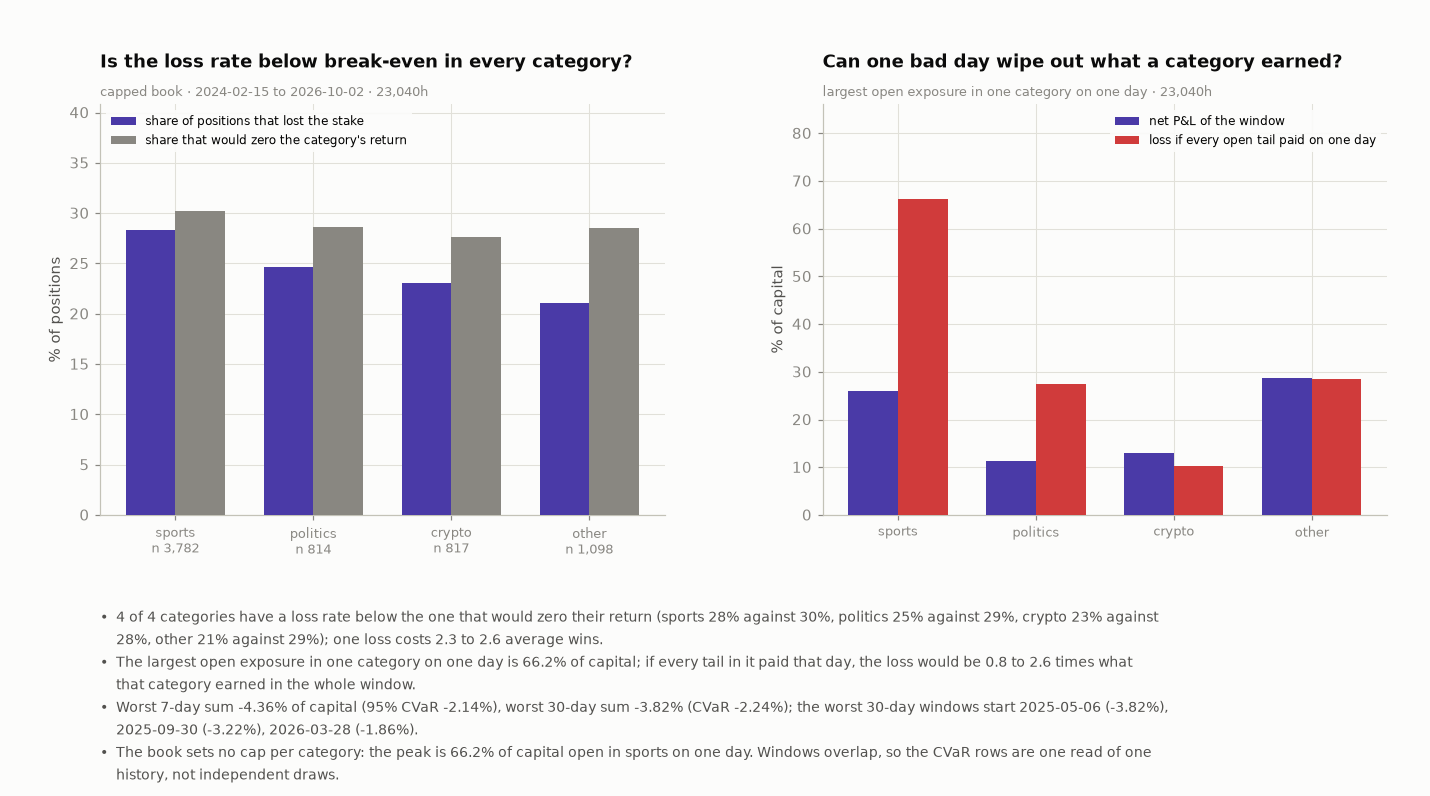

In [27]:
# ---- the cap test: worst-case loss against the premium collected, per category; and the worst N periods ----
CAT = {}
for g_ in GROUPS:
    s_ = [x for x in B_ACC if x["grp"] == g_]
    if len(s_) < 30:
        continue
    win_ = [x["ret"] for x in s_ if x["ret"] > 0]; los_ = [x["ret"] for x in s_ if x["ret"] < 0]
    gain_, loss_ = float(np.mean(win_)) if win_ else 0.0, -float(np.mean(los_)) if los_ else 0.0
    cnt_ = {}
    for x in s_:
        for d_ in range(int(x["t_in"] // DAYSEC), int(x["t_out"] // DAYSEC) + 1):
            cnt_[d_] = cnt_.get(d_, 0) + 1
    CAT[g_] = dict(n=len(s_), prem=sum(CLIP * r_ for r_ in win_), lost=sum(CLIP * r_ for r_ in los_), p=len(los_) / len(s_), q=(gain_ / (gain_ + loss_)) if gain_ + loss_ > 0 else float("nan"),
                   need=(loss_ / gain_) if gain_ > 0 else float("nan"), joint=max(cnt_.values()) * CLIP, worst_pos=(-min(los_) * CLIP) if los_ else 0.0)
    CAT[g_]["net"] = CAT[g_]["prem"] + CAT[g_]["lost"]; CAT[g_]["cover"] = CAT[g_]["joint"] / CAT[g_]["net"] if CAT[g_]["net"] > 0 else float("inf")
INSIDE = [g_ for g_, c_ in CAT.items() if c_["p"] < c_["q"]]
G_CAT = len(INSIDE) == len(CAT)
W7, W30 = RK.rolling_sums(B_DAILY, 7), RK.rolling_sums(B_DAILY, 30)
TS7, TS30 = ST.tail_stats(list(W7), 0.95), ST.tail_stats(list(W30), 0.95)
WW30 = RK.worst_windows(B_DAILY, 30, 3)
d_at = lambda i_: dt.datetime.fromtimestamp((B_D0 + i_) * DAYSEC, dt.timezone.utc).strftime("%Y-%m-%d")
CAT_TXT = ", ".join("%s %.0f%% against %.0f%%" % (g_, c_["p"] * 100, c_["q"] * 100) for g_, c_ in CAT.items())
BUL = [f"{len(INSIDE)} of {len(CAT)} categories have a loss rate below the one that would zero their return ({CAT_TXT}); one loss costs {min(c_['need'] for c_ in CAT.values()):.1f} to {max(c_['need'] for c_ in CAT.values()):.1f} average wins.",
       f"The largest open exposure in one category on one day is {max(c_['joint'] for c_ in CAT.values()) * 100:.1f}% of capital; if every tail in it paid that day, the loss would be {min(c_['cover'] for c_ in CAT.values()):.1f} to {max(c_['cover'] for c_ in CAT.values()):.1f} times what that category earned in the whole window.",
       f"Worst 7-day sum {TS7['worst'] * 100:+.2f}% of capital (95% CVaR {TS7['CVaR 95%'] * 100:+.2f}%), worst 30-day sum {TS30['worst'] * 100:+.2f}% (CVaR {TS30['CVaR 95%'] * 100:+.2f}%); the worst 30-day windows start " + ", ".join(f"{d_at(i_)} ({s_ * 100:+.2f}%)" for i_, s_ in WW30) + ".",
       f"The book sets no cap per category: the peak is {max(c_['joint'] for c_ in CAT.values()) * 100:.1f}% of capital open in {max(CAT, key=lambda g_: CAT[g_]['joint'])} on one day. Windows overlap, so the CVaR rows are one read of one history, not independent draws."]
fig, gs, top = mkfig(4.6, BUL, ncols=2, wspace=0.28)
ax = fig.add_subplot(gs[0, 0]); xs_c = np.arange(len(CAT)); w_ = 0.36
ax.bar(xs_c - w_ / 2, [c_["p"] * 100 for c_ in CAT.values()], width=w_, color=C_NET, zorder=3, label="share of positions that lost the stake")
ax.bar(xs_c + w_ / 2, [c_["q"] * 100 for c_ in CAT.values()], width=w_, color=C_COST, zorder=3, label="share that would zero the category's return")
ax.set_xticks(xs_c); ax.set_xticklabels([f"{g_}\nn {c_['n']:,}" for g_, c_ in CAT.items()], fontsize=8.5); ax.set_ylabel("% of positions"); ax.legend(loc="upper left", fontsize=8, **LEG); ax.set_ylim(0, max(max(c_["q"] for c_ in CAT.values()) * 100 * 1.35, 10))
ask(ax, "Is the loss rate below break-even in every category?", f"capped book · {iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} · {HOURS:,.0f}h")
ax = fig.add_subplot(gs[0, 1])
ax.bar(xs_c - w_ / 2, [c_["net"] * 100 for c_ in CAT.values()], width=w_, color=C_NET, zorder=3, label="net P&L of the window")
ax.bar(xs_c + w_ / 2, [c_["joint"] * 100 for c_ in CAT.values()], width=w_, color=CRIT, zorder=3, label="loss if every open tail paid on one day")
ax.set_xticks(xs_c); ax.set_xticklabels(list(CAT), fontsize=8.5); ax.set_ylabel("% of capital"); ax.set_ylim(0, max(c_["joint"] for c_ in CAT.values()) * 100 * 1.3); ax.legend(loc="upper right", fontsize=8, **LEG)
ax.set_title("Can one bad day wipe out what a category earned?", loc="left", pad=24, fontsize=11.5, fontweight="bold")
ax.text(0.0, 1.012, f"largest open exposure in one category on one day · {HOURS:,.0f}h", transform=ax.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s5-cap", FIGURES)

## S6 · Decision

n/a - no position; the implications for a strategy study are rendered below.

In [28]:
# ---- what a strategy study would have to settle, rendered from this run ----
TIER_RND = [(t_, r_, c_) for t_, nm_, r_, c_ in TIER_ROWS if nm_ == "random draw"]
THIN = [x_ for x_ in TIER_RND if x_[0][1] <= 5e4]; THICK = [x_ for x_ in TIER_RND if x_[0][0] >= 5e4]
IMPL = [f"The premium is there: the YES side was priced {PREM_MEAN * 100:+.1f} points above how often it paid (interval {PREM_LO * 100:+.1f} to {PREM_HI * 100:+.1f}). An entry earned {SUM['ret'] * 100:+.1f}% after costs; the reference book, which took {len(B_ACC):,} of them, earned {BOOK_S['ret'] * 100:+.1f}% a position and {ANN * 100:+.1f}% a year on capital against the T-bill's {HURDLE * 100:.2f}%.",
        f"It lives in the markets that trade least: final volume under USD 50,000 returns {EN.summ([x for x in BASE if x['vol'] < 5e4])['ret'] * 100:+.1f}% an entry, USD 50,000 and more {LIQ_S['ret'] * 100:+.1f}% (interval {LIQ_CI[1] * 100:+.1f} to {LIQ_CI[2] * 100:+.1f}). Whether a thin market's printed price is a price anyone would trade at is the question the history cannot answer.",
        f"The rule matters less than the market: {SH_BOTH * 100:.0f}% of the {len(DF):,} grid books beat the T-bill in both halves, though the first half does not rank the later half (rank correlation {RANK_RHO:.2f}), so this grid cannot pick a rule. Later-half medians: {CC_TXT}; {SL_TXT}. A cap deploys less capital, so it gives up return a year; whether it buys a smaller worst day is for the strategy study to test.",
        f"The losses cluster: {len(BASE):,} entries are {CLU_D['by event'][2]:,.0f} independent bets by event and {CLU_D['by resolution week'][2]:,.0f} by resolution week, and the worst resolution day lost {WORST_LOSS * 100:.2f}% of capital. A strategy needs a cap per category: the reference book had {max(c_['joint'] for c_ in CAT.values()) * 100:.0f}% of capital open in {max(CAT, key=lambda g_: CAT[g_]['joint'])} at the peak.",
        f"Only the YES side: selling the second outcome token has its interval wholly below zero in {N1_DN} of {len(S1_)} price bands (S4, sides).",
        "If it were reopened, a strategy study would have to fix, before it runs: the band, the exit, the category cap, the clip and the limits; test it on the markets a live book can fill (a forward ledger of live books, graded after settlement, is the only read of that); and deflate its Sharpe for every rule it tries."]
display(Markdown("\n".join(f"- {s_}" for s_ in IMPL)))

- The premium is there: the YES side was priced +5.5 points above how often it paid (interval +4.7 to +6.2). An entry earned +6.4% after costs; the reference book, which took 6,511 of them, earned +4.8% a position and +29.9% a year on capital against the T-bill's 4.11%.
- It lives in the markets that trade least: final volume under USD 50,000 returns +9.7% an entry, USD 50,000 and more -2.0% (interval -4.2 to +0.1). Whether a thin market's printed price is a price anyone would trade at is the question the history cannot answer.
- The rule matters less than the market: 100% of the 256 grid books beat the T-bill in both halves, though the first half does not rank the later half (rank correlation 0.00), so this grid cannot pick a rule. Later-half medians: cap 20%: Sharpe 3.70, +58% a year, cap none: Sharpe 4.31, +87% a year; stop 0.80: Sharpe 3.82, +65% a year, stop none: Sharpe 4.17, +72% a year. A cap deploys less capital, so it gives up return a year; whether it buys a smaller worst day is for the strategy study to test.
- The losses cluster: 9,499 entries are 9,107 independent bets by event and 5,447 by resolution week, and the worst resolution day lost 8.09% of capital. A strategy needs a cap per category: the reference book had 66% of capital open in sports at the peak.
- Only the YES side: selling the second outcome token has its interval wholly below zero in 8 of 8 price bands (S4, sides).
- If it were reopened, a strategy study would have to fix, before it runs: the band, the exit, the category cap, the clip and the limits; test it on the markets a live book can fill (a forward ledger of live books, graded after settlement, is the only read of that); and deflate its Sharpe for every rule it tries.

## S7 · Verdict - what we conclude

In [29]:
# ---- GATES: every gate as data; the table and the manifest render from it ----
g_ = lambda **k: k
GROSS_D, _, _ = book(run(MK_R, BAND, slip=0.0)); GROSS_ANN = EN.stats(GROSS_D, rf=HURDLE)["ann_ret"] * 100   # the cost-free book, for the cost split
G_CLUSTER = CL_LO > 0
THIN_S = EN.summ([x for x in BASE if x["vol"] < 5e4])
GATES = [
    g_(section="S2", label="Data reconciles", name="the counts fall at every filter, every settlement is 1/0 or 0.5/0.5, every history is ordered and inside 0..1", reading=f"{n_hist:,} histories, {n_empty:,} empty dropped, {VER['passed']} books verified", verdict="PASS", would_change="a settlement outside 1/0 or 0.5/0.5, or a history out of order"),
    g_(section="S2", label="Sampled at random", name="outcomes are read on a random draw; volume is not used to pick markets", reading=f"gap {GAP_R * 100:+.1f} pt random, {GAP_H * 100:+.1f} pt most-traded", verdict="INFO", would_change="a draw that is not random in the order it was pulled"),
    g_(section="S2", label="Survivorship bound", name="the mean return stays above zero if every dropped market that would have entered lost its whole stake", reading=f"worst case {SURV_HEAD * 100:+.1f}% an entry; the dropped entrants must lose the stake {SURV_Q * 100:.0f}% of the time to erase it, the sample {P0 * 100:.0f}%", verdict="PASS" if SURV_OK else "FLAG", would_change="the dropped rows kept in the inputs, with category and price"),
    g_(section="S2", label="No look-ahead in entry", name="the entries do not change when outcomes or final volumes are permuted or the history is cut at the entry print, and every planted leak is caught", reading=f"rule as run: {LEAK_MAX * 100:.0f}% of {LEAK[LEAK_NAMES[0]]['n_entries']:,} entries change; planted leaks caught {sum(CAUGHT)} of {len(CAUGHT)}", verdict="PASS" if G_LEAK else "FAIL", would_change="a rule that reads a forbidden field or a later print"),
    g_(section="S3", label="YES priced above pay", name="price minus how often it paid in the band is above zero, event-cluster interval excludes zero", reading=f"{PREM_MEAN * 100:+.1f} pt, interval {PREM_LO * 100:+.1f} to {PREM_HI * 100:+.1f}", verdict="PASS" if G_CAL else "FAIL", would_change="another window or a sample with no thin markets"),
    g_(section="S3", label="Reference beats T-bill", name="held to resolution after costs at no leverage, the reference book ends above the T-bill", reading=f"{ANN * 100:+.1f}% a year on capital, Sharpe over the T-bill {B_ST['sharpe_ex']:.2f}", verdict="PASS" if G_BASE else "FAIL", would_change="a half-spread above the sweep's break-even"),
    g_(section="S4", label="Holds on the later half", name="the later half of the entries is above the T-bill with its interval above zero", reading=f"{S_H2['ann_ret'] * 100:+.1f}% a year, {M_H2['ret'] * 100:+.1f}% an entry", verdict="PASS" if G_OOS else "FAIL", would_change="a later regime"),
    g_(section="S4", label="Beyond luck", name="event p below the gate on the premium AND the month-block Sharpe interval above zero", reading=f"p {SF_P:.5f}, Sharpe over the T-bill {SH_LO:.2f} to {SH_HI:.2f}", verdict="PASS" if G_LUCK else "FAIL", would_change="a p that only the total passes"),
    g_(section="S4", label="Costs do not flip it", name="the stress half-spreads and the cheap end of the sweep keep it above the T-bill", reading=f"stress {ST_S['ann_ret'] * 100:+.1f}% a year; {BE_GATE} an entry, {BE_SH:.1f} cents for the book", verdict="PASS" if G_COST else "FAIL", would_change="live spreads wider than the stress case"),
    g_(section="S4", label="Cluster-aware interval", name="the lower end of the wider of the by-event and by-resolution-week intervals is above zero", reading=f"lower end {CL_LO * 100:+.1f}% an entry ({CL_WIDER}), {CLU_D['by event'][2]:,.0f} independent bets by event, {CLU_D['by resolution week'][2]:,.0f} by resolution week", verdict="PASS" if G_CLUSTER else "FAIL", would_change="more independent events"),
    g_(section="S4", label="Liquid markets", name="the markets with USD 50,000 and more of final volume clear the T-bill with the interval above zero", reading=f"{LIQ_S['ret'] * 100:+.1f}% an entry, interval {LIQ_CI[1] * 100:+.1f} to {LIQ_CI[2] * 100:+.1f}; under USD 50,000 {THIN_S['ret'] * 100:+.1f}%", verdict="PASS" if G_LIQ else "FAIL", would_change="the live book at entry (a forward ledger)"),
    g_(section="S4", label="Not one lucky rule", name=f"at least {SHARE_GATE:.0%} of the grid's books beat the T-bill in both halves", reading=f"{SH_BOTH * 100:.0f}% of {len(DF):,} books; first half {SH_TR * 100:.0f}%, later half {SH_TE * 100:.0f}%, rank correlation {RANK_RHO:.2f}", verdict="PASS" if G_GRID else "FAIL", would_change="a different grid"),
    g_(section="S4", label="Live books today", name="where today's candidates in the band sit, by volume so far, and what their quoted spread is", reading=f"{len(CAND):,} candidates: {len(LIVE_THIN):,} under USD 10k, {len(LIVE_MID):,} to 50k, {len(LIVE_BIG):,} above; median half-spread {G_LIVE_SPREAD * 100:.1f} cents on {len(LIQ_C):,} liquid ones against {ASSUMED * 100:.1f} assumed", verdict="INFO", would_change="the book at another hour"),
    g_(section="S5", label="Category loss cap", name="in every category the loss rate is below the one that would zero its return", reading=f"{len(INSIDE)} of {len(CAT)} inside, no cap per category is set; largest one-day open exposure in a category {max(c_['joint'] for c_ in CAT.values()) * 100:.1f}% of capital", verdict="PASS" if G_CAT else "FLAG", would_change="a category with a higher loss rate"),
]
for n_, g1_ in enumerate(GATES):
    g1_["id"] = f"G{n_}"
assert all(g1_["verdict"] in REPORT.GATE_VERDICTS for g1_ in GATES) and all(len(g1_["label"]) <= 24 for g1_ in GATES)
GV_ = {g1_["label"]: g1_["verdict"] for g1_ in GATES}
CORE = ("YES priced above pay", "Holds on the later half", "Beyond luck", "Costs do not flip it", "Cluster-aware interval")
CORE_FAILED = [k_ for k_ in CORE if GV_[k_] != "PASS"]
WORD = "NOT SHOWN" if CORE_FAILED else ("WORTH A STUDY" if GV_["Liquid markets"] == "PASS" else "THIN MARKETS ONLY")
display(Markdown("| Gate | Section | Test | Reading | Verdict |\n|---|---|---|---|---|\n" + "\n".join(f"| {g1_['id']} {g1_['label']} | {g1_['section']} | {g1_['name']} | {g1_['reading']} | **{g1_['verdict']}** |" for g1_ in GATES)))

| Gate | Section | Test | Reading | Verdict |
|---|---|---|---|---|
| G0 Data reconciles | S2 | the counts fall at every filter, every settlement is 1/0 or 0.5/0.5, every history is ordered and inside 0..1 | 35,182 histories, 1,739 empty dropped, 269 books verified | **PASS** |
| G1 Sampled at random | S2 | outcomes are read on a random draw; volume is not used to pick markets | gap +6.1 pt random, -3.2 pt most-traded | **INFO** |
| G2 Survivorship bound | S2 | the mean return stays above zero if every dropped market that would have entered lost its whole stake | worst case +0.5% an entry; the dropped entrants must lose the stake 107% of the time to erase it, the sample 25% | **PASS** |
| G3 No look-ahead in entry | S2 | the entries do not change when outcomes or final volumes are permuted or the history is cut at the entry print, and every planted leak is caught | rule as run: 0% of 9,499 entries change; planted leaks caught 4 of 4 | **PASS** |
| G4 YES priced above pay | S3 | price minus how often it paid in the band is above zero, event-cluster interval excludes zero | +5.5 pt, interval +4.7 to +6.2 | **PASS** |
| G5 Reference beats T-bill | S3 | held to resolution after costs at no leverage, the reference book ends above the T-bill | +29.9% a year on capital, Sharpe over the T-bill 2.56 | **PASS** |
| G6 Holds on the later half | S4 | the later half of the entries is above the T-bill with its interval above zero | +50.9% a year, +6.2% an entry | **PASS** |
| G7 Beyond luck | S4 | event p below the gate on the premium AND the month-block Sharpe interval above zero | p 0.00025, Sharpe over the T-bill 1.59 to 3.57 | **PASS** |
| G8 Costs do not flip it | S4 | the stress half-spreads and the cheap end of the sweep keep it above the T-bill | stress +16.5% a year; break-even 5.4 cents an entry, 4.0 cents for the book | **PASS** |
| G9 Cluster-aware interval | S4 | the lower end of the wider of the by-event and by-resolution-week intervals is above zero | lower end +5.0% an entry (by resolution week), 9,107 independent bets by event, 5,447 by resolution week | **PASS** |
| G10 Liquid markets | S4 | the markets with USD 50,000 and more of final volume clear the T-bill with the interval above zero | -2.0% an entry, interval -4.2 to +0.1; under USD 50,000 +9.7% | **FAIL** |
| G11 Not one lucky rule | S4 | at least 75% of the grid's books beat the T-bill in both halves | 100% of 256 books; first half 100%, later half 100%, rank correlation 0.00 | **PASS** |
| G12 Live books today | S4 | where today's candidates in the band sit, by volume so far, and what their quoted spread is | 4,685 candidates: 4,301 under USD 10k, 234 to 50k, 150 above; median half-spread 0.5 cents on 214 liquid ones against 1.0 assumed | **INFO** |
| G13 Category loss cap | S5 | in every category the loss rate is below the one that would zero its return | 4 of 4 inside, no cap per category is set; largest one-day open exposure in a category 66.2% of capital | **PASS** |

In [30]:
# ---- the conclusion, rendered from the run (no typed numbers) ----
LOOKS = EXPLORED_SLICES + len(DF) + len(SW) + 1 + len(TIER_ROWS) + 2 + len(HOLD_ROWS) + sum(len(r_) for _, r_ in KINDS) + len(SIDE_ROWS) + len(QROWS)
MEANING = {"WORTH A STUDY": "the premium is there and it holds in the liquid markets too: a strategy study is worth opening.",
           "THIN MARKETS ONLY": "the premium is there and it is not luck, but it sits in the markets that trade least: a strategy study is worth opening only if it can show a live book fills there.",
           "NOT SHOWN": f"the premium is not shown: {', '.join(CORE_FAILED)} did not pass."}[WORD]
VERDICT_MD = "\n".join([
    "**Closed.** The owner closed this strategy on 2026-10-06: it will not go to a strategy study or to production.", "",
    f"**Verdict: {WORD}.** Window {iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]} ({DAYS:.0f} days, one regime), {VER['passed']}/{VER['total']} book checks. {MEANING[0].upper() + MEANING[1:]}", "",
    f"**The thesis, tested.** The YES side was priced above how often it paid ({PREM_MEAN * 100:+.1f} points, interval {PREM_LO * 100:+.1f} to {PREM_HI * 100:+.1f}: {'held' if G_CAL else 'refuted'}); the book beat the T-bill after costs ({ANN * 100:+.1f}% a year against {HURDLE * 100:.2f}%: {'held' if G_BASE else 'refuted'}); selling the NO side lost in {N1_DN} of {len(S1_)} price bands ({'held' if N1_UP == 0 else 'refuted'}). "
    f"It did not hold in markets of USD 50,000 and more ({LIQ_S['ret'] * 100:+.1f}% an entry), so the effect is shown and the strategy is not.", "",
    f"**The effect.** On this window the YES side of a Polymarket market was priced {PREM_MEAN * 100:+.1f} points above how often it paid. Selling the first outcome token the first time it trades in {BAND[0]:.0%} to {BAND[1]:.0%} and holding to resolution earned {SUM['ret'] * 100:+.1f}% an entry after costs over {SUM['n']:,} entries in {SUM['events']:,} events "
    f"({pct(SUM['px'])} priced, {pct(SUM['hit'])} paid). The reference book took {len(B_ACC):,} of them under its caps; they returned {BOOK_S['ret'] * 100:+.1f}% each and {ANN * 100:+.1f}% a year on capital at a Sharpe over the T-bill of {B_ST['sharpe_ex']:.2f}, with {EXIT_SHARE * 100:.0f}% of them closing between 2025-11-01 and the walk cut. It does not need the tail: the gap is there from the middle of the price range, and the largest gap is {max(PRICE - HIT) * 100:.1f} points.", "",
    f"**Is it real.** The premium by whole events has a p of {SF_P:.5f}; the lower end of the wider {CI_PCT}% interval on the mean return per entry is {CL_LO * 100:+.1f}%; the later half returns {M_H2['ret'] * 100:+.1f}% an entry; with every tier one step worse in half-spread the book still earns {ST_S['ann_ret'] * 100:+.1f}% a year, and it reaches the T-bill at about {BE:.1f} cents each way." if BE == BE else
    f"**Is it real.** The premium by whole events has a p of {SF_P:.5f}; the lower end of the wider {CI_PCT}% interval on the mean return per entry is {CL_LO * 100:+.1f}%; the later half returns {M_H2['ret'] * 100:+.1f}% an entry; with every tier one step worse in half-spread the book still earns {ST_S['ann_ret'] * 100:+.1f}% a year.", "",
    f"**Where it lives.** Final volume of USD 50,000 and more returns {LIQ_S['ret'] * 100:+.1f}% an entry (interval {LIQ_CI[1] * 100:+.1f} to {LIQ_CI[2] * 100:+.1f}); below it {THIN_S['ret'] * 100:+.1f}%. Final volume is known only afterwards and is higher where a tail paid, so the liquid tier is biased against the seller and the thin tiers in its favour; the history cannot say how much of the thin-market premium is a price nobody would trade at.", "",
    f"**Does the rule matter.** Over {len(DF):,} books of a fixed grid, {SH_BOTH * 100:.0f}% beat the T-bill in both halves, but the first half does not rank the later half (rank correlation {RANK_RHO:.2f}): the premium does not hang on the rule, and the grid cannot pick one. The choice with the widest spread of medians is the {NAMES_[BIGGEST]}. Later-half medians: {CC_TXT}; {SL_TXT}; {TM_TXT}; {TP_TXT}. A category cap deploys less capital, so it gives up return a year; whether it buys a smaller worst day is for a strategy study to test. None of the grid is a chosen rule.", "",
    f"**How long to hold.** Per day locked the edge falls with the horizon: " + "; ".join(f"{labs[i_]} {m_['per_day'] * 100:+.2f}%" for i_, (_, m_, _, _) in enumerate(HOLD_ROWS)) + f" a day against the T-bill's {HURDLE / 365 * 100:.3f}%.", "",
    f"**Clusters.** {len(BASE):,} entries are {CLU_D['by event'][2]:,.0f} independent bets by event and {CLU_D['by resolution week'][2]:,.0f} by resolution week. The worst resolution day lost {WORST_LOSS * 100:.2f}% of capital (the reference line is {DD_LIMIT:.0%}); the {TOP_K} worst events carry {SH_WORST * 100:.0f}% of all the loss. The reference book has no cap per category: at the peak {max(c_['joint'] for c_ in CAT.values()) * 100:.1f}% of capital was open in {max(CAT, key=lambda g_: CAT[g_]['joint'])}, and a full set of losses there would have cost {CAT[max(CAT, key=lambda g_: CAT[g_]['joint'])]['cover']:.1f} times what that category earned in the window.", "",
    f"**Dropped markets.** If every empty-history and unsettled market that would have entered had lost its whole stake, the mean return per entry would be {SURV_HEAD * 100:+.1f}%; the dropped entrants must lose the stake {SURV_Q * 100:.0f}% of the time to erase the edge, the sample {P0 * 100:.0f}%. Their category and price are not in the frozen inputs.", "",
    f"**Look-ahead.** The entry decision changes in {LEAK_MAX * 100:.0f}% of entries when outcomes or final volumes are permuted or every history is cut at its entry print, and the check caught all {len(CAUGHT)} planted leaks, among them the first build's end-of-history rule (it had lifted the mean entry from {SUM['ret'] * 100:+.1f}% to {OLD_S['ret'] * 100:+.1f}%). The costs still use the final volume, worth {(SUM['ret'] - float(np.mean(VOL_PLC))) * 100:+.2f} points an entry.", "",
    f"**The other side.** Selling the second outcome token (the NO side of a Yes/No market) loses: its interval is wholly below zero in {N1_DN} of {len(S1_)} price bands and wholly above zero in {N1_UP}. The trade is one-directional: sell the YES side, never the NO side. In markets named by two names the first-listed token returned {[m_['ret'] for l_, m_, c_ in KINDS[0][1] if l_ == 'two names'][0] * 100:+.1f}% an entry, interval {[c_[1] for l_, m_, c_ in KINDS[0][1] if l_ == 'two names'][0] * 100:+.1f} to {[c_[2] for l_, m_, c_ in KINDS[0][1] if l_ == 'two names'][0] * 100:+.1f}, so the rule is about Yes / No markets.", "",
    "**If it were reopened, a strategy study would have to settle.** (1) Whether a live book fills in the thin markets where the premium sits: a forward paper ledger on live books, graded after settlement. (2) A category cap and the other rule choices, fixed before it runs and tested on data this study did not read. (3) Volume at the time of entry, from trade records, instead of final volume. (4) The order book at the time (historical L2): the venue serves sampled prices only and its book can be read live, so it has to be recorded going forward; not done here. (5) A window outside this year.", "",
    f"**Looks counted.** {LOOKS} looks at this history were taken ({EXPLORED_SLICES} before the band was named, {len(DF):,} grid books, and the slices of S4). No Sharpe is deflated here because none is claimed as a strategy result; a strategy study counts these in its own deflation.", "",
    "**What could mislead us**", "",
    "- One window, one regime: the halves, quarters, tiers and grid re-slice the same days. Running this notebook again on the same frozen file is a new run of one window, not a replication: the window, the regime, the markets and the draw did not vary.",
    f"- Coverage is uneven in time: the closed-event walk was cut at {WALK_CUT} and is not in date order, so the {sum(1 for x_ in BASE if iso_(x_['t_out'])[:10] >= WALK_CUT):,} entries that resolve after it come only from the part read before the cut, and {sum(1 for x_ in BASE if '2025-11-01' <= iso_(x_['t_out'])[:10] < WALK_CUT) / len(BASE) * 100:.0f}% of all entries resolve between 2025-11-01 and the cut. The book is mostly that stretch, and markets that closed after the cut are not in it.",
    "- Final volume is an after-the-fact label (S2, S4): the tiers are biased in opposite directions and cannot settle tradability.",
    "- The history is a 12-hour sampled price, not a quote: a printed 0.30 on a market with no book is not a fill, and the half-spreads are assumptions taken from the live books of today.",
    f"- Not pre-registered: the token and the band were chosen after {EXPLORED_SLICES} slices of this same data were read (event type, size, horizon, category, year, half). The grid was fixed before it ran; its books share entries, so they are not independent.",
    "- A dispute or a slow redemption would lock the stake; the history holds none, so it is not measured here.",
    "- Orders are restricted from the UK: nothing here has been, or could be, traded from this seat.",
])
display(Markdown(VERDICT_MD))

**Closed.** The owner closed this strategy on 2026-10-06: it will not go to a strategy study or to production.

**Verdict: THIN MARKETS ONLY.** Window 2024-02-15 to 2026-10-02 (960 days, one regime), 269/269 book checks. The premium is there and it is not luck, but it sits in the markets that trade least: a strategy study is worth opening only if it can show a live book fills there.

**The thesis, tested.** The YES side was priced above how often it paid (+5.5 points, interval +4.7 to +6.2: held); the book beat the T-bill after costs (+29.9% a year against 4.11%: held); selling the NO side lost in 8 of 8 price bands (held). It did not hold in markets of USD 50,000 and more (-2.0% an entry), so the effect is shown and the strategy is not.

**The effect.** On this window the YES side of a Polymarket market was priced +5.5 points above how often it paid. Selling the first outcome token the first time it trades in 20% to 40% and holding to resolution earned +6.4% an entry after costs over 9,499 entries in 7,792 events (30.3% priced, 24.8% paid). The reference book took 6,511 of them under its caps; they returned +4.8% each and +29.9% a year on capital at a Sharpe over the T-bill of 2.56, with 56% of them closing between 2025-11-01 and the walk cut. It does not need the tail: the gap is there from the middle of the price range, and the largest gap is 9.4 points.

**Is it real.** The premium by whole events has a p of 0.00025; the lower end of the wider 90% interval on the mean return per entry is +5.0%; the later half returns +6.2% an entry; with every tier one step worse in half-spread the book still earns +16.5% a year, and it reaches the T-bill at about 5.4 cents each way.

**Where it lives.** Final volume of USD 50,000 and more returns -2.0% an entry (interval -4.2 to +0.1); below it +9.7%. Final volume is known only afterwards and is higher where a tail paid, so the liquid tier is biased against the seller and the thin tiers in its favour; the history cannot say how much of the thin-market premium is a price nobody would trade at.

**Does the rule matter.** Over 256 books of a fixed grid, 100% beat the T-bill in both halves, but the first half does not rank the later half (rank correlation 0.00): the premium does not hang on the rule, and the grid cannot pick one. The choice with the widest spread of medians is the category cap. Later-half medians: cap 20%: Sharpe 3.70, +58% a year, cap none: Sharpe 4.31, +87% a year; stop 0.80: Sharpe 3.82, +65% a year, stop none: Sharpe 4.17, +72% a year; time stop 30: Sharpe 4.15, +73% a year, time stop none: Sharpe 3.86, +62% a year; take-profit 0.05: Sharpe 3.96, +67% a year, take-profit hold: Sharpe 3.96, +69% a year. A category cap deploys less capital, so it gives up return a year; whether it buys a smaller worst day is for a strategy study to test. None of the grid is a chosen rule.

**How long to hold.** Per day locked the edge falls with the horizon: under 1 day +0.27%; 1 to 7 days +1.34%; 7 to 30 days +0.42%; 30 to 90 days +0.35%; 90 days and more +0.12% a day against the T-bill's 0.011%.

**Clusters.** 9,499 entries are 9,107 independent bets by event and 5,447 by resolution week. The worst resolution day lost 8.09% of capital (the reference line is 5%); the 10 worst events carry 1% of all the loss. The reference book has no cap per category: at the peak 66.2% of capital was open in sports, and a full set of losses there would have cost 2.6 times what that category earned in the window.

**Dropped markets.** If every empty-history and unsettled market that would have entered had lost its whole stake, the mean return per entry would be +0.5%; the dropped entrants must lose the stake 107% of the time to erase the edge, the sample 25%. Their category and price are not in the frozen inputs.

**Look-ahead.** The entry decision changes in 0% of entries when outcomes or final volumes are permuted or every history is cut at its entry print, and the check caught all 4 planted leaks, among them the first build's end-of-history rule (it had lifted the mean entry from +6.4% to +7.4%). The costs still use the final volume, worth -0.02 points an entry.

**The other side.** Selling the second outcome token (the NO side of a Yes/No market) loses: its interval is wholly below zero in 8 of 8 price bands and wholly above zero in 0. The trade is one-directional: sell the YES side, never the NO side. In markets named by two names the first-listed token returned -0.7% an entry, interval -2.9 to +1.3, so the rule is about Yes / No markets.

**If it were reopened, a strategy study would have to settle.** (1) Whether a live book fills in the thin markets where the premium sits: a forward paper ledger on live books, graded after settlement. (2) A category cap and the other rule choices, fixed before it runs and tested on data this study did not read. (3) Volume at the time of entry, from trade records, instead of final volume. (4) The order book at the time (historical L2): the venue serves sampled prices only and its book can be read live, so it has to be recorded going forward; not done here. (5) A window outside this year.

**Looks counted.** 344 looks at this history were taken (35 before the band was named, 256 grid books, and the slices of S4). No Sharpe is deflated here because none is claimed as a strategy result; a strategy study counts these in its own deflation.

**What could mislead us**

- One window, one regime: the halves, quarters, tiers and grid re-slice the same days. Running this notebook again on the same frozen file is a new run of one window, not a replication: the window, the regime, the markets and the draw did not vary.
- Coverage is uneven in time: the closed-event walk was cut at 2026-04-01 and is not in date order, so the 233 entries that resolve after it come only from the part read before the cut, and 63% of all entries resolve between 2025-11-01 and the cut. The book is mostly that stretch, and markets that closed after the cut are not in it.
- Final volume is an after-the-fact label (S2, S4): the tiers are biased in opposite directions and cannot settle tradability.
- The history is a 12-hour sampled price, not a quote: a printed 0.30 on a market with no book is not a fill, and the half-spreads are assumptions taken from the live books of today.
- Not pre-registered: the token and the band were chosen after 35 slices of this same data were read (event type, size, horizon, category, year, half). The grid was fixed before it ran; its books share entries, so they are not independent.
- A dispute or a slow redemption would lock the stake; the history holds none, so it is not measured here.
- Orders are restricted from the UK: nothing here has been, or could be, traded from this seat.

In [31]:
# ---- the metrics the manifest carries (the evidence format), then the research summary card: every value read from the run's own objects above ----
PREMV = np.array([x["pe"] - x["y"] for x in BASE]); _evm = {}
for k_, v_ in zip([x["event"] for x in BASE], PREMV):
    _evm.setdefault(k_, []).append(v_)
MU_ = float(PREMV.mean()); SE_ = math.sqrt(sum((sum(v_) - len(v_) * MU_) ** 2 for v_ in _evm.values())) / len(PREMV)
T_STAT = MU_ / SE_
QPREM = [float(np.mean([x["pe"] - x["y"] for x in BASE if qkey(x["t_in"]) == q_])) for q_, _, _ in QROWS]
STABLE = 100.0 * sum(1 for v_ in QPREM if v_ > 0) / len(QPREM)
OOS_EFF = float(np.mean([x["pe"] - x["y"] for x in H2]))
assert abs(MU_ - PREM_MEAN) < 1e-12
METRICS = {"n_obs": int(SUM["n"]), "effect": MU_ * 100, "t_stat": T_STAT, "p_value": SF_P, "ci95_low": (MU_ - 1.96 * SE_) * 100, "ci95_high": (MU_ + 1.96 * SE_) * 100,
           "rho": None, "r2": None, "oos_effect": OOS_EFF * 100, "stable_share_pct": STABLE, "half_life_h": None, "n_regimes": 1}
NA = {"rho": "one series: no second series to correlate with", "r2": "as rho", "half_life_h": "a premium per entry, not a spread series with a half-life"}
eq_ = 1.0 + np.cumsum(B_DAILY)

from fundplat.quant.core import summary_card
GID = {g1_["label"]: g1_["id"] for g1_ in GATES}
GV = {g1_["id"]: g1_["verdict"] for g1_ in GATES}
vd_ = lambda ok_: "PASS" if ok_ else "FAIL"


def mk(metric, value, bar="", verdict="", key=None, gate=None):
    """One card row. A gate row takes its verdict from the gate (an N/A gate shows empty); a key row's value must equal the manifest metric at the decimals it shows."""
    r_ = {"metric": metric, "value": value, "bar": bar, "verdict": verdict}
    if gate is not None:
        r_["gate"] = GID[gate]
        r_["verdict"] = GV[GID[gate]] if GV[GID[gate]] in REPORT.CARD_VERDICTS else ""
    if key is not None:
        r_["key"] = key
    return r_


TBILL_POS = HURDLE * SUM["days"] / 365.0
TBILL_TXT = f"T-bill {HURDLE * 100:.2f}%"
CI_LIQ = f"90% CI {LIQ_CI[1] * 100:+.1f}% to {LIQ_CI[2] * 100:+.1f}%"
TIER_CI = {t_: c_ for t_, nm_, r_, c_ in TIER_ROWS if nm_ == "random draw"}
SIZE_ROWS = [[tier_lab(t_), f"{r_['n']:,}", f"{r_['ret'] * 100:+.1f}%", f"{TIER_CI[t_][1] * 100:+.1f}% to {TIER_CI[t_][2] * 100:+.1f}%",
              "PASS" if TIER_CI[t_][1] > 0 else ("FAIL" if TIER_CI[t_][2] < 0 else "FLAG")] for t_, nm_, r_, c_ in TIER_ROWS if nm_ == "random draw"]
assert SIZE_ROWS, "no volume tier has 30 entries"
CHOSEN = next((i_ for i_, (t_, nm_, r_, c_) in enumerate([x_ for x_ in TIER_ROWS if x_[1] == "random draw"]) if t_[0] >= 5e4), len(SIZE_ROWS) - 1)
CAT_ROWS = next(r_ for t_, r_ in KINDS if t_ == "Which category?")
QUESTION = "Does Polymarket charge too much for YES shares, and would selling them have made money after costs?"
ANSWER = {"WORTH A STUDY": f"{WORD}. The YES side was priced {PREM_MEAN * 100:+.1f} points above how often it paid; selling it earned {SUM['ret'] * 100:+.1f}% an entry and holds in markets of USD 50,000 and more ({LIQ_S['ret'] * 100:+.1f}%).",
          "THIN MARKETS ONLY": f"{WORD}. The YES side was priced {PREM_MEAN * 100:+.1f} points above how often it paid and selling it earned {SUM['ret'] * 100:+.1f}% an entry, but markets of USD 50,000 and more return {LIQ_S['ret'] * 100:+.1f}%. Closed by the owner: not taken to a strategy.",
          "NOT SHOWN": f"{WORD}. The premium is not shown: {', '.join(CORE_FAILED)} did not pass."}[WORD]
IMPL_CARD = [("Study", "Exploratory: an effect and a reference book, no chosen rule"), ("Sold", f"YES at its first 12 h print in {BAND[0]:.0%} to {BAND[1]:.0%}; hold to payout"), ("Venue", "Polymarket settled binary markets; paper only, UK orders restricted"),
             ("Capital", f"{CLIP:.2%} of capital a position, posted in full, no leverage"), ("Costs", f"Half-spread {min(s_ for _, s_ in SLIP_PRIMARY) * 100:.1f} to {max(s_ for _, s_ in SLIP_PRIMARY) * 100:.1f} cents by volume [U], no fee [1]"),
             ("Window", f"{iso_(T_ENTRY0)[:10]} to {iso_(T_EXIT1)[:10]}, {HOURS:,.0f} h; {EXIT_SHARE * 100:.0f}% close Nov 2025 to Mar 2026")]
BIG = [dict(mk("Price minus how often it paid, points", f"{METRICS['effect']:+.1f} pt", "above 0", gate="YES priced above pay", key="effect"), scope="20-40%"),
       dict(mk("Return an entry, after costs", f"{SUM['ret'] * 100:+.1f}%", f"T-bill {TBILL_POS * 100:+.1f}% in {SUM['days']:.0f} days", vd_(SUM["ret"] > TBILL_POS)), scope="entries"),
       dict(mk("Return a year on capital", f"{ANN * 100:+.1f}%", TBILL_TXT, gate="Reference beats T-bill"), scope="1x"),
       dict(mk("Return an entry, final volume USD 50k+", f"{LIQ_S['ret'] * 100:+.1f}%", CI_LIQ, gate="Liquid markets"), scope="USD 50k+")]
BLOCKS = [
    ("The premium", [mk("Entries in the band", f"{METRICS['n_obs']:,}", key="n_obs"), mk("Price minus how often it paid, points", f"{METRICS['effect']:+.1f} pt", "above 0", gate="YES priced above pay", key="effect"),
                     mk("t statistic, by whole events", f"{METRICS['t_stat']:.1f}", key="t_stat"), mk("p, premium by whole events", f"{SF_P:.5f}", f"below {P_GATE:.2f}", gate="Beyond luck"),
                     mk("Later half, price minus how often it paid", f"{METRICS['oos_effect']:+.1f} pt", "above 0", gate="Holds on the later half", key="oos_effect"),
                     mk("Quarters with a positive premium", f"{METRICS['stable_share_pct']:.0f}%", f"{len(QROWS)} quarters", key="stable_share_pct"),
                     mk("Tokens that expired worthless", f"{(1 - SUM['hit']) * 100:.1f}%", f"priced {SUM['px'] * 100:.1f}%")]),
    ("Reference book, after costs", [mk("Positions taken", f"{len(B_ACC):,}", f"of {SUM['n']:,} entries", "INFO"),
                     mk("Return a position taken", f"{BOOK_S['ret'] * 100:+.1f}%", f"T-bill {HURDLE * BOOK_S['days'] / 365 * 100:+.1f}% in {BOOK_S['days']:.0f} days", vd_(BOOK_S["ret"] > HURDLE * BOOK_S["days"] / 365)),
                     mk("Capital posted, average", f"{DEPLOYED * 100:.1f}%", f"cap {CAP:.0%}", "INFO"),
                     mk("Return a year on capital", f"{ANN * 100:+.1f}%", TBILL_TXT, gate="Reference beats T-bill"), mk("Return before costs, a year", f"{GROSS_ANN:+.1f}%"),
                     mk("Sharpe over the T-bill", f"{B_ST['sharpe_ex']:.2f}"), mk("Stress costs, a year on capital", f"{ST_S['ann_ret'] * 100:+.1f}%", TBILL_TXT, gate="Costs do not flip it"),
                     mk("Break-even half-spread, entry", f"{BE:.1f}" if BE == BE else "above 6", "cents each way"), mk("Break-even half-spread, book", f"{BE_SH:.1f}", "cents each way", "INFO")]),
    ("Is it real", [mk("Sharpe over the T-bill, 90% interval", f"{SH_LO:.2f} to {SH_HI:.2f}", "above 0", vd_(SH_LO > 0)), mk("Lower end, cluster interval", f"{CL_LO * 100:+.1f}%", "above 0", gate="Cluster-aware interval"),
                    mk("Independent bets, by event", f"{CLU_D['by event'][2]:,.0f}", f"of {len(BASE):,} entries", "INFO"), mk("Worst case, dropped markets lose", f"{SURV_HEAD * 100:+.1f}%", "above 0", gate="Survivorship bound"),
                    mk("Entries a leak check changes", f"{LEAK_MAX * 100:.0f}%", f"{sum(CAUGHT)} of {len(CAUGHT)} planted caught", gate="No look-ahead in entry"),
                    mk("Empty histories dropped", f"{N_EMPTY:,}", f"{N_EMPTY / DRAWN_R * 100:.1f}% of draw", "INFO")]),
    ("Where it lives", [mk("Return an entry, USD 50k+", f"{LIQ_S['ret'] * 100:+.1f}%", CI_LIQ, gate="Liquid markets"), mk("Return an entry, under USD 50k", f"{THIN_S['ret'] * 100:+.1f}%", "", "INFO"),
                                                                                                                                         mk("Live candidates under USD 10k", f"{len(LIVE_THIN) / max(1, len(CAND)) * 100:.0f}%", f"of {len(CAND):,} in the band", "INFO")]
                        + [mk(f"Return an entry, {l_}", f"{m_['ret'] * 100:+.1f}%", f"90% CI {c_[1] * 100:+.1f}% to {c_[2] * 100:+.1f}%", "INFO") for l_, m_, c_ in CAT_ROWS]),
    ("Does the rule matter", [mk("Books in the grid", f"{len(DF):,}", "every one kept", "INFO"), mk("Books above the T-bill, both halves", f"{SH_BOTH * 100:.0f}%", f"at least {SHARE_GATE:.0%}", gate="Not one lucky rule"),
                              mk("Rank correlation, early vs later", f"{RANK_RHO:.2f}", "", "INFO")]
                             + [mk(f"Category cap {a_}, later-half return", f"{m_ * 100:+.0f}%", TBILL_TXT, "INFO") for a_, _, m_, _, _ in DIMTAB["cc"]]),
    ("Risk, reference book", [mk("Maximum drawdown", f"{B_ST['max_dd'] * 100:.1f}%", f"line {DD_LIMIT:.0%}", vd_(B_ST["max_dd"] <= DD_LIMIT)), mk("Worst resolution day, losses only", f"-{WORST_LOSS * 100:.2f}%", f"line {DD_LIMIT:.0%}", vd_(WORST_LOSS <= DD_LIMIT)),
                              mk("Open in one category, peak", f"{EXPO * 100:.1f}%", "no cap set", gate="Category loss cap"), mk("Ten worst events, share of loss", f"{SH_WORST * 100:.0f}%", "", "INFO")]),
]
FOOT = ["Closed by the owner on 2026-10-06: not taken to a strategy study or to production.",
        f"Not shown: a tradable edge. In USD 50k+ markets an entry returns {LIQ_S['ret'] * 100:+.1f}% ({CI_LIQ}); final volume is known only afterwards.",
        f"Exploratory, nothing pre-registered, {LOOKS} looks at this history, none deflated. {VER['passed']}/{VER['total']} book checks. {HOURS:,.0f} h, 1 regime, one result. Inputs frozen and hashed."]
CARD = {"question": QUESTION, "answer": ANSWER, "implementation": IMPL_CARD, "big": BIG, "blocks": [{"title": t_, "rows": rows_} for t_, rows_ in BLOCKS],
        "sizes": {"cols": ["Final volume, USD", "Entries", "Return an entry", "90% interval", "Verdict"], "chosen": CHOSEN, "rows": SIZE_ROWS}, "footer": FOOT}
CARD_PROBLEMS = REPORT.card_problems(CARD, metrics={k_: (None if v_ is None else float(v_)) for k_, v_ in METRICS.items()}, gates={g1_["id"]: g1_ for g1_ in GATES}, word=WORD, carry=False)
assert not CARD_PROBLEMS, CARD_PROBLEMS

In [32]:
# ---- the study manifest fund.study/1 (evidence format, market kind), built and validated by fundplat.quant.core.report, emitted as ONE display output ----
PROFILE = {"market": "predmkts", "markets": ["predmkts"], "venues": ["polymarket"], "instruments": ["Polymarket Yes/No markets, first outcome token"], "bar": "12h"}
FAILS_ = [g1_ for g1_ in GATES if g1_["verdict"] in ("FAIL", "FLAG") and g1_["section"] in ("S3", "S4", "S5")]
WHY = {"Liquid markets": f"USD 50k+ markets return {LIQ_S['ret'] * 100:+.1f}% an entry (90% CI {LIQ_CI[1] * 100:+.1f}% to {LIQ_CI[2] * 100:+.1f}%)",
       "Category loss cap": f"no cap per category: {max(c_['joint'] for c_ in CAT.values()) * 100:.0f}% of capital open in {max(CAT, key=lambda g_: CAT[g_]['joint'])} at the peak"}
VERDICT = {"word": WORD, "why": [WHY.get(g1_["label"], f"{g1_['label']} did not pass") for g1_ in FAILS_[:3]] or ["every gate passed"],
           "next_bet": "none: closed by the owner on 2026-10-06, not taken to a strategy study or to production"}
CAVEATS = ["one window, one regime, one observation",
           f"exploratory: the band was chosen after {EXPLORED_SLICES} slices of this data were read; nothing pre-registered",
           f"{LOOKS} looks at this history, none deflated: a strategy study deflates",
           "final volume is an after-the-fact label: the tiers are biased in opposite directions",
           "12-hour sampled prices, not quotes: no historical book",
           "half-spreads are assumptions from today's live books [U]",
           f"the walk was cut at {WALK_CUT}, not in date order: most entries resolve 2025-11 to the cut",
           f"{N_EMPTY:,} empty-history and {N_UNSET:,} unsettled markets dropped: bounded in S2.1, not measured",
           "orders are restricted from the UK: nothing here has been traded",
           "inputs are one frozen, hashed file held outside the data store (B-0325)"]
assert all(len(c_) <= 110 for c_ in CAVEATS) and all(len(w_) <= 110 for w_ in VERDICT["why"]), [len(x_) for x_ in CAVEATS + VERDICT["why"]]
COMPS = [{"name": "premium before costs", "ann_pct": round(GROSS_ANN, 4)}, {"name": "costs (half-spread)", "ann_pct": round(ANN * 100 - GROSS_ANN, 4)}, {"name": "net return on capital", "ann_pct": round(ANN * 100, 4)}]
assert abs(COMPS[0]["ann_pct"] + COMPS[1]["ann_pct"] - COMPS[2]["ann_pct"]) < 1e-3
FIG_KIND = {"fig:s2-sampling": "calibration", "fig:s3-calibration": "calibration", "fig:s3-equity": "equity-curve", "fig:s4-halves": "out-of-sample-test", "fig:s4-luck": "significance-test",
            "fig:s4-costs": "cost-sensitivity", "fig:s4-liquidity": "regime-and-concentration", "fig:s4-kinds": "regime-and-concentration", "fig:s4-sides": "rule-comparison",
            "fig:s4-clusters": "significance-test", "fig:s4-periods": "regime-and-concentration", "fig:s4-hold": "rule-comparison", "fig:s4-rules-carry": "signal-and-outcome-scatter",
            "fig:s4-rule-dims": "rule-comparison", "fig:s4-candidates": "live-candidates", "fig:s5-risk": "drawdown-and-tail", "fig:s5-cap": "regime-and-concentration", "fig:s2-funnel": "sample-funnel-and-coverage"}
assert set(FIG_KIND) == {f_["id"] for f_ in FIGURES}, set(FIG_KIND) ^ {f_["id"] for f_ in FIGURES}
for f_ in FIGURES:
    f_["kind"] = FIG_KIND[f_["id"]]
INPUTS = HANDLE.pin_reads(f"study input: {STUDY_ID}", f"study:{STUDY_ID}")
INPUTS["unpinned"] += [{"what": f"polymarket closed-event walk and /prices-history (12-hour prints), frozen file {INPUT_NAME} sha256 {DIGEST[:16]}", "why": "predmkts history is not served by handle.pull (B-0325); the file is hashed and held in the research input folder"}]
eq_pts = [(t_.to_pydatetime(), float(v_)) for t_, v_ in zip(idx_days, eq_)]
HEAD_GATE = GID["YES priced above pay"]   # the gate that judges the headline (the list tones the Headline cell by its verdict)
STUDY = REPORT.build_manifest(
    id=STUDY_ID, kind="market", desk="lab/predmkts", title="Are YES shares on Polymarket systematically overpriced?",
    question=QUESTION,
    status="run", run={"executed": RUN_AT, "kernel": "ccvenv"}, inputs=INPUTS,
    window={"from": iso_(T_ENTRY0), "to": iso_(T_EXIT1), "hours": int(round(HOURS)), "regimes": 1},
    verify={"suite": "fundplat.quant.predmkts.tail_sell.verify_book", "passed": VER["passed"], "total": VER["total"], "books": VER["books"]},
    gates=[{k_: g1_[k_] for k_ in ("id", "section", "name", "label", "reading", "verdict", "would_change")} for g1_ in GATES], figures=FIGURES, verdict=VERDICT, caveats=CAVEATS,
    sections=REPORT.sections({"S6": "no position; implications only"}),
    headline={"metric": "price minus how often the YES side paid, in points", "label": "Premium, points", "value": round(METRICS["effect"], 3), "unit": "pt", "hurdle": 0, "gate": HEAD_GATE},
    components=COMPS, format="evidence", metrics=METRICS, na=NA, summary=CARD,
    equity=eq_pts, profile=PROFILE, book=None)
S0_HANDLE.update(Markdown(REPORT.summary_md(STUDY)))
display(REPORT.display_bundle(STUDY), raw=True)

study manifest fund.study/1: 14 gates, 18 figures, verdict THIN MARKETS ONLY

## A · Appendix

n/a - every table is shown in its section.

## Research summary

In [33]:
M_ = STUDY["metrics"]
assert abs(M_["effect"] - PREM_MEAN * 100) < 1e-9 and abs(M_["t_stat"] - T_STAT) < 1e-9
assert [g1_["verdict"] for g1_ in STUDY["gates"]] == [g1_["verdict"] for g1_ in GATES] and STUDY["verdict"]["word"] == WORD and len(STUDY["figures"]) == len(FIGURES)
import json
assert STUDY["summary"] == json.loads(json.dumps(CARD)) and not REPORT.card_problems(STUDY["summary"], metrics=STUDY["metrics"], gates={g1_["id"]: g1_ for g1_ in STUDY["gates"]}, word=WORD, carry=False)
display(HTML(summary_card.render(CARD, carry=False)))

"Final volume, USD",Entries,Return an entry,90% interval,Verdict
"1,000 to 10,000","3,882",+12.6%,+11.0% to +14.2%,PASS
"10,000 to 50,000","2,889",+6.0%,+3.8% to +7.7%,PASS
"50,000 to 200,000","1,640",-3.0%,-5.6% to -0.1%,FAIL
"200,000 and up","1,088",-0.5%,-3.9% to +2.8%,FLAG
